# The Escape System, Self-Contained

This notebook explains how the base game turns a restraint's escape numbers into an actual escape attempt. It is written for someone who wants to choose numbers deliberately, rather than by trial and error.

The engine code is the base-game implementation (commit 60b41e14d, game 5.5.4), copied into a single JavaScript cell and run in the browser. The aggregate is handed to Python, which uses matplotlib for the figures. If the browser cannot hand the data over, Python uses an aggregate produced by the same engine at build time; the notebook still runs under nbconvert.

The notebook has three parts. Sections 1 to 3 establish the vocabulary and run the model. Sections 4 to 10 present the evidence one figure at a time. Sections 11 and 12 turn that evidence into design advice and state the model's limits.


## 1. Notation and the one idea that matters

The engine's field name, escapeChance, is misleading. It is not a probability and the engine never rolls a die against it. A restraint is removed when its progress reaches 1; the field controls how fast progress grows. Table 1 fixes the symbols used everywhere below.

| Symbol | Meaning | Where it comes from |
| --- | --- | --- |
| tick | One game turn. | The engine's time step. |
| action | One player input: Struggle, Remove, Cut, Pick or Unlock. | A click in the struggle panel. |
| T | Number of ticks scheduled by one action. | Four by default (KDStruggleTime). |
| p | Accumulated progress. Escape happens at p = 1. | struggleProgress or cutProgress. |
| e0 | The raw value written in the restraint template. | escapeChance[type] in the content file. |
| e | The effective rate coefficient after every modifier. | The engine's calculation. |
| lim | The hard cap on progress. | limitChance[type]. |
| minSpeed | The floor applied to e. | 0.4 by default; a template may override it. |
| p-star | The early-success threshold, 1 - e/T. | Checked when an action starts. |
| edge bonus | An affinity bonus of roughly 0.096 when the limbs are free. | The affinity override and edge bonus. |
| limit trap | The case lim > e, where progress stops at 0.9 e / lim. | The limit block in the engine. |

Read the rest of the notebook with this model in mind: an attempt is a short race. One action schedules T ticks; each tick adds a small amount to p; the race is won when p reaches 1 (or, at the start of an action, when p has already reached p-star). The quantity e only sets the speed. The consequence is that most restraints are not "30% likely"; they are either feasible or not, and the feasible ones finish in one or two actions.


## 2. Running the engine

The next cell contains the engine, a batch runner, and two ways of publishing the aggregate. It first tries the classic Notebook bridge, IPython.notebook.kernel.execute, which assigns the Python variable escape_results. If that object is not present, it tries the Jupyter contents API: it writes escape_results.json next to the notebook. If neither route is available, the Python cells fall back to the embedded aggregate.

The run covers the 486 shipped restraints for Struggle and Remove, plus a grid over e0 and lim, a Remove grid over body states, a one-factor-at-a-time sensitivity set, and three progress trajectories. It is about nine thousand simulated cases and typically takes a few seconds.


In [1]:
%%javascript
(function(){
"use strict";
let KDCutAdditionalLimitChance = 0.05;
let KDAllyLimitChanceRedMult = 0.5;
let KDAllyLimitChanceRedFlat = 0.05;
let KDAngelStruggleBonus = {
    Struggle: 0.12,
    Cut: 0.15,
    Remove: 0.20,
    Unlock: 0.25,
    Default: 0.1,
};
let KDBaseSpeedMult = {
    Struggle: 1.5,
    Remove: 2.0,
    Cut: 1.1,
    Unlock: 3.0,
    Pick: 1.0,
};
let KDWillEscapePenalty = 0.15;
let KDWillEscapePenaltyArms = 0.1;
let KDWillEscapePenaltyStart = 0.2;
let KDWillEscapePenaltyStartArms = 0.1;
let KDWillEscapePenaltyEnd = 0.05;
let KDMinEscapeRate = 0.4;
let KDMinPickRate = 0.2;
let KDStruggleTime = 4;
let KDBaseEscapeSpeed = 2.0;
let KDUpfrontWill = true;
let KinkyDungeonItemDropChanceArmsBound = 0.2; // Chance to drop item with just bound arms and not bound hands.
let KinkyDungeonKeyJamChance = 0.33;
let KinkyDungeonKeyPickBreakAmount = 12; // Number of tries per pick on average 5-11
let KinkyDungeonKeyPickBreakAmountBase = 12; // Number of tries per pick on average 5-11
let KinkyDungeonPickBreakProgress = 0;
let KinkyDungeonKnifeBreakAmount = 10; // Number of tries per knife on average 6-12
let KinkyDungeonKnifeBreakAmountBase = 10; // Number of tries per knife on average 6-12
let KinkyDungeonKnifeBreakProgress = 0;
let KinkyDungeonEnchKnifeBreakAmount = 24; // Number of tries per knife on average
let KinkyDungeonEnchKnifeBreakAmountBase = 24; // Number of tries per knife on average
let KinkyDungeonEnchKnifeBreakProgress = 0;
let KinkyDungeonMaxImpossibleAttempts = 3; // base, more if the item is close to being impossible
let KinkyDungeonEnchantedKnifeBonus = 0.1; // Bonus whenever you have an enchanted knife
let KDLocksmithPickBonus = 0.15; // Locksmith bonus to pick effectiveness
let KDLocksmithBonus = 0.15; // Locksmith bonus to base escape chance
let KDLocksmithSpeedBonus = 2.0;
let KDCluelessPickBonus = -0.2; // Clueless background
let KDCluelessBonus = -0.25; // Clueless background
let KDCluelessSpeedBonus = 0.5;
let KDFlexibleBonus = 0.1;
let KDFlexibleSpeedBonus = 1.5;
let KDInflexibleMult = 1.25;
let KDInflexibleSpeedBonus = 0.75;
let KDStrugglePerLevelBonus = 0.005;
let KDPainfulChoicePenalty = 0.5;
let KDPainfulChoiceBonus = 0.1;
let KDPainfulChoiceMax = 1.5;
let KDClearVisionBonus = 0.1;
let KDUnchainedBonus = 0.1;
let KDDamselBonus = 1.3;
let KDDamselPickAmount = 6;
let KDArtistBonus = 0.1;
let KDBunnyBonus = 1.3;
let KDBunnyKnifeAmount = 5;
let KDBunnyEnchKnifeAmount = 12;
let KDSlipperyBonus = 0.1;
let KDDollBonus = 1.3;
let KDEscapeeBonus = 0.1;
let KDDragonBonus = 1.3;
let KDStrongBonus = 0.075;
let KDWeakBonus = -0.1;
let KDBondageLoverAmount = 1;
let StruggleTypeHandThresh = {
    Struggle: 0.01, // Any hand bondage will affect struggling
    Unlock: 0.7, // Unlocking requires a bit of dexterity
    Pick: 0.45, // Picking requires dexterity
    Cut: 0.7, // Cutting requires a bit of dexterity
    Remove: 0.8, // Removing only requires a solid corner
};
let KDUnboundAffinityOverride = {
    "Sticky": true,
    "Edge": true,
    "Hook": true,
};
function KDGetTightnessEffect(escapeChance, struggleType, T = 0) {
    let mult = (struggleType == "Cut" || struggleType == "Remove") ? 0.5 : 1.0;
    let x1 = 1 - 0.1 * mult;
    let x2 = escapeChance > 0 ? (escapeChance - 0.03 * mult) / escapeChance : 0;
    let val = Math.max(x1, Math.min(x2, 1 - 0.05 * mult));
    val = 1 - (1 - val) * (100 / (100 + T));
    return val;
}
function KDGetWillPenalty(StruggleType) {
    let perc = KinkyDungeonStatWill; ///KinkyDungeonStatWillMax;
    let scale = 0;
    let scalestart = KDWillEscapePenaltyStart;
    let max = KDWillEscapePenalty;
    if (!KinkyDungeonIsArmsBound(true, undefined, undefined, true)) {
        scalestart = KDWillEscapePenaltyStartArms;
        max = KDWillEscapePenaltyArms;
    }
    if (perc < scalestart) {
        if (scalestart - KDWillEscapePenaltyEnd > 0)
            scale = Math.min(1.0, (scalestart - perc) / (scalestart - KDWillEscapePenaltyEnd));
        else if (perc <= 0)
            scale = 1.0;
    }
    return scale * max * ((StruggleType == "Cut") ? 0.5 : (StruggleType == "Struggle" ? 1.0 : 0.1));
}
function KinkyDungeonGetPickBonus() {
    let bonus = 0;
    if (KinkyDungeonStatsChoice.get("Locksmith"))
        bonus += KDLocksmithBonus;
    if (KinkyDungeonStatsChoice.get("Clueless"))
        bonus += KDCluelessBonus;
    if (KinkyDungeonStatsChoice.get("LocksmithMaster"))
        bonus += 0.15;
    return bonus;
}
function KDGetEscapeChance(restraint, StruggleType, escapeChancePre, limitChancePre, ApplyGhost, ApplyPlayerBonus, Msg) {
    let escapeChance = escapeChancePre != undefined ? escapeChancePre : KDRestraint(restraint).escapeChance[StruggleType] != undefined ? KDRestraint(restraint).escapeChance[StruggleType] : 1.0;
    if (KDGetCurse(restraint))
        escapeChance = -100;
    let lockType = (restraint.lock && KDLocks[restraint.lock]) ? KDLocks[restraint.lock] : null;
    if (lockType) {
        let extraChance = (StruggleType == "Pick" && lockType.pick_diff) ? lockType.pick_diff : 0;
        if (extraChance)
            escapeChance += extraChance;
        if (StruggleType == "Unlock" && lockType.unlock_diff) {
            escapeChance -= lockType.unlock_diff;
        }
    }
    let limitChance = limitChancePre != undefined ? limitChancePre : (KDRestraint(restraint).limitChance != undefined && KDRestraint(restraint).limitChance[StruggleType] != undefined) ? KDRestraint(restraint).limitChance[StruggleType] :
        ((StruggleType == "Unlock" || StruggleType == "Pick") ? 0 : 0.12);
    let data = {
        restraint: restraint,
        escapeChance: escapeChance,
        limitChance: limitChance,
        struggleType: StruggleType,
        escapeChancePre: escapeChancePre,
        limitChancePre: limitChancePre,
        ApplyGhost: ApplyGhost,
        ApplyPlayerBonus: ApplyPlayerBonus,
        GoddessBonus: 0,
        Msg: Msg,
    };
    KDApplyPlayerStruggleBonuses(KDPlayer(), data, ApplyPlayerBonus);
    let GoddessBonus = KDGetItemGoddessBonus(restraint, data);
    if (GoddessBonus > 0) {
        data.escapeChance += GoddessBonus;
    }
    else {
        data.limitChance -= GoddessBonus;
    }
    data.GoddessBonus = GoddessBonus;
    KinkyDungeonSendEvent("perksStruggleCalc", data);
    return {
        escapeChance: data.escapeChance,
        limitChance: data.limitChance,
        escapeChanceData: data,
    };
}
function KDApplyPlayerStruggleBonuses(player, data, ApplyPlayerBonus) {
    let StruggleType = data.struggleType;
    let escapeChance = data.escapeChance;
    let limitChance = data.limitChance;
    let restraint = data.restraint;
    if (ApplyPlayerBonus) {
        if (StruggleType == "Pick") {
            if (KinkyDungeonStatsChoice.get("Locksmith")) {
                escapeChance += KDLocksmithBonus;
            }
            if (KinkyDungeonStatsChoice.get("Clueless"))
                limitChance -= KDCluelessBonus;
        }
        else if (StruggleType == "Remove" || StruggleType == "Unlock") {
            if (KinkyDungeonStatsChoice.get("Flexible")) {
                escapeChance += KDFlexibleBonus;
            }
            if (KinkyDungeonStatsChoice.get("Inflexible"))
                limitChance *= KDInflexibleMult;
        }
        else if (StruggleType == "Struggle") {
            if (KinkyDungeonStatsChoice.get("Strong")) {
                escapeChance += KDStrongBonus;
            }
            if (KinkyDungeonStatsChoice.get("Weak"))
                limitChance -= KDWeakBonus;
        }
    }
    if (StruggleType != "Unlock") {
        if (KinkyDungeonStatsChoice.get("HighSecurity")) {
            KinkyDungeonKeyPickBreakAmount = KDDamselPickAmount;
        }
        else {
            KinkyDungeonKeyPickBreakAmount = KinkyDungeonKeyPickBreakAmountBase;
        }
        if (KinkyDungeonStatsChoice.get("ShoddyKnives")) {
            KinkyDungeonKnifeBreakAmount = KDBunnyKnifeAmount;
            KinkyDungeonEnchKnifeBreakAmount = KDBunnyEnchKnifeAmount;
        }
        else {
            KinkyDungeonKnifeBreakAmount = KinkyDungeonKnifeBreakAmountBase;
            KinkyDungeonEnchKnifeBreakAmount = KinkyDungeonEnchKnifeBreakAmountBase;
        }
        if (KinkyDungeonStatsChoice.get("FreeSpirit") && (KDRestraint(restraint).chastity || KDRestraint(restraint).chastitybra))
            escapeChance += 0.5;
        if (KinkyDungeonStatsChoice.get("StrugglePerLevel")) {
            escapeChance += KDStrugglePerLevelBonus * Math.max(0, Math.min(KinkyDungeonMaxLevel - 1, 1 + MiniGameKinkyDungeonLevel));
        }
        else if (KinkyDungeonStatsChoice.get("StrugglePerLevelNeg")) {
            limitChance += KDStrugglePerLevelBonus * Math.max(0, Math.min(KinkyDungeonMaxLevel - 1, 1 + MiniGameKinkyDungeonLevel));
        }
        if (KinkyDungeonStatsChoice.get("EasierBlindfolds") && KDRestraint(restraint).Group == "ItemHead") {
            escapeChance += KDClearVisionBonus * (1 + Math.max(0, Math.min(1, KDRestraint(restraint).power / 20)));
        }
        if (KinkyDungeonStatsChoice.get("Unchained") && KDRestraint(restraint).shrine && KDRestraint(restraint).shrine.includes("Metal")) {
            escapeChance += (StruggleType == "Cut" ? 0.5 : 1) * KDUnchainedBonus;
        }
        else if (KinkyDungeonStatsChoice.get("Artist") && KDRestraint(restraint).shrine && KDRestraint(restraint).shrine.includes("Rope")) {
            escapeChance += (StruggleType == "Cut" ? 0.5 : 1) * KDArtistBonus;
        }
        else if (KinkyDungeonStatsChoice.get("Slippery") && KDRestraint(restraint).shrine && KDRestraint(restraint).shrine.includes("Latex")) {
            escapeChance += (StruggleType == "Cut" ? 0.5 : 1) * KDSlipperyBonus;
        }
        else if (KinkyDungeonStatsChoice.get("Escapee") && KDRestraint(restraint).shrine && KDRestraint(restraint).shrine.includes("Leather")) {
            escapeChance += (StruggleType == "Cut" ? 0.5 : 1) * KDEscapeeBonus;
        }
        if (KinkyDungeonStatsChoice.get("Damsel") && KDRestraint(restraint).shrine && KDRestraint(restraint).shrine.includes("Metal")) {
            if (escapeChance > 0)
                limitChance += escapeChance * 0.2;
            if (StruggleType != "Pick" && StruggleType != "Unlock" && limitChance > 0 && limitChance < -KDDamselBonus)
                limitChance *= KDDamselBonus;
        }
        else if (KinkyDungeonStatsChoice.get("Bunny") && KDRestraint(restraint).shrine && KDRestraint(restraint).shrine.includes("Rope")) {
            if (escapeChance > 0)
                limitChance += escapeChance * 0.2;
            if (StruggleType != "Pick" && StruggleType != "Unlock" && limitChance > 0 && limitChance < -KDBunnyBonus)
                limitChance *= KDBunnyBonus;
        }
        else if (KinkyDungeonStatsChoice.get("Doll") && KDRestraint(restraint).shrine && KDRestraint(restraint).shrine.includes("Latex")) {
            if (escapeChance > 0)
                limitChance += escapeChance * 0.2;
            if (StruggleType != "Pick" && StruggleType != "Unlock" && limitChance > 0 && limitChance < -KDDollBonus)
                limitChance *= KDDollBonus;
        }
        else if (KinkyDungeonStatsChoice.get("Dragon") && KDRestraint(restraint).shrine && KDRestraint(restraint).shrine.includes("Leather")) {
            if (escapeChance > 0)
                limitChance += escapeChance * 0.2;
            if (StruggleType != "Pick" && StruggleType != "Unlock" && limitChance > 0 && limitChance < -KDDragonBonus)
                limitChance *= KDDragonBonus;
        }
        if (KinkyDungeonStatsChoice.get("PainfulChoice")) {
            if (escapeChance > 0) {
                let num = 0;
                for (let grp of KinkyDungeonStruggleGroupsBase) {
                    let items = KDDynamicLinkList(KinkyDungeonGetRestraintItem(grp));
                    for (let inv of items) {
                        if (KDIsBinding(inv)) {
                            num++;
                            break;
                        }
                    }
                }
                escapeChance *= Math.min(KDPainfulChoiceMax, KDPainfulChoicePenalty + num * KDPainfulChoiceBonus);
            }
        }
    }
    data.limitChance = limitChance;
    data.escapeChance = escapeChance;
}
function KDGetStruggleData(data) {
    if (data.struggleType == "Cut")
        data.cost = KinkyDungeonStatStaminaCostTool;
    else if (data.struggleType == "Pick")
        data.cost = KinkyDungeonStatStaminaCostPick;
    else if (data.struggleType == "Remove")
        data.cost = KinkyDungeonStatStaminaCostRemove;
    else if (data.struggleType == "Unlock")
        data.cost = KinkyDungeonStatStaminaCostPick;
    if (data.struggleType == "Cut")
        data.wcost = KinkyDungeonStatWillCostTool;
    else if (data.struggleType == "Pick")
        data.wcost = KinkyDungeonStatWillCostPick;
    else if (data.struggleType == "Remove")
        data.wcost = KinkyDungeonStatWillCostRemove;
    else if (data.struggleType == "Unlock")
        data.wcost = KinkyDungeonStatWillCostUnlock;
    if (data.struggleType == "Unlock")
        data.cost = 0;
    KinkyDungeonSendEvent("beforeStruggleCalc", data);
    if (!data.restraint.pickProgress)
        data.restraint.pickProgress = 0;
    if (!data.restraint.struggleProgress)
        data.restraint.struggleProgress = 0;
    if (!data.restraint.unlockProgress)
        data.restraint.unlockProgress = 0;
    if (!data.restraint.cutProgress)
        data.restraint.cutProgress = 0;
    data.lowEscapeChance = Math.min(data.escapeChance, data.lowEscapeChance);
    let EC = KDGetEscapeChance(data.restraint, data.struggleType, data.escapeChance, data.limitChance, true, true, !data.query);
    data.escapeChance = EC.escapeChance;
    data.limitChance = EC.limitChance;
    data.lowEscapeChance = Math.min(data.escapeChance, data.lowEscapeChance);
    if (KDIsItemBlocked(data.restraint) && !KDRestraint(data.restraint).alwaysStruggleable) {
        data.escapeChance = 0;
        data.blocked = true;
        if (!data.query) {
            if (KDSoundEnabled())
                KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                    + ((KDGetEscapeSFX(data.restraint) && KDGetEscapeSFX(data.restraint).Blocked) ?
                        KDGetEscapeSFX(data.restraint).Blocked : "Struggle")
                    + ".ogg");
            KinkyDungeonSendActionMessage(10, TextGet("KDStruggleBlocked")
                .replace("TargetRestraint", TextGet("Restraint" + data.restraint.name)), KDBaseRed, 2, true);
            KinkyDungeonLastAction = "Struggle";
            KDPauseBalance(5);
            KinkyDungeonSendEvent("struggle", {
                restraint: data.restraint,
                group: data.struggleGroup,
                struggleType: data.struggleType,
                result: "Blocked",
            });
            return "Blocked";
        }
    }
    let toolMult = Math.max(0, 1 + data.toolBonus) * data.toolMult;
    let cutMult = Math.max(0, 1 + data.cutMultBonus) * data.cutMult;
    let buffMult = Math.max(0, 1 + data.buffBonus) * data.buffMult;
    if (data.struggleType == "Pick" || data.struggleType == "Unlock")
        data.escapeChance += KinkyDungeonGetPickBonus() * toolMult;
    data.origEscapeChance = data.escapeChance;
    let increasedAttempts = false;
    data.handsBound = KinkyDungeonIsHandsBound(true, false, StruggleTypeHandThresh[data.struggleType], data.struggleGroup, false, data.query)
        && !KinkyDungeonCanUseFeet(undefined, data.struggleGroup, data.restraint);
    data.handBondage = data.handsBound ? 1.0 : Math.min(1, Math.max(0, KDHandBondageTotal(false)));
    if (KinkyDungeonGetBuffedStat(KinkyDungeonPlayerBuffs, "BoostStruggle"))
        data.escapePenalty -= KinkyDungeonGetBuffedStat(KinkyDungeonPlayerBuffs, "BoostStruggle");
    if (KinkyDungeonGetBuffedStat(KinkyDungeonPlayerBuffs, "BoostStruggle_" + data.struggleType))
        data.escapePenalty -= KinkyDungeonGetBuffedStat(KinkyDungeonPlayerBuffs, "BoostStruggle_" + data.struggleType);
    KinkyDungeonSendEvent("calcEscapePenalty", data);
    let armsBound = KinkyDungeonIsArmsBound(true, false, data.struggleGroup, false, data.query);
    let armsBoundOverride = false;
    let handsBoundOverride = false;
    let returnType = "";
    let returnFunction = () => { };
    if (data.struggleType == "Cut") {
        if (data.hasAffinity) {
            if (KinkyDungeonHasGhostHelp() || KinkyDungeonHasAllyHelp() || !KinkyDungeonPlayerDamage) {
                let maxBonus = 0;
                let weaponsToTest = KinkyDungeonAllWeapon(); //KinkyDungeonCanUseWeapon() ? KinkyDungeonAllWeapon() : [KinkyDungeonPlayerDamage];
                for (let inv of weaponsToTest) {
                    if (KDWeapon(inv).cutBonus > maxBonus)
                        maxBonus = KDWeapon(inv).cutBonus;
                    if (KDWeapon(inv).cutBonus != undefined && KDWeaponIsMagic(inv))
                        data.canCutMagic = true;
                }
                data.cutBonus = maxBonus * cutMult;
                data.escapeChance += data.cutBonus;
                data.origEscapeChance += data.cutBonus;
            }
            else if (KinkyDungeonPlayerDamage && KinkyDungeonPlayerDamage.cutBonus) {
                data.cutBonus = KinkyDungeonPlayerDamage.cutBonus * cutMult;
                data.escapeChance += data.cutBonus;
                data.origEscapeChance += data.cutBonus;
            }
        }
        let bc = KinkyDungeonGetBuffedStat(KinkyDungeonPlayerBuffs, "BoostCutting");
        if (bc) {
            data.cutBonus += bc * (bc > 0 ? cutMult : 1.0);
            data.escapePenalty -= bc * (bc > 0 ? cutMult : 1.0);
        }
        if (!data.query && (!data.hasAffinity ||
            (!data.canCutMagic && KDRestraint(data.restraint)?.magic))) {
            if (!KinkyDungeonPlayerDamage || !KinkyDungeonPlayerDamage.cutBonus) {
                if (!KinkyDungeonFlags.get("tut_cut")) {
                    KinkyDungeonSetFlag("tut_cut", -1);
                    KinkyDungeonSendTextMessage(10, TextGet("KDTut_Cut"), KDTutorialColor, 10);
                }
            }
            else if (data.handsBound || data.armsBound || (!data.canCutMagic && KDRestraint(data.restraint)?.magic)) {
                if (!KinkyDungeonFlags.get("tut_cutcrack") || !KinkyDungeonFlags.get("tut_cutmagic")) {
                    let maxBonus = 0;
                    let canCutMagic = false;
                    let weaponsToTest = KinkyDungeonAllWeapon(); //KinkyDungeonCanUseWeapon() ? KinkyDungeonAllWeapon() : [KinkyDungeonPlayerDamage];
                    for (let inv of weaponsToTest) {
                        if (KDWeapon(inv).cutBonus > maxBonus)
                            maxBonus = KDWeapon(inv).cutBonus;
                        if (KDWeapon(inv).cutBonus != undefined && KDWeaponIsMagic(inv))
                            canCutMagic = true;
                    }
                    if (!KinkyDungeonFlags.get("tut_cutmagic") && !data.canCutMagic && KDRestraint(data.restraint)?.magic) {
                        if (!canCutMagic) {
                            KinkyDungeonSendTextMessage(10, TextGet("KDTut_CutMagic"), KDTutorialColor, 10);
                            KinkyDungeonSetFlag("tut_cutmagic", -1);
                        }
                        else {
                            KinkyDungeonSendTextMessage(10, TextGet("KDTut_CutMagicHas"), KDTutorialColor, 10);
                            KinkyDungeonSetFlag("tut_cutmagic", -1);
                        }
                    }
                    else if (!KinkyDungeonFlags.get("tut_cutcrack") && maxBonus && !(!data.canCutMagic && KDRestraint(data.restraint)?.magic)) {
                        KinkyDungeonSetFlag("tut_cutcrack", -1);
                        KinkyDungeonSendTextMessage(10, TextGet("KDTut_CutCrack2"), KDTutorialColor, 10);
                        KinkyDungeonSendTextMessage(10, TextGet("KDTut_CutCrack"), KDTutorialColor, 10);
                    }
                }
            }
        }
        if (data.angelHelp) {
            data.cutBonus += KDAngelStruggleBonus.Cut;
            data.escapePenalty -= KDAngelStruggleBonus.Cut;
        }
        let bcm = KinkyDungeonGetBuffedStat(KinkyDungeonPlayerBuffs, "BoostCuttingMinimum");
        if (bcm) {
            let diff = bcm - data.cutBonus;
            if (diff > 0) {
                data.cutBonus = bcm;
                data.escapePenalty -= bcm;
            }
        }
    }
    if (data.struggleType == "Cut" && !KDRestraint(data.restraint).magic && KinkyDungeonWeaponCanCut(false, true)) {
        data.escapeChance += KinkyDungeonEnchantedKnifeBonus * toolMult;
        data.origEscapeChance += KinkyDungeonEnchantedKnifeBonus * toolMult;
    }
    if (KDUnboundAffinityOverride[data.affinity] && (!data.handsBound || handsBoundOverride) && (!armsBound || armsBoundOverride))
        data.hasAffinity = true;
    if (data.struggleType == "Remove"
        && !KDRestraint(data.restraint).noTool
        && (!data.handsBound && (KinkyDungeonWeaponCanCut(true) || KinkyDungeonItemCount("Pick"))
            || (data.struggleGroup == "ItemHands" && KinkyDungeonCanTalk() && !armsBound))) {
        data.escapeChance = Math.max(data.escapeChance, Math.min(1, data.escapeChance + 0.15 * toolMult));
        data.origEscapeChance = Math.max(data.origEscapeChance, Math.min(1, data.origEscapeChance + 0.15 * toolMult));
    }
    if (data.struggleType == "Unlock" && KinkyDungeonStatsChoice.get("Psychic"))
        data.escapeChance = Math.max(data.escapeChance, 0.25);
    if (data.restriction > 0 && !KinkyDungeonHasHelp()) {
        let restrictionMult = 1 - 10 / (10 + data.restriction);
        if (data.escapeChance > 0) {
            let penalty = 0;
            switch (data.struggleType) {
                case "Struggle": {
                    penalty = 0.3;
                    break;
                }
                case "Cut": {
                    penalty = 0.6;
                    break;
                }
                case "Unlock": {
                    penalty = 0.3;
                    break;
                }
                case "Pick": {
                    penalty = 0.4;
                    break;
                }
                case "Remove": {
                    penalty = 0.4;
                    break;
                }
            }
            data.escapePenalty += data.escapeChance * penalty * restrictionMult;
        }
    }
    let edgeBonus = 0.12 * toolMult;
    if ((data.struggleType == "Struggle" || data.struggleType == "Cut") && data.hasAffinity)
        data.escapeChance += edgeBonus * (0.4 + 0.2 * Math.max(2 - KinkyDungeonSlowLevel, 0));
    else if ((data.struggleType == "Remove") && data.hasAffinity)
        data.escapeChance += edgeBonus * (0.05 + 0.05 * Math.max(2 - KinkyDungeonSlowLevel, 0));
    if (KinkyDungeonGetBuffedStat(KinkyDungeonPlayerBuffs, "Lockdown")) {
        KinkyDungeonSendActionMessage(10, TextGet("KinkyDungeonBuffLockdownTry")
            .replace("TargetRestraint", TextGet("Restraint" + data.restraint.name)), KDBaseRed, 1);
        data.escapeChance -= KinkyDungeonGetBuffedStat(KinkyDungeonPlayerBuffs, "Lockdown") * 0.1;
    }
    if (data.escapePenalty < 0)
        data.escapePenalty *= buffMult;
    let minAmount = 0.1 - Math.max(0, 0.01 * KDRestraint(data.restraint).power);
    if (data.struggleType == "Remove" && !data.hasAffinity)
        minAmount = 0;
    if (data.upfrontWill && data.willEscapePenalty) {
        data.escapePenalty += data.willEscapePenalty;
        if (data.escapeChance - data.escapePenalty + data.willEscapePenalty > 0
            && data.escapeChance - data.escapePenalty < 0) {
            if (!data.query) {
                if (!returnType) {
                    returnType = "Will";
                    returnFunction = () => {
                        if (KDSoundEnabled())
                            KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                + ((KDGetEscapeSFX(data.restraint) && KDGetEscapeSFX(data.restraint).NoWill) ? KDGetEscapeSFX(data.restraint).NoWill : "Struggle")
                                + ".ogg");
                        KinkyDungeonSendActionMessage(10, TextGet("KDWillStruggle")
                            .replace("TargetRestraint", TextGet("Restraint" + data.restraint.name)), KDBaseRed, 2, true);
                        KinkyDungeonLastAction = "Struggle";
                        KDPauseBalance(5);
                        KinkyDungeonSendEvent("struggle", {
                            restraint: data.restraint,
                            group: data.struggleGroup,
                            struggleType: data.struggleType,
                            result: "Will",
                        });
                    };
                }
            }
        }
    }
    if (data.escapePenalty) {
        data.escapeChance -= data.escapePenalty;
    }
    if (data.escapeChance > 0 && !(KinkyDungeonHasGhostHelp() || KinkyDungeonHasAllyHelp()) && data.struggleType != "Struggle" && armsBound) {
        if (data.struggleGroup == "ItemArms")
            data.escapeChance *= 0.8;
        else if (data.struggleGroup != "ItemHands")
            data.escapeChance *= 0.7;
        else
            data.escapeChance *= 0.6;
    }
    if (data.escapeChance > minAmount && data.struggleType != "Struggle" && armsBound) {
        data.escapeChance = Math.max(minAmount, data.escapeChance - (data.struggleGroup != "ItemArms" ? 0.18 : 0.09));
    }
    else if (data.escapeChance > minAmount && data.struggleType == "Remove" && !armsBound && !data.handsBound)
        data.escapeChance = Math.max(minAmount, data.escapeChance + 0.07 * (1 - KinkyDungeonStatDistraction / KinkyDungeonStatDistractionMax));
    if (((data.struggleType == "Unlock" && !KinkyDungeonStatsChoice.get("Psychic")) || data.struggleType == "Pick" || data.struggleType == "Remove") && data.handsBound)
        data.escapeChance = (data.escapeChance > 0 ? (data.struggleGroup != "ItemHands" ? 0.6 : 0.8) : 1)
            * Math.max((data.struggleType == "Remove" && data.hasAffinity) ?
                Math.max(0, (data.escapeChance > 0 ? data.escapeChance * 0.8 : data.escapeChance)) : 0, data.escapeChance - 0.07 - 0.1 * data.handBondage);
    if (data.struggleType == "Unlock" && KinkyDungeonStatsChoice.get("Psychic"))
        data.escapeChance = Math.max(data.escapeChance, 0.2);
    if (!KDRestraint(data.restraint).noaffinity && (data.struggleType == "Struggle") && !data.hasAffinity
        && data.escapeChance <= 0 && data.escapeChance >= -edgeBonus && (!KDRestraint(data.restraint).alwaysEscapable || !KDRestraint(data.restraint).alwaysEscapable.includes(data.struggleType))) {
        let typesuff = "";
        if (!data.query) {
            if (!returnType) {
                returnType = "NeedEdge";
                returnFunction = () => {
                    if (KDSoundEnabled())
                        KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                            + ((KDGetEscapeSFX(data.restraint) && KDGetEscapeSFX(data.restraint).Struggle) ? KDGetEscapeSFX(data.restraint).Struggle : "Struggle")
                            + ".ogg");
                    if (data.affinity && !KinkyDungeonGetAffinity(false, data.affinity, data.struggleGroup))
                        typesuff = "Wrong" + data.affinity;
                    if (typesuff == "" && KinkyDungeonStatDistraction > KinkyDungeonStatDistractionMax * 0.1)
                        typesuff = typesuff + "Aroused";
                    KinkyDungeonSendActionMessage(10, TextGet("KinkyDungeonStruggle" + data.struggleType + "NeedEdge" + typesuff)
                        .replace("TargetRestraint", TextGet("Restraint" + data.restraint.name)), KDBaseRed, 2, true);
                    KinkyDungeonLastAction = "Struggle";
                    KDPauseBalance(5);
                    KinkyDungeonSendEvent("struggle", {
                        restraint: data.restraint,
                        group: data.struggleGroup,
                        struggleType: data.struggleType,
                        result: "NeedEdge",
                    });
                };
            }
        }
    }
    let removeFail = ((data.struggleType == "Unlock" && !KinkyDungeonStatsChoice.get("Psychic")) || data.struggleType == "Pick") && !(KinkyDungeonHasHelp()) && KDGetEscapeChance(data.restraint, "Remove", undefined, undefined, false, false).escapeChance <= 0;
    if (removeFail) {
        data.escapeChance = 0;
    }
    if (data.escapeChance <= 0
        && (!KDRestraint(data.restraint).alwaysEscapable
            || !KDRestraint(data.restraint).alwaysEscapable.includes(data.struggleType))) {
        if (!data.restraint.attempts)
            data.restraint.attempts = 0;
        if (!data.query && data.restraint.attempts < KinkyDungeonMaxImpossibleAttempts) {
            increasedAttempts = true;
            world.trace.push('inc1 attempts=' + data.restraint.attempts);
            data.restraint.attempts += 1;
            if (data.escapeChance <= -0.5)
                data.restraint.attempts += 1;
            if (KDSoundEnabled())
                KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                    + ((KDGetEscapeSFX(data.restraint) && KDGetEscapeSFX(data.restraint)[data.struggleType]) ? KDGetEscapeSFX(data.restraint)[data.struggleType] : "Struggle")
                    + ".ogg");
            return "Fail";
        }
        else {
            if (!data.query) {
                if (!returnType) {
                    returnType = "Impossible";
                    world.trace.push("imp attempts=" + data.restraint.attempts);
                    returnFunction = () => {
                        let typesuff = "";
                        if (removeFail || (data.origEscapeChance <= 0 && data.helpChance))
                            typesuff = "3";
                        else if (KDRestraint(data.restraint).specStruggleTypes && KDRestraint(data.restraint).specStruggleTypes.includes(data.struggleType))
                            typesuff = "2";
                        if (KDSoundEnabled())
                            KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                + ((KDGetEscapeSFX(data.restraint) && KDGetEscapeSFX(data.restraint)[data.struggleType]) ? KDGetEscapeSFX(data.restraint)[data.struggleType] : "Struggle")
                                + ".ogg");
                        if (typesuff == "" && data.failSuffix)
                            typesuff = data.failSuffix;
                        if (typesuff == "" && KinkyDungeonStatDistraction > KinkyDungeonStatDistractionMax * 0.1)
                            typesuff = typesuff + "Aroused";
                        KinkyDungeonSendActionMessage(10, TextGet("KinkyDungeonStruggle" + data.struggleType + "Impossible" + typesuff)
                            .replace("TargetRestraint", TextGet("Restraint" + data.restraint.name)), KDBaseRed, 2, true);
                        if (EC.escapeChanceData.GoddessBonus < 0 && EC.escapeChanceData.escapeChance < 0 && EC.escapeChance - EC.escapeChanceData.GoddessBonus > 0) {
                            KinkyDungeonSendTextMessage(7, TextGet("KinkyDungeonStruggle" + data.struggleType + "ImpossibleGoddess")
                                .replace("TargetRestraint", TextGet("Restraint" + data.restraint.name)), KDBaseRed, 2, true);
                        }
                        if (KinkyDungeonHasStamina(-data.cost)) {
                            KinkyDungeonLastAction = "Struggle";
                            KDPauseBalance(5);
                            KinkyDungeonSendEvent("struggle", {
                                restraint: data.restraint,
                                group: data.struggleGroup,
                                struggleType: data.struggleType,
                                result: "Impossible",
                            });
                            if (!KinkyDungeonFlags.get("tut_shrinebondage")) {
                                KinkyDungeonSetFlag("tut_shrinebondage", -1);
                                KinkyDungeonSendTextMessage(10, TextGet("KDTut_Bondage"), KDTutorialColor, 10);
                            }
                            KDChangeStamina("player", data.struggleType, data.struggleGroup, data.cost, true, 1);
                            KDChangeWill("player", data.struggleType, data.struggleGroup, data.wcost);
                            if (KinkyDungeonStatsChoice.get("BondageLover") && !KDRestraint(data.restraint)?.armor)
                                KDChangeDistraction("BondageLover", "perk", "struggle", KDBondageLoverAmount, false, 0.1);
                        }
                        KinkyDungeonAdvanceTime(1);
                        KinkyDungeonSetFlag("escapeimpossible", 2);
                        KinkyDungeonSetFlag("embarrassed", 8);
                    };
                }
            }
            if (!returnType)
                returnType = "Impossible";
            world.trace.push("imp attempts=" + data.restraint.attempts);
        }
    }
    if (!KDRestraint(data.restraint).noaffinity && (data.struggleType == "Remove") && !data.hasAffinity && data.escapeChance == 0 && (!KDRestraint(data.restraint).alwaysEscapable || !KDRestraint(data.restraint).alwaysEscapable.includes(data.struggleType))) {
        let typesuff = "";
        if (!data.query) {
            if (!returnType) {
                returnType = "NeedEdge";
                returnFunction = () => {
                    if (KDSoundEnabled())
                        KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                            + ((KDGetEscapeSFX(data.restraint) && KDGetEscapeSFX(data.restraint)[data.struggleType]) ? KDGetEscapeSFX(data.restraint)[data.struggleType] : "Struggle")
                            + ".ogg");
                    if (data.affinity && !KinkyDungeonGetAffinity(false, data.affinity, data.struggleGroup))
                        typesuff = "Wrong" + data.affinity;
                    if (typesuff == "" && KinkyDungeonStatDistraction > KinkyDungeonStatDistractionMax * 0.1)
                        typesuff = typesuff + "Aroused";
                    KinkyDungeonSendActionMessage(10, TextGet("KinkyDungeonStruggle" + data.struggleType + "NeedEdge" + typesuff)
                        .replace("TargetRestraint", TextGet("Restraint" + data.restraint.name)), KDBaseRed, 2, true);
                    KinkyDungeonLastAction = "Struggle";
                    KDPauseBalance(5);
                    KinkyDungeonSendEvent("struggle", {
                        restraint: data.restraint,
                        group: data.struggleGroup,
                        struggleType: data.struggleType,
                        result: "NeedEdge",
                    });
                };
            }
        }
    }
    let possible = data.escapeChance > 0;
    if (data.strict && data.struggleType == "Struggle") {
        data.escapeChance = data.escapeChance > 0 ? Math.max(0, data.escapeChance - data.strict * 0.9)
            : data.escapeChance - data.strict * 0.9;
    }
    if (data.struggleType == "Unlock" && KinkyDungeonStatsChoice.get("Psychic"))
        data.escapeChance = Math.max(data.escapeChance, 0.2);
    if (possible && data.escapeChance == 0 && (!KDRestraint(data.restraint).alwaysEscapable || !KDRestraint(data.restraint).alwaysEscapable.includes(data.struggleType))) {
        let typesuff = "";
        if (!data.query) {
            if (!returnType) {
                returnType = "Strict";
                returnFunction = () => {
                    if (KDSoundEnabled())
                        KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                            + ((KDGetEscapeSFX(data.restraint) && KDGetEscapeSFX(data.restraint)[data.struggleType]) ? KDGetEscapeSFX(data.restraint)[data.struggleType] : "Struggle")
                            + ".ogg");
                    if (typesuff == "" && KinkyDungeonStatDistraction > KinkyDungeonStatDistractionMax * 0.1)
                        typesuff = typesuff + "Aroused";
                    KinkyDungeonSendActionMessage(10, TextGet("KinkyDungeonStruggle" + data.struggleType + "Strict" + typesuff)
                        .replace("TargetRestraint", TextGet("Restraint" + data.restraint.name)), KDBaseRed, 2, true);
                    KinkyDungeonLastAction = "Struggle";
                    KDPauseBalance(5);
                    KinkyDungeonSendEvent("struggle", {
                        restraint: data.restraint,
                        group: data.struggleGroup,
                        struggleType: data.struggleType,
                        result: "Strict",
                    });
                    if (!KinkyDungeonFlags.get("tut_shrinebondage")) {
                        KinkyDungeonSetFlag("tut_shrinebondage", -1);
                        KinkyDungeonSendTextMessage(10, TextGet("KDTut_Bondage"), KDTutorialColor, 10);
                    }
                };
            }
        }
    }
    if (data.escapeChance > 0 && data.struggleType == "Cut" && KinkyDungeonIsHandsBound(true, false, undefined, data.struggleGroup, false, data.query)) {
        if (KinkyDungeonAllWeapon().some((inv) => { return KDWeapon(inv).light && KDWeapon(inv).cutBonus != undefined; })) {
            if (KinkyDungeonWallCrackAndKnife(true)) {
                data.escapeChance *= 0.92;
                data.limitChance *= 0.9; // Compensate by reducing limit chance a little
            }
            else if (!KinkyDungeonIsArmsBound(true, false, data.struggleGroup, false, data.query)) {
                data.escapeChance *= 0.7;
                data.limitChance *= 0.8; // Compensate by reducing limit chance a little
            }
            else if (KinkyDungeonStatsChoice.get("Psychic")) {
                data.escapeChance *= 0.7; // Compensate by reducing limit chance a little
                data.limitChance *= 0.8; // Compensate by reducing limit chance a little
            }
            else if (data.hasAffinity) {
                data.escapeChance *= 0.5;
                data.limitChance *= 0.6; // Compensate by reducing limit chance a little
            }
            else {
                if (!data.query)
                    KinkyDungeonSendTextMessage(10, TextGet("KinkyDungeonNeedGrip"), KDBaseRed, 2, true);
                data.escapeChance *= 0.0;
            }
        }
        else if (data.hasAffinity)
            data.escapeChance *= 0.5;
        else {
            data.escapeChance = 0;
        }
    }
    if (data.escapeChance > 0
        && !(KinkyDungeonHasGhostHelp() || KinkyDungeonHasAllyHelp())
        && (data.struggleType == "Pick" || data.struggleType == "Unlock" || data.struggleType == "Remove"))
        data.escapeChance /= 1.0 + KinkyDungeonStatDistraction / KinkyDungeonStatDistractionMax * KinkyDungeonDistractionUnlockSuccessMod;
    if (data.lockType && data.lockType.penalty && data.lockType.penalty[data.struggleType]) {
        data.escapeChance = data.escapeChance > 0 ? Math.max(0, data.escapeChance - data.lockType.penalty[data.struggleType])
            : (data.escapeChance - data.lockType.penalty[data.struggleType]);
    }
    if (data.struggleType == "Unlock" && KinkyDungeonStatsChoice.get("Psychic"))
        data.escapeChance = Math.max(data.escapeChance, 0.15);
    let belt = null;
    let bra = null;
    if (data.escapeChance > 0) {
        if (data.struggleGroup == "ItemVulva" || data.struggleGroup == "ItemVulvaPiercings" || data.struggleGroup == "ItemButt")
            belt = KinkyDungeonGetRestraintItem("ItemPelvis");
        if (belt && KDRestraint(belt) && KDRestraint(belt).chastity) {
            data.escapeChance = 0.0;
        }
        if (data.struggleGroup == "ItemNipples" || data.struggleGroup == "ItemNipplesPiercings")
            bra = KinkyDungeonGetRestraintItem("ItemBreast");
        if (bra && KDRestraint(bra) && KDRestraint(bra).chastitybra) {
            data.escapeChance = 0.0;
        }
    }
    if (!data.query) {
        KinkyDungeonSetFlag(data.struggleType, 1);
        KinkyDungeonSetFlag("escaping", 1);
    }
    if (data.escapeChance <= 0
        && (!KDRestraint(data.restraint).alwaysEscapable || !KDRestraint(data.restraint).alwaysEscapable.includes(data.struggleType))) {
        if (!data.restraint.attempts)
            data.restraint.attempts = 0;
        if (data.restraint.attempts < KinkyDungeonMaxImpossibleAttempts || increasedAttempts) {
            if (!increasedAttempts) {
                data.restraint.attempts += 0.5;
                if (data.escapeChance <= -0.5)
                    data.restraint.attempts += 0.5;
            }
            if (data.query) {
                if (!returnType)
                    returnType = "Fail";
            }
            else
                return "Fail";
        }
        else {
            if (!data.query) {
                if (!returnType) {
                    returnType = "Impossible";
                    world.trace.push("imp attempts=" + data.restraint.attempts);
                    returnFunction = () => {
                        if (KDSoundEnabled())
                            KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                + ((KDGetEscapeSFX(data.restraint) && KDGetEscapeSFX(data.restraint)[data.struggleType]) ? KDGetEscapeSFX(data.restraint)[data.struggleType] : "Struggle")
                                + ".ogg");
                        let suff = "";
                        if (suff == "" && data.failSuffix)
                            suff = data.failSuffix;
                        if (KinkyDungeonStatDistraction > KinkyDungeonStatDistractionMax * 0.1)
                            suff = suff + "Aroused";
                        KinkyDungeonSendActionMessage(10, TextGet("KinkyDungeonStruggle" + data.struggleType + "ImpossibleBound" + suff)
                            .replace("TargetRestraint", TextGet("Restraint" + data.restraint.name)), KDBaseRed, 2, true);
                        if (KinkyDungeonHasStamina(-data.cost)) {
                            KinkyDungeonLastAction = "Struggle";
                            KDPauseBalance(5);
                            KinkyDungeonSendEvent("struggle", {
                                restraint: data.restraint,
                                group: data.struggleGroup,
                                struggleType: data.struggleType,
                                result: "Impossible",
                            });
                            if (!KinkyDungeonFlags.get("tut_shrinebondage")) {
                                KinkyDungeonSetFlag("tut_shrinebondage", -1);
                                KinkyDungeonSendTextMessage(10, TextGet("KDTut_Bondage"), KDTutorialColor, 10);
                            }
                            KDChangeStamina("player", data.struggleType, data.struggleGroup, data.cost, true, 1);
                            KDChangeWill("player", data.struggleType, data.struggleGroup, data.wcost);
                            if (KinkyDungeonStatsChoice.get("BondageLover") && !KDRestraint(data.restraint)?.armor)
                                KDChangeDistraction("BondageLover", "perk", "struggle", KDBondageLoverAmount, false, 0.1);
                        }
                        KinkyDungeonAdvanceTime(1);
                        KinkyDungeonSetFlag("escapeimpossible", 2);
                        KinkyDungeonSetFlag("embarrassed", 8);
                    };
                }
            }
        }
    }
    if (data.escapeChance > 0) {
        if (KDRestraint(data.restraint) && KDRestraint(data.restraint).escapeMult != undefined)
            data.escapeChance *= KDRestraint(data.restraint).escapeMult;
        if (KDRestraint(data.restraint) && KDRestraint(data.restraint).struggleMult
            && KDRestraint(data.restraint).struggleMult[data.struggleType] != undefined)
            data.escapeChance *= KDRestraint(data.restraint).struggleMult[data.struggleType];
        if (KDRestraint(data.restraint) && KDRestraint(data.restraint).limitMult
            && KDRestraint(data.restraint).limitMult[data.struggleType] != undefined)
            data.limitChance *= KDRestraint(data.restraint).limitMult[data.struggleType];
    }
    if (!data.upfrontWill && data.willEscapePenalty) {
        data.limitChance += data.willEscapePenalty;
        if (data.escapeChance - data.limitChance + data.willEscapePenalty > 0
            && data.escapeChance - data.limitChance < 0) {
            if (!data.query) {
                if (!returnType) {
                    returnType = "Will";
                    returnFunction = () => {
                        if (KDSoundEnabled())
                            KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                + ((KDGetEscapeSFX(data.restraint) && KDGetEscapeSFX(data.restraint).NoWill) ? KDGetEscapeSFX(data.restraint).NoWill : "Struggle")
                                + ".ogg");
                        KinkyDungeonSendActionMessage(10, TextGet("KDWillStruggle")
                            .replace("TargetRestraint", TextGet("Restraint" + data.restraint.name)), KDBaseRed, 2, true);
                        KinkyDungeonLastAction = "Struggle";
                        KDPauseBalance(5);
                        KinkyDungeonSendEvent("struggle", {
                            restraint: data.restraint,
                            group: data.struggleGroup,
                            struggleType: data.struggleType,
                            result: "Will",
                        });
                    };
                }
            }
        }
    }
    if (data.escapeChance > Math.max(0, data.limitChance, data.extraLim)
        || (KDRestraint(data.restraint).alwaysEscapable
            && KDRestraint(data.restraint).alwaysEscapable.includes(data.struggleType))) {
        data.minSpeed = (KDRestraint(data.restraint).struggleMinSpeed && KDRestraint(data.restraint).struggleMinSpeed[data.struggleType]) ? KDRestraint(data.restraint).struggleMinSpeed[data.struggleType] : data.minSpeed;
        data.escapeChance = Math.max(data.escapeChance, data.minSpeed);
    }
    if (data.escapeChance > 0 && data.struggleType != "Unlock") { // && StruggleType == "Struggle") {
        for (let T = 0; T < data.restraint.tightness; T++) {
            data.escapeChance *= KDGetTightnessEffect(data.escapeChance, data.struggleType, T); // Tougher for each tightness, however struggling will reduce the tightness
        }
    }
    if (KDRestraint(data.restraint) && KDRestraint(data.restraint).struggleMaxSpeed && KDRestraint(data.restraint).struggleMaxSpeed[data.struggleType] != undefined)
        data.escapeChance = Math.min(data.escapeChance, KDRestraint(data.restraint).struggleMaxSpeed[data.struggleType]);
    if (data.escapeChance < data.limitChance && (KDRestraint(data.restraint).alwaysEscapable
        && KDRestraint(data.restraint).alwaysEscapable.includes(data.struggleType))) {
        data.escapeChance = Math.max((data.minSpeed) || 0, data.limitChance + 0.01);
    }
    returnFunction();
    world.trace.push("ret:" + returnType + " attempts=" + data.restraint.attempts);
    return returnType;
}
function KinkyDungeonStruggle(struggleGroup, StruggleType, index, query = false, retData) {
    if (!query && KinkyDungeonPlayerEntity && !KinkyDungeonCanTalk() && KDRandom() < KinkyDungeonGagMumbleChanceRestraint) {
        let msg = "KinkyDungeonGagStruggle" + (StruggleType != "Struggle" ? "Quiet" : "");
        let gagMsg = Math.floor(KDRandom() * 3);
        msg = msg + gagMsg;
        KinkyDungeonSendDialogue(KinkyDungeonPlayerEntity, TextGet(msg), KDBaseWhite, 5, 3);
    }
    if (!query)
        KinkyDungeonSetFlag("tryescaping", 3);
    let restraint = KinkyDungeonGetRestraintItem(struggleGroup);
    let host = restraint;
    if (index) {
        let dynamicItems = KDDynamicLinkList(restraint, true);
        if (dynamicItems[index]) {
            restraint = dynamicItems[index];
            for (let h_item of dynamicItems) {
                if (h_item.dynamicLink == restraint) {
                    host = h_item;
                    break;
                }
            }
        }
        else
            console.log("Error! Please report the item combination and screenshot to Ada!");
    }
    if (!restraint)
        return "Fail";
    KinkyDungeonCurrentEscapingItem = restraint;
    KinkyDungeonCurrentEscapingMethod = StruggleType;
    KinkyDungeonStruggleTime = CommonTime() + 750;
    let Pass = "Fail";
    let restraintEscapeChancePre = KDRestraint(restraint).escapeChance[StruggleType] != undefined ? KDRestraint(restraint).escapeChance[StruggleType] : 1.0;
    let restraintLimitChancePre = (KDRestraint(restraint).limitChance && KDRestraint(restraint).limitChance[StruggleType] != undefined) ? KDRestraint(restraint).limitChance[StruggleType] : 0.12;
    let helpChance = (KDRestraint(restraint).helpChance != undefined && KDRestraint(restraint).helpChance[StruggleType] != undefined) ? KDRestraint(restraint).helpChance[StruggleType] : 0.0;
    let limitChance = (KDRestraint(restraint).limitChance != undefined && KDRestraint(restraint).limitChance[StruggleType] != undefined) ? KDRestraint(restraint).limitChance[StruggleType] :
        ((StruggleType == "Unlock" || StruggleType == "Pick") ? 0 : KDGetBaseLimitChance(StruggleType));
    let speedmult = (KDRestraint(restraint).speedMult != undefined && KDRestraint(restraint).speedMult[StruggleType] != undefined) ? KDRestraint(restraint).speedMult[StruggleType] :
        1;
    /*if (StruggleType == "Cut") {
        restraintEscapeChancePre += KDCutAdditionalLimitChance;

        if (!(KinkyDungeonHasGhostHelp() || KinkyDungeonHasAllyHelp())) {
            restraintLimitChancePre += KDCutAdditionalLimitChance;
            limitChance += KDCutAdditionalLimitChance;
        }
    }*/
    if (KinkyDungeonHasGhostHelp() || KinkyDungeonHasAllyHelp()) {
        if (!query)
            KinkyDungeonSetFlag("HelpMeFlag", 8);
        if (helpChance)
            restraintEscapeChancePre = helpChance;
        if (limitChance > 0 && StruggleType != "Cut") {
            let limchance = limitChance;
            limchance = Math.max(0, limitChance - KDAllyLimitChanceRedFlat);
            limchance *= KDAllyLimitChanceRedMult;
            let diff = limchance - limitChance;
            if (diff < 0) {
                restraintEscapeChancePre -= diff;
            }
        }
    }
    if (!query)
        KinkyDungeonInterruptSleep();
    let affinity = KDGetRestraintAffinity(restraint, { StruggleType: StruggleType });
    /**
     */
    let data = {
        minSpeed: KDMinEscapeRate,
        handBondage: 0,
        handsBound: false,
        armsBound: false,
        query: query,
        cutBonus: 0,
        cutVulnerability: KDRestraint(restraint).cutVulnerability,
        restraint: restraint,
        struggleType: StruggleType,
        struggleGroup: struggleGroup,
        escapeChance: restraintEscapeChancePre,
        lowEscapeChance: restraintEscapeChancePre,
        origEscapeChance: restraintEscapeChancePre,
        origLimitChance: restraintLimitChancePre,
        limitChance: limitChance,
        helpChance: helpChance,
        cutSpeed: 0.25,
        affinity: affinity,
        noise: StruggleType == "Struggle" ? 4 : 0,
        strict: KinkyDungeonStrictness(true, struggleGroup, restraint),
        hasAffinity: KDRestraint(restraint)?.noaffinity ? false : KinkyDungeonGetAffinity(!query, affinity, struggleGroup),
        restraintEscapeChance: KDRestraint(restraint).escapeChance[StruggleType],
        cost: KinkyDungeonStatStaminaCostStruggle,
        wcost: KinkyDungeonStatWillCostStruggle,
        escapePenalty: -KinkyDungeonGetBuffedStat(KinkyDungeonPlayerBuffs, "StrugglePower"),
        willEscapePenalty: KDGetWillPenalty(StruggleType),
        canCut: KinkyDungeonWeaponCanCut(false, false),
        canCutMagic: KinkyDungeonWeaponCanCut(false, true),
        toolBonus: 0.0,
        cutMultBonus: 0.0,
        toolMult: 1.0,
        cutMult: 1.0,
        buffBonus: 0.0,
        failSuffix: "",
        buffMult: 1.0,
        struggleTime: 1.0,
        restriction: KDGameData.Restriction || 0,
        speedMult: (speedmult || 1) * (KinkyDungeonHasHelp() ? 2.0 : 1.0) * (KDBaseSpeedMult[StruggleType] || 1),
        escapeSpeed: 0,
        maxLimit: 1,
        result: "",
        lockType: (restraint.lock && KDLocks[restraint.lock]) ? KDLocks[restraint.lock] : null,
        extraLim: 0,
        extraLimPenalty: 0,
        extraLimThreshold: 0,
        angelHelp: KinkyDungeonHasAngelHelp(),
        upfrontWill: KDUpfrontWill,
    };
    if (restraint && KDRestraint(restraint).failSuffix && KDRestraint(restraint).failSuffix[StruggleType]) {
        data.failSuffix = KDRestraint(restraint).failSuffix[StruggleType];
    }
    if (data.angelHelp) {
        if (KDAngelStruggleBonus[StruggleType] != undefined) {
            if (StruggleType != "Cut")
                data.escapePenalty -= KDAngelStruggleBonus[StruggleType];
        }
        else {
            data.escapePenalty -= KDAngelStruggleBonus.Default;
        }
    }
    if ((data.struggleType == "Pick" || data.struggleType == "Unlock") && !data.lockType)
        return "Fail";
    data.escapeSpeed = KDBaseEscapeSpeed * data.speedMult;
    data.extraLim = (data.struggleType == "Pick" && data.lockType?.pick_lim) ? Math.max(0, data.lockType.pick_lim) : 0;
    data.extraLimPenalty = (data.struggleType == "Pick") ? data.extraLim * data.restraint.pickProgress : 0;
    data.extraLimThreshold = Math.min(1, (data.escapeChance / data.extraLim));
    let result = KDGetStruggleData(data);
    world.lastData = data;
    if (retData)
        Object.assign(retData, data);
    if (!query) {
        if (data.lockType && (StruggleType == "Unlock" && !data.lockType.canUnlock(data))
            || (StruggleType == "Pick" && data.lockType && !data.lockType.canPick(data))) {
            KinkyDungeonSetFlag("embarrassed", 3);
            if (StruggleType == "Unlock")
                KinkyDungeonSendActionMessage(10, TextGet("KinkyDungeonStruggleUnlockNo" + restraint.lock + "Key")
                    .replace("TargetRestraint", TextGet("Restraint" + restraint.name)), "orange", 2, true);
            else
                KinkyDungeonSendActionMessage(10, TextGet("KinkyDungeonStruggleCantPick" + restraint.lock + "Lock")
                    .replace("TargetRestraint", TextGet("Restraint" + restraint.name)), "orange", 2, true);
        }
        else if (result != "Impossible") {
            let maxLimit = 100;
            /*if ((data.wcost > 0 && !KinkyDungeonHasWill(-data.wcost, false)) && (data.escapeChance*0.5 <= data.willEscapePenalty && !KinkyDungeonHasWill(0.01, false))) {
                if (KDSoundEnabled()) KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                    + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint).NoWill) ? KDGetEscapeSFX(restraint).NoWill : "Struggle")
                    + ".ogg");
                KinkyDungeonSendActionMessage(10, TextGet("KDWillStruggle")
                    .replace("TargetRestraint", TextGet("Restraint" + restraint.name)), KDBaseRed, 2, true);
                KinkyDungeonLastAction = "Struggle"; KDPauseBalance(5);
                KinkyDungeonSendEvent("struggle", {
                    restraint: restraint,
                    group: struggleGroup,
                    struggleType: StruggleType,
                    result: "Will",
                });
                return "Will";
            } else */
            if (!KinkyDungeonHasStamina(-data.cost, true)) {
                if (KDSoundEnabled())
                    KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                        + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint).NoStamina) ? KDGetEscapeSFX(restraint).NoStamina : "Struggle")
                        + ".ogg");
                KinkyDungeonWaitMessage(true, 0);
            }
            else if (data.escapeChance > 0) {
                let cutStruggleProgress = Math.min(1, (data.restraint.struggleProgress || 0) + (data.restraint.cutProgress || 0));
                if ((data.limitChance > 0 || data.extraLim > 0) && data.escapeChance > 0) {
                    let threshold = 0.75;
                    if (data.limitChance > data.escapeChance) {
                        threshold = Math.min(threshold, 0.9 * (data.escapeChance / data.limitChance));
                    }
                    let limitProgress = 0;
                    let maxPossible = 1;
                    switch (StruggleType) {
                        case "Struggle":
                            limitProgress = (data.restraint.struggleProgress) ? ((data.restraint.struggleProgress) < threshold ?
                                threshold * (data.restraint.struggleProgress)
                                : 1.0)
                                : 0;
                            if (data.limitChance > 0 && data.limitChance > data.escapeChance) {
                                maxPossible = threshold;
                            }
                            break;
                        case "Cut":
                            threshold = KDMaxCutDepth(threshold, data.cutBonus, data.origEscapeChance, data.origLimitChance, data.cutVulnerability);
                            limitProgress = (data.restraint.cutProgress || 0) ? ((data.restraint.cutProgress || 0) < threshold ? (Math.min(0.9, data.restraint.cutProgress || 0) / Math.max(0.1, threshold)) : 1.0)
                                : 0;
                            if (data.limitChance > 0) {
                                maxPossible = threshold;
                            }
                            break;
                        default:
                            limitProgress = cutStruggleProgress ?
                                Math.min(1, 1.15 - 1.15 * cutStruggleProgress)
                                : 1;
                            break;
                    }
                    /*cutStruggleProgress ? (StruggleType == "Struggle" ?
                        (cutStruggleProgress < threshold ? threshold * cutStruggleProgress : 1.0) :
                        Math.min(1, 1.15 - 1.15 * cutStruggleProgress))
                        : (StruggleType == "Struggle" ? 0 : 1);*/
                    let limitPenalty = Math.max(0, Math.min(1, limitProgress) * data.limitChance, data.extraLimPenalty);
                    if (StruggleType == "Cut" && data.escapeChance > 0) {
                        limitPenalty = Math.min(limitPenalty, data.escapeChance * limitProgress);
                    }
                    if (data.extraLim > data.escapeChance) {
                        maxPossible = Math.min(data.extraLimThreshold, maxPossible);
                    }
                    if (maxPossible < 1)
                        maxLimit = maxPossible;
                    if (data.extraLimPenalty > 0 && data.extraLimPenalty > limitPenalty) {
                        data.escapeChance -= data.extraLimPenalty;
                        if (data.escapeChance <= 0) {
                            let suff = KDRestraint(restraint).failSuffix ? KDRestraint(restraint).failSuffix[StruggleType + "Limit"] || "" : "";
                            if (KDSoundEnabled())
                                KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                    + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint)[data.struggleType]) ? KDGetEscapeSFX(restraint)[data.struggleType] : "Struggle")
                                    + ".ogg");
                            KinkyDungeonSendActionMessage(10, TextGet("KinkyDungeon" + StruggleType + "Limit" + suff)
                                .replace("TargetRestraint", TextGet("Restraint" + restraint.name)), KDBaseRed, 2, true);
                            KinkyDungeonLastAction = "Struggle";
                            KDPauseBalance(5);
                            KinkyDungeonSendEvent("struggle", {
                                restraint: restraint,
                                group: struggleGroup,
                                struggleType: StruggleType,
                                result: "LimitExtra",
                            });
                            return "LimitExtra";
                        }
                    }
                    else if (limitPenalty > 0) {
                        let suff = KDRestraint(restraint).failSuffix ? KDRestraint(restraint).failSuffix[StruggleType + "Limit"] || "" : "";
                        data.escapeChance -= limitPenalty;
                        if (data.escapeChance <= 0) {
                            if (KDSoundEnabled())
                                KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                    + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint)[data.struggleType]) ? KDGetEscapeSFX(restraint)[data.struggleType] : "Struggle")
                                    + ".ogg");
                            KinkyDungeonSendActionMessage(10, TextGet("KinkyDungeon" + StruggleType + "Limit" + suff)
                                .replace("TargetRestraint", TextGet("Restraint" + restraint.name)), KDBaseRed, 2, true);
                            KinkyDungeonLastAction = "Struggle";
                            KDPauseBalance(5);
                            KinkyDungeonSendEvent("struggle", {
                                restraint: restraint,
                                group: struggleGroup,
                                struggleType: StruggleType,
                                result: "Limit",
                            });
                            return "Limit";
                        }
                    }
                }
                let progress = restraint.cutProgress ? restraint.cutProgress : 0;
                if (data.escapeChance <= 0 || Math.abs(progress - maxLimit) < 0.005) {
                    if (KDSoundEnabled())
                        KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                            + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint)[data.struggleType]) ? KDGetEscapeSFX(restraint)[data.struggleType] : "Struggle")
                            + ".ogg");
                    KinkyDungeonSendActionMessage(10, TextGet("KinkyDungeon" + StruggleType + "Barely")
                        .replace("TargetRestraint", TextGet("Restraint" + restraint.name)), KDBaseRed, 2, true);
                    KinkyDungeonLastAction = "Struggle";
                    KDPauseBalance(5);
                    KinkyDungeonSendEvent("struggle", {
                        restraint: restraint,
                        group: struggleGroup,
                        struggleType: StruggleType,
                        result: "Barely",
                    });
                    return "Barely";
                }
                data.struggleTime *=
                    KinkyDungeonStatsChoice.get("FranticStruggle") ? 1 :
                        Math.max(1, KDStruggleTime
                            - KinkyDungeonGetBuffedStat(KinkyDungeonPlayerEntity, "FastStruggle"));
                if (KinkyDungeonStatsChoice.get("FranticStruggle"))
                    data.cost *= 1.5;
                if (maxLimit >= 1 && ((StruggleType == "Cut" && progress >= 1 - data.escapeChance / Math.max(1, data.struggleTime))
                    || (StruggleType == "Pick" && restraint.pickProgress >= 1 - data.escapeChance / Math.max(1, data.struggleTime))
                    || (StruggleType == "Unlock" && restraint.unlockProgress >= 1 - data.escapeChance / Math.max(1, data.struggleTime))
                    || (StruggleType == "Remove" && progress >= 1 - data.escapeChance / Math.max(1, data.struggleTime))
                    || (progress >= 1 - data.escapeChance / Math.max(1, data.struggleTime)))
                    && !(StruggleType == "Pick" && data.lockType && !data.lockType.canPick(data))) {
                    Pass = "Success";
                    if (StruggleType == "Unlock") {
                        KinkyDungeonRemoveKeysUnlock(restraint.lock);
                        KinkyDungeonLock(restraint, "", undefined, false, false, true);
                    }
                    else
                        KDSuccessRemove(StruggleType, restraint, data.lockType, index, data, host);
                }
                else {
                    if (StruggleType == "Cut") {
                        if (((data.handsBound && KDRandom() < KinkyDungeonItemDropChanceArmsBound) || (data.armsBound && KDRandom() < KinkyDungeonItemDropChanceArmsBound)) && KinkyDungeonWeaponCanCut(false) && KinkyDungeonPlayerDamage && KinkyDungeonPlayerDamage.name) {
                            if (KDSoundEnabled())
                                KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                    + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint).KnifeDrop) ? KDGetEscapeSFX(restraint).KnifeDrop : "Miss")
                                    + ".ogg");
                            Pass = "Drop";
                            KinkyDungeonDisarm(KinkyDungeonPlayerEntity, "Cut");
                        }
                        else {
                            if (KDItemIsMagic(restraint) && !data.canCutMagic) {
                                if (KDSoundEnabled())
                                    KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                        + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint).NoMagic) ? KDGetEscapeSFX(restraint).NoMagic : "SoftShield")
                                        + ".ogg");
                                Pass = "Fail";
                            }
                            else {
                                if (KDSoundEnabled()) {
                                    if (KDItemIsMagic(restraint))
                                        KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                            + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint).MagicCut) ? KDGetEscapeSFX(restraint).MagicCut : "Cut")
                                            + ".ogg");
                                    else
                                        KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                            + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint).Cut) ? KDGetEscapeSFX(restraint).Cut : "Cut")
                                            + ".ogg");
                                }
                                let mult = 1.0 - 0.9 * Math.min(1.0, progress);
                                if (KinkyDungeonStatsChoice.get("Flexible"))
                                    mult *= KDFlexibleSpeedBonus;
                                if (KinkyDungeonStatsChoice.get("Inflexible"))
                                    mult *= KDInflexibleSpeedBonus;
                                let speed = data.cutSpeed * mult + Math.max(0, data.escapeChance) * 0.5;
                                mult *= 0.75 + 0.25 * (KinkyDungeonStatWill / KinkyDungeonStatWillMax);
                                KDAddDelayedStruggle(data.escapeSpeed * speed * (0.3 + 0.2 * KDRandom() + 0.6 * Math.max(0, (KinkyDungeonStatStamina) / KinkyDungeonStatStaminaMax)), data.struggleTime, StruggleType, struggleGroup, index, data, restraint.cutProgress, maxLimit);
                                if (speed > 0) {
                                    let debris = "";
                                    let debrisFlag = KDRestraint(restraint).Group + "deb";
                                    if (!KinkyDungeonFlags.get(debrisFlag)) {
                                        if (KDRestraint(restraint)?.debris && KDRandom() < KDRestraint(restraint)?.debrisChance ? KDRestraint(restraint)?.debrisChance : 1.0)
                                            debris = KDRestraint(restraint)?.debris;
                                    }
                                    if (debris) {
                                        KinkyDungeonSetFlag(debrisFlag, 4);
                                        KDCreateDebris(KinkyDungeonPlayerEntity.x, KinkyDungeonPlayerEntity.y, {
                                            aoe: 1.5,
                                            dist: 0.5,
                                            kind: debris,
                                            number: 1,
                                        });
                                    }
                                }
                            }
                        }
                    }
                    else if (StruggleType == "Pick") {
                        if (data.lockType && data.lockType.breakChance(data)) { // Chance to break pick
                            Pass = "Break";
                            if (KDSoundEnabled())
                                KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                    + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint).PickBreak) ? KDGetEscapeSFX(restraint).PickBreak : "PickBreak")
                                    + ".ogg");
                            KDAddConsumable("Pick", -1);
                            KinkyDungeonPickBreakProgress = 0;
                        }
                        else if (!KinkyDungeonStatsChoice.get("Psychic") && (data.handsBound || (data.armsBound && KDRandom() < KinkyDungeonItemDropChanceArmsBound))) {
                            if (KDSoundEnabled())
                                KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                    + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint).PickDrop) ? KDGetEscapeSFX(restraint).PickDrop : "Miss")
                                    + ".ogg");
                            Pass = "Drop";
                            KinkyDungeonDropItem({ name: "Pick" }, KinkyDungeonPlayerEntity, true);
                            KDAddConsumable("Pick", -1);
                        }
                        else {
                            if (KDSoundEnabled())
                                KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                    + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint).Pick) ? KDGetEscapeSFX(restraint).Pick : "Pick")
                                    + ".ogg");
                            if (!restraint.pickProgress)
                                restraint.pickProgress = 0;
                            let mult = 0.5 + 0.6 * (progress);
                            if (data.lockType?.pick_speed)
                                mult /= data.lockType.pick_speed;
                            if (KinkyDungeonStatsChoice.get("Locksmith"))
                                mult *= KDLocksmithSpeedBonus;
                            if (KinkyDungeonStatsChoice.get("Clueless"))
                                mult *= KDCluelessSpeedBonus;
                            mult *= 0.5 + 0.5 * (KinkyDungeonStatWill / KinkyDungeonStatWillMax);
                            KDAddDelayedStruggle(data.escapeSpeed * mult * (data.escapeChance > 0 ? (KDMinPickRate * (data.escapeChance > 0.5 ? 2 : 1)) : 0) * (0.8 + 0.4 * KDRandom() - 0.4 * Math.max(0, (KinkyDungeonStatDistraction) / KinkyDungeonStatDistractionMax)), data.struggleTime, StruggleType, struggleGroup, index, data, restraint.pickProgress, maxLimit);
                        }
                    }
                    else if (StruggleType == "Unlock") {
                        if (!KinkyDungeonStatsChoice.get("Psychic") && (data.handsBound || (data.armsBound && KDRandom() < KinkyDungeonItemDropChanceArmsBound))) {
                            if (KDSoundEnabled())
                                KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                    + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint).KeyDrop) ? KDGetEscapeSFX(restraint).KeyDrop : "Miss")
                                    + ".ogg");
                            Pass = "Drop";
                            let keytype = KinkyDungeonGetKey(restraint.lock);
                            if (keytype) {
                                KinkyDungeonRemoveKeysDropped(restraint.lock, keytype);
                            }
                        }
                        else {
                            if (KDSoundEnabled())
                                KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                    + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint).Pick) ? KDGetEscapeSFX(restraint).Pick : "Pick")
                                    + ".ogg");
                            let mult = 0.2 + 1.8 * (progress);
                            if (KinkyDungeonStatsChoice.get("Flexible"))
                                mult *= KDFlexibleSpeedBonus;
                            if (KinkyDungeonStatsChoice.get("Inflexible"))
                                mult *= KDInflexibleSpeedBonus;
                            if (KinkyDungeonStatsChoice.get("Locksmith"))
                                mult *= KDLocksmithSpeedBonus;
                            mult *= 0.5 + 0.5 * (KinkyDungeonStatWill / KinkyDungeonStatWillMax);
                            KDAddDelayedStruggle(data.escapeSpeed * mult * Math.max(data.escapeChance > 0 ? data.minSpeed : 0, data.escapeChance) * (0.8 + 0.4 * KDRandom() - 0.4 * Math.max(0, (KinkyDungeonStatDistraction) / KinkyDungeonStatDistractionMax)), data.struggleTime, StruggleType, struggleGroup, index, data, restraint.unlockProgress, maxLimit);
                        }
                    }
                    else if (StruggleType == "Remove") {
                        if (KDSoundEnabled())
                            KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint).Remove) ? KDGetEscapeSFX(restraint).Remove : "Struggle")
                                + ".ogg");
                        let mult = 0.3 + 1.7 * (progress * progress);
                        if (KinkyDungeonStatsChoice.get("Flexible"))
                            mult *= KDFlexibleSpeedBonus;
                        if (KinkyDungeonStatsChoice.get("Inflexible"))
                            mult *= KDInflexibleSpeedBonus;
                        mult *= 0.75 + 0.25 * (KinkyDungeonStatWill / KinkyDungeonStatWillMax);
                        KDAddDelayedStruggle(data.escapeSpeed * mult * Math.max(data.escapeChance > 0 ? data.minSpeed : 0, data.escapeChance) * (0.8 + 0.4 * KDRandom() - 0.3 * Math.max(0, (KinkyDungeonStatDistraction) / KinkyDungeonStatDistractionMax)), data.struggleTime, StruggleType, struggleGroup, index, data, restraint.struggleProgress, maxLimit);
                    }
                    else if (StruggleType == "Struggle") {
                        if (KDSoundEnabled())
                            KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                                + ((KDGetEscapeSFX(restraint) && KDGetEscapeSFX(restraint).Struggle) ? KDGetEscapeSFX(restraint).Struggle : "Struggle")
                                + ".ogg");
                        let mult = 1.25 - 0.75 * (progress);
                        if (KinkyDungeonStatsChoice.get("Flexible"))
                            mult *= KDFlexibleSpeedBonus;
                        if (KinkyDungeonStatsChoice.get("Inflexible"))
                            mult *= KDInflexibleSpeedBonus;
                        mult *= 0.5 + 0.5 * (KinkyDungeonStatWill / KinkyDungeonStatWillMax);
                        KDAddDelayedStruggle(data.escapeSpeed * mult * Math.max(data.escapeChance > 0 ? data.minSpeed : 0, data.escapeChance) * (0.5 + 0.4 * KDRandom() + 0.3 * Math.max(0, (KinkyDungeonStatStamina) / KinkyDungeonStatStaminaMax)), data.struggleTime, StruggleType, struggleGroup, index, data, restraint.struggleProgress, maxLimit);
                    }
                }
            }
            let suff = "";
            if (Pass == "Fail" && data.escapeChance > 0 && data.origEscapeChance <= 0) {
                if ((KinkyDungeonHasGhostHelp() || KinkyDungeonHasAllyHelp()) && data.helpChance)
                    suff = "3";
                else
                    suff = "2";
            }
            else if (Pass == "Fail") {
                if (suff == "" && data.failSuffix)
                    suff = data.failSuffix;
            }
            if ((suff == "" || (Pass == "Fail" && suff == data.failSuffix)) && (Pass == "Fail" || Pass == "Success") && KinkyDungeonStatDistraction > KinkyDungeonStatDistractionMax * 0.1)
                suff = suff + "Aroused";
            if (Pass != "Success" && !data.blocked)
                KinkyDungeonSendActionMessage(9, TextGet("KinkyDungeonStruggle" + StruggleType + Pass + suff).replace("TargetRestraint", TextGet("Restraint" + KDRestraint(restraint).name)), (Pass == "Success") ? KDBaseLightGreen : KDBaseRed, 2);
            if (KinkyDungeonHasStamina(-data.cost)) {
                KDChangeStamina("player", data.struggleType, data.struggleGroup, data.cost, true, 1);
                KDChangeWill("player", data.struggleType, data.struggleGroup, data.wcost);
                if (KinkyDungeonStatsChoice.get("BondageLover") && !KDRestraint(data.restraint)?.armor)
                    KDChangeDistraction("BondageLover", "perk", "struggle", KDBondageLoverAmount, false, 0.1);
                if (Pass != "Success") {
                    if (StruggleType == "Struggle") {
                        restraint.pickProgress = Math.max(0, restraint.pickProgress * 0.5 - 0.01);
                        restraint.unlockProgress = Math.max(0, restraint.unlockProgress * 0.5 - 0.01);
                    }
                    else if (StruggleType == "Pick") {
                        restraint.unlockProgress = Math.max(0, restraint.unlockProgress * 0.5 - 0.01);
                    }
                    else if (StruggleType == "Unlock") {
                        restraint.pickProgress = Math.max(0, restraint.pickProgress * 0.5 - 0.01);
                    }
                    if (StruggleType == "Remove") {
                        restraint.pickProgress = Math.max(0, restraint.pickProgress * 0.5 - 0.01);
                        restraint.unlockProgress = Math.max(0, restraint.unlockProgress * 0.5 - 0.01);
                    }
                }
                else if (!KDRestraint(restraint)?.armor && KinkyDungeonGoddessRep.Ghost < 0 && (KinkyDungeonHasGhostHelp() || KinkyDungeonHasAllyHelp()))
                    KinkyDungeonChangeRep("Ghost", 1);
                KinkyDungeonSendEvent("struggle", {
                    restraint: restraint,
                    group: struggleGroup,
                    struggleType: StruggleType,
                    result: Pass,
                });
                KinkyDungeonLastAction = "Struggle";
                KDPauseBalance(5);
                if (data.noise) {
                    KinkyDungeonMakeNoise(data.noise, KinkyDungeonPlayerEntity.x, KinkyDungeonPlayerEntity.y);
                }
            }
            KinkyDungeonAdvanceTime(1);
            if (KDGameData.DelayedActions?.length > 0)
                KDUpdateWaitTime(KDWaitTimeDelayedAction());
            if (Pass == "Success")
                KinkyDungeonCurrentEscapingItem = null;
            return Pass;
        }
        KinkyDungeonSetFlag("escapeimpossible", 2);
        KinkyDungeonSetFlag("embarrassed", 8);
        return "Impossible";
    }
    else {
        return result || ((data.escapeChance - Math.max(0, data.limitChance, data.extraLim) > 0) ? "Success" : "Impossible");
    }
}
function KDGetDynamicItem(group, index) {
    let restraint = KinkyDungeonGetRestraintItem(group);
    let host = restraint;
    if (index) {
        let surfaceItems = KDDynamicLinkList(restraint, true);
        let dynamicItems = KDDynamicLinkList(restraint, true);
        if (surfaceItems[index]) {
            restraint = surfaceItems[index];
            for (let h_item of dynamicItems) {
                if (h_item.dynamicLink == restraint) {
                    host = h_item;
                    break;
                }
            }
        }
        else
            console.log("Error! Please report the item combination and screenshot to Ada!");
    }
    return { restraint: restraint, host: host };
}
function KDGetRestraintAffinity(item, data) {
    data.item = item;
    data.affinity = "";
    data.overrideAffinity = false;
    if (KDRestraint(item) && KDRestraint(item).affinity) {
        if (KDRestraint(item).affinity[data.StruggleType]) {
            for (let a of KDRestraint(item).affinity[data.StruggleType]) {
                data.affinity = a;
                if (KinkyDungeonGetAffinity(false, a, data.StruggleGroup))
                    break;
            }
        }
    }
    KinkyDungeonSendEvent("beforeAffinityCalc", data);
    if (!data.overrideAffinity && data.affinity == "") {
        switch (data.StruggleType) {
            case "Struggle":
                data.affinity = "Hook";
                break;
            case "Remove":
                data.affinity = "Edge";
                break;
            case "Cut":
                data.affinity = "Sharp";
                break;
            case "Pick":
                data.affinity = "";
                break;
            case "Unlock":
                data.affinity = "Sticky";
                break;
        }
    }
    return data.affinity;
}
function KDAddDelayedStruggle(amount, time, _StruggleType, struggleGroup, index, data, progress = 0, limit = 100) {
    let cur = progress || 0;
    for (let t = 1; t <= time; t++) {
        let plus = Math.min(amount / time, Math.max(0, (limit > 0 ? (limit - cur) : 1)));
        if (plus > 0 && plus < 0.04)
            plus = 0.04;
        cur += plus;
        KDAddDelayedAction({
            commit: "Struggle",
            data: {
                group: struggleGroup,
                index: index,
                amount: plus,
                escapeData: data,
                delta: time == 1 ? 0 : 1,
            },
            time: t,
            tick: t - 1,
            maxtime: time,
            tags: ["Action", "Remove", "Restrain", "Hit", "Auto"],
        });
    }
    if (time > 1)
        KDDelayedActionStart();
}
function KDPruneSameStruggleActions(list, group, index) {
    let newList = [];
    for (let action of list) {
        if (action.commit == "Struggle") {
            if (!(action.data?.index === index && action.data?.group === group)) {
                newList.push(action);
            }
        }
    }
    let timeAdv = list.length - newList.length;
    if (timeAdv > 0) {
        for (let action of newList) {
            if (action.tick > 0 && action.time > 0) {
                action.tick -= timeAdv;
                action.time -= timeAdv;
            }
        }
    }
    return newList;
}
function KDSuccessRemove(StruggleType, restraint, lockType, index, data, host) {
    let progress = restraint.cutProgress ? restraint.cutProgress : 0;
    data.destroyChance = (StruggleType == "Cut" || restraint.cutProgress) ? 1.0 : 0;
    if (restraint.struggleProgress && restraint.struggleProgress > 0) {
        progress += restraint.struggleProgress;
        data.destroyChance = restraint.cutProgress / progress;
    }
    if (KDRestraint(restraint)?.struggleBreak && StruggleType == "Struggle")
        data.destroyChance = 1.0;
    let destroy = false;
    let group = KDRestraint(restraint)?.Group;
    KinkyDungeonFastStruggleType = "";
    KinkyDungeonFastStruggleGroup = "";
    KinkyDungeonSendEvent("beforeSuccessRemove", data);
    if (StruggleType == "Pick" || StruggleType == "Unlock") {
        if (StruggleType == "Unlock") {
            if (lockType && lockType.canUnlock(data)) {
                if (KDSoundEnabled())
                    KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                        + ((KDGetFinishEscapeSFX(restraint) && KDGetFinishEscapeSFX(restraint).Unlock) ? KDGetFinishEscapeSFX(restraint).Unlock : "Unlock")
                        + ".ogg");
                KinkyDungeonRemoveKeysUnlock(restraint.lock);
                KinkyDungeonLock(restraint, "", false, false, false, true);
            }
        }
        else {
            if (KDSoundEnabled())
                KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                    + ((KDGetFinishEscapeSFX(restraint) && KDGetFinishEscapeSFX(restraint).Unlock) ? KDGetFinishEscapeSFX(restraint).Unlock : "Unlock")
                    + ".ogg");
            KinkyDungeonLock(restraint, "", false, false, true);
        }
    }
    else {
        if (KDSoundEnabled()) {
            if (StruggleType == "Cut")
                KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                    + ((KDGetFinishEscapeSFX(restraint) && KDGetFinishEscapeSFX(restraint).Cut) ? KDGetFinishEscapeSFX(restraint).Cut : "Cut")
                    + ".ogg");
            else if (StruggleType == "Remove")
                KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                    + ((KDGetFinishEscapeSFX(restraint) && KDGetFinishEscapeSFX(restraint).Remove) ? KDGetFinishEscapeSFX(restraint).Remove : "Unbuckle")
                    + ".ogg");
            else
                KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                    + ((KDGetFinishEscapeSFX(restraint) && KDGetFinishEscapeSFX(restraint).Struggle) ? KDGetFinishEscapeSFX(restraint).Struggle : "Struggle")
                    + ".ogg");
        }
        if (KDRandom() < data.destroyChance) {
            if (KDAlwaysKeep({ name: restraint.name, id: 0 }, KinkyDungeonPlayerEntity)) {
                KinkyDungeonSendTextMessage(9, TextGet("KinkyDungeonStruggleCutDestroyFail").replace("TargetRestraint", TextGet("Restraint" + restraint.name)), KDBaseRed, 2, false, false, undefined, "Struggle");
            }
            else {
                KinkyDungeonSendTextMessage(9, TextGet("KinkyDungeonStruggleCutDestroy").replace("TargetRestraint", TextGet("Restraint" + restraint.name)), KDBaseRed, 2, false, false, undefined, "Struggle");
            }
            destroy = true;
        }
        let trap = restraint.trap;
        KDSendStatus('escape', restraint.name, StruggleType);
        if (KDSoundEnabled() && destroy) {
            if (KDGetFinishEscapeSFX(restraint) && KDGetFinishEscapeSFX(restraint).Destroy) {
                KinkyDungeonPlaySound_SingleFrame(KinkyDungeonRootDirectory + "Audio/"
                    + (KDGetFinishEscapeSFX(restraint).Destroy)
                    + ".ogg");
            }
        }
        KinkyDungeonSetFlag("remove_incidental", 0);
        if (index) {
            KinkyDungeonRemoveDynamicRestraint(host, !destroy, false, KinkyDungeonPlayerEntity);
        }
        else {
            KinkyDungeonRemoveRestraint(KDRestraint(restraint).Group, !destroy, undefined, undefined, undefined, undefined, KinkyDungeonPlayerEntity);
        }
        if (KinkyDungeonStatsChoice.get("FutileStruggles") && data.escapeChance < 0.25)
            KDChangeWill("FutileStruggles", "perk", "struggle", KinkyDungeonStatWillCostEscape);
        if (trap) {
            let summon = KinkyDungeonSummonEnemy(KinkyDungeonPlayerEntity.x, KinkyDungeonPlayerEntity.y, trap, 1, 2.5).length;
            if (summon) {
                KinkyDungeonSendTextMessage(10, TextGet("KinkyDungeonSummonTrapMonster"), KDBaseRed, 2, false, false, undefined, "Struggle");
            }
        }
    }
    let suff = "";
    if (KDRestraint(restraint)?.customEscapeSucc)
        suff = KDRestraint(restraint)?.customEscapeSucc;
    else if (KinkyDungeonStatDistraction > KinkyDungeonStatDistractionMax * 0.1)
        suff = "Aroused";
    KinkyDungeonSendActionMessage(9, TextGet("KinkyDungeonStruggle" + StruggleType + "Success" + suff).replace("TargetRestraint", TextGet("Restraint" + KDRestraint(restraint).name)), KDBaseLightGreen, 2);
    KinkyDungeonSendEvent("afterSuccessRemove", data);
    KDSortInventory(KDPlayer());
    KDGameData.DelayedActions = KDPruneSameStruggleActions(KDGameData.DelayedActions, group, index);
    return destroy;
}
function KDMaxStrugglePct(threshold, escapeChance, limitChance) {
    if (limitChance > escapeChance) {
        return Math.min(threshold, 0.9 * (escapeChance / limitChance));
    }
    else if (escapeChance > 0) {
        return 1.0;
    }
    else
        return 0.0;
}
function KDGetBaseLimitChance(StruggleType) {
    if (StruggleType == "Struggle")
        return 0.05; // TODO
    return 0.05;
}
function KDDynamicLinkList(item, includeItem) {
    let ret = [];
    if (includeItem && item)
        ret.push(item);
    if (item && item.dynamicLink) {
        let link = item.dynamicLink;
        while (link) {
            ret.push(link);
            link = link.dynamicLink;
        }
    }
    return ret;
}
function KinkyDungeonGetRestraintItem(group, index) {
    for (let item of KinkyDungeonAllRestraint()) {
        if (item.type == Restraint && KDRestraint(item).Group == group) {
            if (index) {
                let link = item;
                let count = 0;
                while (count < index && link) {
                    count += 1;
                    link = link.dynamicLink;
                }
                if (count == index)
                    return link;
                return null;
            }
            return item;
        }
    }
    return null;
}
function KDMaxCutDepth(threshold, cutBonus, origEscapeChance, origLimitChance, cutVulnerability) {
    let res = Math.min(1.4 * threshold, Math.max(0, Math.min(1.1, 2.0 * (0.25 + cutBonus + origEscapeChance -
        Math.max(0, origLimitChance)))));
    if (res > 0 && cutVulnerability != undefined) {
        res *= cutVulnerability;
    }
    return res;
}
function KDAddDelayedAction(action) {
    if (!action.maxtime)
        action.maxtime = action.time;
    KDGameData.DelayedActions.push(Object.assign({}, action));
}
function KDStruggleCommit(action) {
    /**
     * Data format:
     * group: string
     * index: number
     * amount: number
     * escapeData: escape data
     */
    let dynamic = KDGetDynamicItem(action.data.group, action.data.index);
    let restraint = dynamic.restraint;
    let host = dynamic.host;
    if (restraint) {
        KDChangeStamina(action.data.escapeData.struggleGroup, action.data.escapeData.struggleType, "struggle", 0, true, 1);
        KinkyDungeonSetFlag(action.data.escapeData.struggleType, 1);
        KinkyDungeonSetFlag("escaping", 2);
        let lockType = restraint.lock && KDLocks[restraint.lock] ? KDLocks[restraint.lock] : null;
        let struggleType = action.data.escapeData.struggleType;
        if (struggleType == "Struggle" || struggleType == "Remove" || struggleType == "Cut") {
            if (struggleType == "Cut")
                restraint.cutProgress += action.data.amount;
            else
                restraint.struggleProgress += action.data.amount;
            let progress = (restraint.struggleProgress || 0) + (restraint.cutProgress || 0);
            if (progress > 1) {
                KinkyDungeonSetFlag("escaped", 2);
                KDSuccessRemove(struggleType, restraint, lockType, action.data.index, action.data.escapeData, host);
            }
            else if (action.data?.delta > 0) {
            }
        }
        else if (struggleType == "Unlock") {
            KinkyDungeonSetFlag("unlocking", 2);
            restraint.unlockProgress += action.data.amount;
            if (restraint.unlockProgress > 1) {
                KinkyDungeonSetFlag("escaped", 2);
                KinkyDungeonRemoveKeysUnlock(restraint.lock);
                KinkyDungeonLock(restraint, "", false, false, false, true);
            }
            else if (action.data?.delta > 0) {
            }
        }
        else if (struggleType == "Pick") {
            KinkyDungeonSetFlag("picking", 2);
            restraint.pickProgress += action.data.amount;
            if (restraint.pickProgress > 1) {
                KinkyDungeonSetFlag("escaped", 2);
                KinkyDungeonLock(restraint, "", false, false, true);
            }
            else if (action.data?.delta > 0) {
            }
        }
    }
}
let world = {};
let KinkyDungeonPlayerEntity = { x: 0, y: 0, player: true, id: 1 };
let KinkyDungeonStatStaminaMax = 10;
let KinkyDungeonStatStamina = 10;
let KinkyDungeonStatWillMax = 10;
let KinkyDungeonStatWill = 10;
let KinkyDungeonStatDistractionMax = 10;
let KinkyDungeonStatDistraction = 0;
let KinkyDungeonStatMana = 0;
let KinkyDungeonStatBlind = 0;
let KinkyDungeonDistractionUnlockSuccessMod = 0.5;
let KinkyDungeonStatWillCostEscape = 0;
let KinkyDungeonCurrentEscapingItem = null;
let KinkyDungeonCurrentEscapingMethod = null;
let KinkyDungeonStruggleTime = 0;
let KinkyDungeonLastAction = "";
let KinkyDungeonFastStruggleType = "";
let KinkyDungeonFastStruggleGroup = "";
let KinkyDungeonSleepTime = 0;
let KinkyDungeonFastStruggle = false;
let KinkyDungeonFlags = new Map();
let KinkyDungeonPlayerBuffs = new Map();
let KinkyDungeonStatsChoice = new Map();
let KinkyDungeonGoddessRep = {};
let KinkyDungeonRestraintVariants = {};
let KinkyDungeonRestraints = [];
let KinkyDungeonRestraintsCache = new Map();
let KDLocks = {};
let KDGameData = { DelayedActions: [], Restriction: 0 };
let KDMapData = { Entities: [], GridWidth: 10, GridHeight: 10 };
let KDToggles = { AutoWaitDelayed: false };
let KDAutoWaitDelayed = false;
let KinkyDungeonState = "Game";
let KinkyDungeonStatStaminaCostStruggle = -3.0;
let KinkyDungeonStatStaminaCostRemove = -0.5;
let KinkyDungeonStatStaminaCostTool = -0.2;
let KinkyDungeonStatStaminaCostPick = -0.1;
let KinkyDungeonStatWillCostStruggle = 0;
let KinkyDungeonStatWillCostRemove = 0;
let KinkyDungeonStatWillCostTool = 0;
let KinkyDungeonStatWillCostPick = 0;
let KinkyDungeonStatWillCostUnlock = 0;
let KinkyDungeonMaxLevel = 15;
let MiniGameKinkyDungeonLevel = 0;
let KinkyDungeonPlayerDamage = null;
let Restraint = "Restraint";
let KinkyDungeonSlowLevel = 0;
let KDBaseRed = "#e30022", KDBaseLightGreen = "#7fff7f", KDBaseWhite = "#ffffff", KDBaseOrange = "#ffa500", KDBaseForest = "#228b22", KDTutorialColor = "#ffd700";
function CommonTime() { return world.time || 0; }
let KDAnimSpeed = 0.5;
function makeRng(seed) {
    let a = (seed >>> 0) || 0x9e3779b9;
    return function () {
        a |= 0;
        a = (a + 0x6d2b79f5) | 0;
        let t = Math.imul(a ^ (a >>> 15), 1 | a);
        t = (t + Math.imul(t ^ (t >>> 7), 61 | t)) ^ t;
        return ((t ^ (t >>> 14)) >>> 0) / 4294967296;
    };
}
function KDRandom() {
    return world.rng ? world.rng() : Math.random();
}
function KDRestraint(item) {
    if (!item)
        return undefined;
    return item.__template || KinkyDungeonRestraintsCache.get(item.name);
}
function KDGetCurse(item) {
    return item && item.__curse ? item.__curse : null;
}
function KDIsItemBlocked(item) {
    return false;
}
function KDItemIsMagic(item) {
    const t = KDRestraint(item);
    return !!(t && t.magic);
}
function KinkyDungeonAllRestraint() {
    return world.item ? [world.item] : [];
}
function KinkyDungeonAllRestraintDynamic() {
    return world.item ? [{ item: world.item }] : [];
}
function KinkyDungeonIsHandsBound(ApplyGhost, Other, Threshold, group, NoEvent, query) {
    const th = typeof Threshold === "number" ? Threshold : 0.99;
    if (world.handsBound)
        return true;
    return (world.handBondage || 0) > th;
}
function KinkyDungeonIsArmsBound(ApplyGhost, Other, group, NoEvent, query) {
    return !!world.armsBound;
}
function KDHandBondageTotal(Other) {
    return world.handBondage || 0;
}
function KinkyDungeonCanUseFeet(...args) {
    return !world.feetBound;
}
function KinkyDungeonCanTalk(...args) {
    return !world.gagged;
}
function KinkyDungeonGetAffinity(Message, affinity, group, entity) {
    if (!affinity)
        return false;
    if (world.affinityAll)
        return true;
    return !!(world.affinity && world.affinity.has && world.affinity.has(affinity));
}
function KinkyDungeonStrictness(ApplyGhost, Group, excludeItem) {
    return world.strictness || 0;
}
function KinkyDungeonGetBuffedStat(entityOrBuffs, stat) {
    return world.buffs && world.buffs.get ? (world.buffs.get(stat) || 0) : 0;
}
function KDEntityBuffedStat(entity, stat) {
    return KinkyDungeonGetBuffedStat(entity, stat);
}
function KinkyDungeonHasGhostHelp() { return false; }
function KinkyDungeonHasAllyHelp() { return false; }
function KinkyDungeonHasHelp() { return false; }
function KinkyDungeonHasAngelHelp() { return false; }
function KinkyDungeonSendEvent(...args) { return undefined; }
function KinkyDungeonSendActionMessage(...args) { return undefined; }
function KinkyDungeonSendTextMessage(...args) { return undefined; }
function KinkyDungeonSendDialogue(...args) { return undefined; }
function KinkyDungeonSendFloater(...args) { return undefined; }
function TextGet(key) { return key; }
function KDSoundEnabled() { return false; }
function KinkyDungeonPlaySound_SingleFrame(...args) { return undefined; }
function KDPauseBalance(...args) { return undefined; }
function KinkyDungeonWaitMessage(...args) { return undefined; }
function KinkyDungeonSetFlag(key, value) {
    KinkyDungeonFlags.set(key, value);
}
function KinkyDungeonAdvanceTime(delta, NoUpdate, NoMsgTick) {
    world.time = (world.time || 0) + delta;
    if (!KDGameData.DelayedActions)
        KDGameData.DelayedActions = [];
    const runActions = KDGameData.DelayedActions.slice();
    KDGameData.DelayedActions = KDGameData.DelayedActions.filter((action) => (action.time - delta) > 0);
    for (const action of runActions) {
        action.time -= delta;
        if (action.time <= 0) {
            const fn = KDDelayedActionCommit[action.commit];
            if (fn)
                fn(action);
        }
    }
}
function KDDelayedActionStart() { return undefined; }
function KDUpdateWaitTime(...args) { return undefined; }
function KDWaitTimeDelayedAction() { return 0; }
function KinkyDungeonHasStamina(amount, ...args) {
    return KinkyDungeonStatStamina >= amount;
}
function KinkyDungeonHasWill(amount, ...args) {
    return KinkyDungeonStatWill >= amount;
}
function KDChangeStamina(label, type, group, cost, ...args) {
    if (typeof cost === "number") {
        KinkyDungeonStatStamina = Math.max(0, Math.min(KinkyDungeonStatStaminaMax, KinkyDungeonStatStamina + cost));
    }
    return cost;
}
function KDChangeWill(label, type, group, cost, ...args) {
    if (typeof cost === "number") {
        KinkyDungeonStatWill = Math.max(0, Math.min(KinkyDungeonStatWillMax, KinkyDungeonStatWill + cost));
    }
    return cost;
}
function KDChangeDistraction(label, type, group, amount, ...args) {
    if (typeof amount === "number") {
        KinkyDungeonStatDistraction = Math.max(0, Math.min(KinkyDungeonStatDistractionMax, KinkyDungeonStatDistraction + amount));
    }
    return amount;
}
function KinkyDungeonChangeRep(...args) { return 0; }
function KDPlayer() { return KinkyDungeonPlayerEntity; }
function KDGetGlobalEntity(...args) { return KinkyDungeonPlayerEntity; }
function KinkyDungeonMakeNoise(...args) { return undefined; }
function KinkyDungeonInterruptSleep(...args) { return undefined; }
function KinkyDungeonDropItem(...args) { return undefined; }
function KinkyDungeonDisarm(...args) { return undefined; }
function KDAddConsumable(...args) { return undefined; }
function KinkyDungeonGetKey(...args) { return null; }
function KinkyDungeonRemoveKeysDropped(...args) { return undefined; }
function KinkyDungeonRemoveKeysUnlock(...args) { return undefined; }
function KinkyDungeonLock(...args) { return undefined; }
function KDSendStatus(...args) { return undefined; }
function KDSortInventory(...args) { return undefined; }
function KDGetFinishEscapeSFX(...args) { return null; }
function KDGetEscapeSFX(...args) { return null; }
function KinkyDungeonSummonEnemy(...args) { return []; }
function KDAlwaysKeep(...args) { return false; }
function KDCreateDebris(...args) { return undefined; }
function KDStunTurns(...args) { return undefined; }
function KinkyDungeonWeaponCanCut(...args) { return false; }
function KinkyDungeonItemCount(...args) { return 0; }
function KinkyDungeonCanUseFeetLoose(...args) { return !world.feetBound; }
function KinkyDungeonAllWeapon() { return []; }
function KDWeapon(inv) { return { cutBonus: undefined, light: false }; }
function KDWeaponIsMagic(inv) { return false; }
function KinkyDungeonWallCrackAndKnife(...args) { return false; }
function KDGetItemGoddessBonus(item, data) { return 0; }
function KinkyDungeonRemoveRestraint(group, keep, ...args) {
    world.escaped = true;
    world.removed = true;
    world.item = null;
    return true;
}
function KinkyDungeonRemoveDynamicRestraint(host, keep, ...args) {
    world.escaped = true;
    world.removed = true;
    world.item = null;
    return true;
}
function KinkyDungeonRemoveRestraintSpecific(item, ...args) {
    world.escaped = true;
    world.removed = true;
    world.item = null;
    return true;
}
let KDDelayedActionCommit = {
    "Struggle": KDStruggleCommit,
};
function resetWorld(spec) {
    const template = spec.template;
    world = {
        time: 0,
        trace: [],
        lastData: null,
        escaped: false,
        removed: false,
        item: null,
        template: template,
        rng: makeRng(spec.seed == null ? 1 : spec.seed),
        affinityAll: spec.affinityAll === true,
        affinity: new Set(spec.affinity || []),
        handsBound: !!spec.handsBound,
        armsBound: !!spec.armsBound,
        feetBound: !!spec.feetBound,
        gagged: !!spec.gagged,
        handBondage: spec.handBondage || 0,
        strictness: spec.strictness || 0,
        buffs: new Map(Object.entries(spec.buffs || {})),
    };
    KinkyDungeonRestraints = [template];
    KinkyDungeonRestraintsCache = new Map();
    KinkyDungeonRestraintsCache.set(template.name, template);
    KinkyDungeonRestraintVariants = {};
    KinkyDungeonFlags = new Map();
    KinkyDungeonPlayerBuffs = new Map(Object.entries(spec.buffs || {}));
    KinkyDungeonStatsChoice = new Map((spec.perks || []).map((k) => [k, true]));
    KinkyDungeonGoddessRep = {};
    KDLocks = spec.locks || {};
    KinkyDungeonPlayerEntity = { x: 0, y: 0, player: true, id: 1 };
    KinkyDungeonCurrentEscapingItem = null;
    KinkyDungeonCurrentEscapingMethod = null;
    KinkyDungeonStruggleTime = 0;
    KinkyDungeonLastAction = "";
    KinkyDungeonFastStruggleType = "";
    KinkyDungeonFastStruggleGroup = "";
    KinkyDungeonPickBreakProgress = 0;
    KinkyDungeonKnifeBreakProgress = 0;
    KinkyDungeonEnchKnifeBreakProgress = 0;
    KinkyDungeonSleepTime = 0;
    KinkyDungeonStatStamina = spec.stamina == null ? 10 : spec.stamina;
    KinkyDungeonStatStaminaMax = spec.staminaMax == null ? 10 : spec.staminaMax;
    KinkyDungeonStatWill = spec.will == null ? 10 : spec.will;
    KinkyDungeonStatWillMax = spec.willMax == null ? 10 : spec.willMax;
    KinkyDungeonStatDistraction = spec.distraction == null ? 0 : spec.distraction;
    KinkyDungeonStatDistractionMax = spec.distractionMax == null ? 10 : spec.distractionMax;
    KinkyDungeonStatMana = 0;
    KinkyDungeonStatBlind = 0;
    KDGameData = { DelayedActions: [], Restriction: spec.restriction || 0 };
    world.item = {
        name: template.name,
        type: "Restraint",
        inventoryVariant: undefined,
        tightness: spec.tightness || 0,
        struggleProgress: 0,
        cutProgress: 0,
        pickProgress: 0,
        unlockProgress: 0,
        attempts: 0,
        __template: template,
    };
    return world;
}
const TERMINAL_RESULTS = new Set([
    "Impossible", "Barely", "Limit", "LimitExtra", "Blocked", "Strict", "NeedEdge",
]);
function runCase(spec) {
    resetWorld(spec);
    const item = world.item;
    const template = world.template;
    const group = spec.group || template.Group;
    const type = spec.type || "Struggle";
    const maxActions = spec.maxActions == null ? 30 : spec.maxActions;
    const maxTicks = spec.maxTicks == null ? 200 : spec.maxTicks;
    const wantLog = spec.log !== false;
    if (spec.probeOnly) {
        const saved = world.item;
        world.item = Object.assign({}, saved);
        const qd = {};
        const qr = KinkyDungeonStruggle(group, type, 0, true, qd);
        const out = {
            id: spec.id, probeOnly: true, result: qr,
            e: qd.escapeChance, lim: qd.limitChance, origE: qd.origEscapeChance,
            minSpeed: qd.minSpeed, attempts: world.item ? world.item.attempts : null,
        };
        world.item = saved;
        return out;
    }
    const log = [];
    let actions = 0;
    let probe = null;
    if (spec.probe) {
        const saved = world.item;
        world.item = Object.assign({}, saved);
        const qd = {};
        const qr = KinkyDungeonStruggle(group, type, 0, true, qd);
        probe = { result: qr, e: qd.escapeChance, lim: qd.limitChance, origE: qd.origEscapeChance, minSpeed: qd.minSpeed };
        world.item = saved;
    }
    while (actions < maxActions && world.time < maxTicks && !world.escaped) {
        const before = {
            p: item ? (item.struggleProgress || 0) : 0,
            cut: item ? (item.cutProgress || 0) : 0,
            stamina: KinkyDungeonStatStamina,
        };
        let probeNow = null;
        if (spec.probeEach) {
            const saved = world.item;
            world.item = Object.assign({}, saved);
            const qd = {};
            KinkyDungeonStruggle(group, type, 0, true, qd);
            probeNow = { e: qd.escapeChance, lim: qd.limitChance, attempts: qd.restraint ? qd.restraint.attempts : null };
            world.item = saved;
        }
        const result = KinkyDungeonStruggle(group, type, 0, false);
        actions += 1;
        if (wantLog) {
            log.push({
                ev: "action", n: actions, t: world.time, result,
                p: item ? (item.struggleProgress || 0) : 0,
                cut: item ? (item.cutProgress || 0) : 0,
                stamina: KinkyDungeonStatStamina,
                probe: probeNow,
                before,
            });
        }
        if (world.escaped || result === "Success")
            break;
        const queueEmpty = !KDGameData.DelayedActions || KDGameData.DelayedActions.length === 0;
        if (queueEmpty && TERMINAL_RESULTS.has(result))
            break;
        let guard = 0;
        while (KDGameData.DelayedActions && KDGameData.DelayedActions.length > 0
            && !world.escaped && world.time < maxTicks && guard < 200) {
            KinkyDungeonAdvanceTime(1);
            guard += 1;
            if (wantLog) {
                log.push({
                    ev: "tick", t: world.time,
                    p: item ? (item.struggleProgress || 0) : 0,
                    cut: item ? (item.cutProgress || 0) : 0,
                    queue: KDGameData.DelayedActions.length,
                    escaped: !!world.escaped,
                });
            }
        }
    }
    return {
        id: spec.id,
        escaped: !!world.escaped,
        actions,
        ticks: world.time,
        p: item ? (item.struggleProgress || 0) : 0,
        cut: item ? (item.cutProgress || 0) : 0,
        stamina: KinkyDungeonStatStamina,
        attempts: item ? item.attempts : null,
        maxAttempts: KinkyDungeonMaxImpossibleAttempts,
        trace: world.trace || [],
        lastData: world.lastData ? { e: world.lastData.escapeChance, lim: world.lastData.limitChance, attempts: world.lastData.restraint ? world.lastData.restraint.attempts : null } : null,
        probe,
        log,
    };
}


if (typeof window !== 'undefined') { window.runEscapeCases = function (cases) { return cases.map(runCase); }; }
if (typeof module !== 'undefined') { module.exports = { runCase: runCase }; }
globalThis.runCase = runCase;

const TEMPLATES = [{"name": "AnkleIrish8Cuffs", "Group": "ItemFeet", "power": 6, "struggleBreak": true, "shrine": ["Legirons", "Metal", "Cuffs"], "escapeChance": {"Struggle": -0.6, "Cut": -0.4, "Remove": 0.1, "Pick": 0.4}}, {"name": "AnkleLink", "Group": "ItemFeet", "power": 2, "struggleBreak": true, "shrine": ["Chains", "AnkleLink", "Link", "Metal"], "escapeChance": {"Struggle": -0.5, "Cut": -0.2, "Remove": 0.2, "Pick": 0.25}}, {"name": "AnkleLinkShort", "Group": "ItemFeet", "power": 3, "struggleBreak": true, "shrine": ["Chains", "AnkleLink", "Link", "Metal"], "escapeChance": {"Struggle": -0.5, "Cut": -0.2, "Remove": 0.2, "Pick": 0.25}}, {"name": "AntiMagicGag", "Group": "ItemMouth", "power": 6, "magic": true, "shrine": ["Illusion", "BallGags", "Leather", "Gags", "Conjure"], "escapeChance": {"Struggle": -0.3, "Cut": 0.04, "Remove": 0.45, "Pick": 0.15}}, {"name": "AntiMagicGag2", "Group": "ItemMouth", "power": 7, "magic": true, "shrine": ["Illusion", "BallGags", "Latex", "Gags", "Conjure"], "escapeChance": {"Struggle": -0.4, "Cut": -0.02, "Remove": 0.4, "Pick": 0.12}}, {"name": "AsylumJacket", "Group": "ItemArms", "power": 8, "strictness": 0.2, "shrine": ["Straitjackets", "Block_ItemHands", "Leather"], "escapeChance": {"Struggle": -0.175, "Cut": 0.15, "Remove": 0.1, "Pick": 0.15}, "limitChance": {"Struggle": 0.12, "Cut": 0.03, "Remove": 0.1, "Unlock": 0.75}}, {"name": "AsylumLegbinder", "Group": "ItemLegs", "power": 6, "shrine": ["Legbinders", "Leather"], "escapeChance": {"Struggle": -0.2, "Cut": 0.1, "Remove": 0.3, "Pick": 0.25}, "struggleMult": {"Struggle": 0.4}, "struggleMaxSpeed": {"Remove": 0.1}}, {"name": "AsylumLegbinderPlus", "Group": "ItemLegs", "power": 6, "shrine": ["Legbinders", "Leather"], "escapeChance": {"Struggle": -0.175, "Cut": 0.15, "Remove": 0.1, "Pick": 0.15}, "limitChance": {"Struggle": 0.1, "Cut": 0, "Remove": -0.5, "Unlock": 0.75}, "helpChance": {"Remove": 0.2}, "struggleMult": {"Struggle": 0.4}, "struggleMaxSpeed": {"Remove": 0.1}}, {"name": "AsylumMuzzle", "Group": "ItemMouth", "power": 8, "shrine": ["FlatGags", "Leather", "Gags"], "escapeChance": {"Struggle": -0.14, "Cut": 0.18, "Remove": 0.25, "Pick": 0.2}}, {"name": "AsylumMuzzlePlus", "Group": "ItemMouth", "power": 8, "shrine": ["FlatGags", "Leather", "Gags"], "escapeChance": {"Struggle": -0.175, "Cut": 0.15, "Remove": 0.15, "Pick": 0.15}, "limitChance": {"Struggle": 0.1, "Cut": 0, "Unlock": 0.75}}, {"name": "AutoTapeArms", "Group": "ItemArms", "power": 5, "shrine": ["AutoTape", "Tape"], "escapeChance": {"Struggle": 0.1, "Cut": 0.2, "Remove": 0}}, {"name": "AutoTapeBoots", "Group": "ItemBoots", "power": 5, "shrine": ["AutoTape", "Tape", "Wrapping", "Encase"], "escapeChance": {"Struggle": 0.1, "Cut": 0.2, "Remove": 0}}, {"name": "AutoTapeCollar", "Group": "ItemNeck", "power": 9, "struggleBreak": true, "shrine": ["AutoTape", "Collars", "Tape"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "AutoTapeFeet", "Group": "ItemFeet", "power": 5, "shrine": ["AutoTape", "Tape"], "escapeChance": {"Struggle": 0.1, "Cut": 0.2, "Remove": 0}}, {"name": "AutoTapeHands", "Group": "ItemHands", "power": 6, "strictness": 0.1, "shrine": ["AutoTape", "Tape"], "escapeChance": {"Struggle": 0.1, "Cut": 0.2, "Remove": 0}, "limitChance": {"Struggle": 0.12}, "struggleMaxSpeed": {"Remove": 0.1}}, {"name": "AutoTapeHead", "Group": "ItemHead", "power": 5, "shrine": ["AutoTape", "Tape"], "escapeChance": {"Struggle": 0.1, "Cut": 0.2, "Remove": 0}}, {"name": "AutoTapeLegs", "Group": "ItemLegs", "power": 5, "shrine": ["AutoTape", "Tape"], "escapeChance": {"Struggle": 0.1, "Cut": 0.2, "Remove": 0}}, {"name": "AutoTapeMouth", "Group": "ItemMouth", "power": 5, "shrine": ["AutoTape", "Gags", "Tape"], "escapeChance": {"Struggle": 0.1, "Cut": 0.2, "Remove": 0}}, {"name": "AutoTapeMouthFull", "Group": "ItemMouth", "power": 5, "shrine": ["AutoTape", "Gags", "Tape", "Wrapping", "Encase"], "escapeChance": {"Struggle": 0.0, "Cut": 0.2}}, {"name": "AutoTapeRaw", "Group": "ItemDevices", "power": 1, "shrine": ["AutoTape", "Tape", "Raw"], "escapeChance": {"Struggle": 0.15, "Cut": 0.45, "Remove": 0.05}}, {"name": "BallSuit", "Group": "ItemDevices", "power": 4, "alwaysStruggleable": true, "shrine": ["Furniture", "Container", "Latex", "BallSuit"], "escapeChance": {"Struggle": -0.3, "Cut": 0.5}, "helpChance": {"Struggle": -0.3, "Pick": 1.0}, "struggleMinSpeed": {"Cut": 2}}, {"name": "BanditAnkleCuffs", "Group": "ItemFeet", "power": 7, "struggleBreak": true, "shrine": ["Cuffs", "Metal", "AnkleCuffsBase", "HogtieLower"], "escapeChance": {"Struggle": -0.2, "Cut": 0.1, "Remove": 0.2, "Pick": 0.35}}, {"name": "BanditArmCuffs", "Group": "ItemArms", "power": 7, "struggleBreak": true, "shrine": ["Cuffs", "Metal", "ArmCuffsBase"], "escapeChance": {"Struggle": -0.2, "Cut": 0.1, "Remove": 0.25, "Pick": 0.45}}, {"name": "BanditLegCuffs", "Group": "ItemLegs", "power": 7, "struggleBreak": true, "shrine": ["Metal", "Cuffs"], "escapeChance": {"Struggle": -0.2, "Cut": 0.1, "Remove": 0.2, "Pick": 0.35}}, {"name": "BanditLivingCollar", "Group": "ItemNeck", "power": 9, "struggleBreak": true, "shrine": ["Collars", "Metal"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "BarrelTrap", "Group": "ItemDevices", "power": 2, "alwaysStruggleable": true, "alwaysEscapable": ["Struggle"], "shrine": ["Furniture", "Container"], "escapeChance": {"Struggle": 0.1, "Cut": 0.025, "Remove": 0.025, "Pick": -1.0, "Unlock": -1.0}, "limitChance": {"Struggle": 0.01, "Cut": 0, "Remove": 0.01, "Pick": 0, "Unlock": 0}, "helpChance": {"Remove": 0.4, "Pick": 0.2, "Unlock": 1.0}, "struggleMinSpeed": {"Struggle": 0.07, "Cut": 0.03, "Remove": 0.05}, "struggleMaxSpeed": {"Struggle": 0.15, "Cut": 0.15, "Remove": 0.15}}, {"name": "BasicCollar", "Group": "ItemNeck", "power": 1, "struggleBreak": true, "shrine": ["Collars", "Will"], "escapeChance": {"Struggle": -0.05, "Cut": 0.15, "Remove": 0.5, "Pick": 0.1}, "limitChance": {"Struggle": 0.15}}, {"name": "BasicLeash", "Group": "ItemNeckRestraints", "power": 1, "struggleBreak": true, "shrine": ["Leashes", "Leashable"], "escapeChance": {"Struggle": 0.0, "Cut": 0.2, "Remove": 0.5, "Pick": 1.25}, "limitChance": {"Struggle": 0.3}, "struggleMinSpeed": {"Cut": 0.05}}, {"name": "Bed", "Group": "ItemDevices", "power": 2, "alwaysStruggleable": true, "alwaysEscapable": ["Struggle"], "shrine": ["Furniture", "DiscourageKneel", "DiscourageHogtie", "LieDown"], "escapeChance": {"Struggle": 0.0, "Cut": 0.05, "Remove": 0.05}, "limitChance": {"Struggle": 0.05, "Cut": 0, "Remove": 0.05, "Pick": 0, "Unlock": 0}, "helpChance": {"Remove": 0.4, "Unlock": 1.0}, "struggleMinSpeed": {"Struggle": 0.025}, "struggleMaxSpeed": {"Struggle": 0.2, "Cut": 0.05, "Remove": 0.2}}, {"name": "BedTrap", "Group": "ItemDevices", "power": 2, "alwaysStruggleable": true, "shrine": ["Furniture", "HandsBehind", "BlockKneel", "DiscourageHogtie", "LieDown"], "escapeChance": {"Struggle": 0.0, "Cut": 0.05, "Remove": 0.05, "Pick": -0.3, "Unlock": -0.3}, "limitChance": {"Struggle": 0.01, "Cut": 0, "Remove": 0.01, "Pick": 0, "Unlock": 0}, "helpChance": {"Remove": 0.4, "Pick": 0.5, "Unlock": 1.0}, "struggleMinSpeed": {"Struggle": 0.025}, "struggleMaxSpeed": {"Struggle": 0.2, "Cut": 0.05, "Remove": 0.2}}, {"name": "BindingDress", "Group": "ItemArms", "power": 2, "strictness": 0.25, "shrine": ["BindingDress", "Dress", "Rope", "Block_ItemHands", "HandsBehind"], "escapeChance": {"Struggle": -0.1, "Cut": 0.2, "Remove": -0.2, "Pick": 0.15}, "limitChance": {"Struggle": 0.125, "Cut": 0.125, "Remove": 0.1, "Unlock": 0.5}, "helpChance": {"Struggle": -0.1, "Cut": 0.2, "Remove": 0.075}}, {"name": "BlacksteelBelt", "Group": "ItemPelvis", "power": 10, "shrine": ["NeoBelt", "NeoChastityBelt", "ChastityBelts", "Blacksteel", "Chastity", "Metal"], "escapeChance": {"Struggle": -0.6, "Cut": -0.5, "Remove": 10.0, "Pick": 0.2}}, {"name": "BlacksteelBra", "Group": "ItemBreast", "power": 7, "shrine": ["ChastityBras", "Chastity", "Metal", "Blacksteel"], "escapeChance": {"Struggle": -0.6, "Cut": -0.5, "Remove": 10.0, "Pick": 0.1}}, {"name": "BlacksteelMuzzleGag", "Group": "ItemMouth", "power": 8, "struggleBreak": true, "shrine": ["Blacksteel", "FlatGags", "Metal", "Gags"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 10, "Pick": 0.2}}, {"name": "BlacksteelWBelt", "Group": "ItemTorso", "power": 7, "shrine": ["WaistBelts", "NeoBelt", "Blacksteel", "Metal"], "escapeChance": {"Struggle": -0.6, "Cut": -0.5, "Remove": 10.0, "Pick": 0.2}}, {"name": "Bubble", "Group": "ItemDevices", "power": 3, "alwaysStruggleable": true, "shrine": ["Furniture", "Container", "Elements"], "escapeChance": {"Struggle": 0, "Cut": 0.8, "Remove": 0.3}, "limitChance": {"Cut": 0, "Struggle": 0.4, "Remove": 0.8}, "helpChance": {"Struggle": 0.2, "Pick": 1.0}, "struggleMinSpeed": {"Cut": 3}}, {"name": "BubbleArms", "Group": "ItemArms", "power": 2, "shrine": ["CombineBubble2", "Elements", "Encase", "Bubble", "Block_ItemHands", "Block_ItemBreast", "Block_ItemNipples"], "escapeChance": {"Struggle": -0.1, "Cut": 1.0, "Remove": -0.5}}, {"name": "BubbleHead", "Group": "ItemHead", "power": 2, "shrine": ["CombineBubble1", "Elements", "Encase", "Bubble", "Block_ItemMouth", "Block_ItemEars"], "escapeChance": {"Struggle": -0.1, "Cut": 1.0, "Remove": -0.5}}, {"name": "BubbleLegs", "Group": "ItemLegs", "power": 2, "shrine": ["CombineBubble3", "Elements", "DiscourageKneel", "Encase", "Bubble", "Block_ItemFeet", "Block_ItemBoots", "Block_ItemPelvis", "Block_ItemVulva", "Block_ItemVulvaPiercings"], "escapeChance": {"Struggle": -0.1, "Cut": 1.0, "Remove": -0.5}}, {"name": "CableArms", "Group": "ItemArms", "power": 6, "magic": false, "shrine": ["Cables", "Metal", "Belts", "HogtieUpper"], "escapeChance": {"Struggle": 0.1, "Cut": 0.0, "Remove": 0.25, "Pick": 0.3}}, {"name": "CableGag", "Group": "ItemMouth", "power": 5, "shrine": ["Metal", "PlugGags", "Gags"], "escapeChance": {"Struggle": -0.12, "Cut": 0.0, "Remove": 0.5, "Pick": 0.3}}, {"name": "CableHarness", "Group": "ItemTorso", "power": 2, "strictness": 0.05, "magic": false, "shrine": ["Cables", "Metal", "Belts"], "escapeChance": {"Struggle": 0.1, "Cut": 0.0, "Remove": 0.25, "Pick": 0.3}}, {"name": "CableLegs", "Group": "ItemLegs", "power": 6, "magic": false, "shrine": ["Cables", "Metal", "Belts"], "escapeChance": {"Struggle": 0.1, "Cut": 0.0, "Remove": 0.25, "Pick": 0.3}}, {"name": "CageTrap", "Group": "ItemDevices", "power": 3, "alwaysStruggleable": true, "shrine": ["Furniture", "Container", "Cages"], "escapeChance": {"Struggle": -0.2, "Cut": -0.2, "Remove": 0.35, "Pick": 0.33, "Unlock": 0.7}, "helpChance": {"Remove": 0.5, "Pick": 0.5, "Unlock": 1.0}}, {"name": "ChainArms", "Group": "ItemArms", "power": 5, "struggleBreak": true, "shrine": ["Chains", "Ties", "Metal", "Wristties"], "escapeChance": {"Struggle": 0.1, "Cut": -0.1, "Remove": 0.6, "Pick": 1.5}}, {"name": "ChainCrotch", "Group": "ItemTorso", "power": 3, "strictness": 0.15, "struggleBreak": true, "shrine": ["Chains", "Ties", "Metal"], "escapeChance": {"Struggle": 0.03, "Cut": -0.1, "Remove": 0.6, "Pick": 1.5}}, {"name": "ChainFeet", "Group": "ItemFeet", "power": 5, "struggleBreak": true, "shrine": ["Chains", "Ties", "Metal", "HogtieLower"], "escapeChance": {"Struggle": 0.03, "Cut": -0.1, "Remove": 0.6, "Pick": 1.5}}, {"name": "ChainHogtieLink", "Group": "ItemFeet", "power": 6, "struggleBreak": true, "shrine": ["Chains", "Link", "Metal", "Hogties"], "escapeChance": {"Struggle": -0.2, "Cut": -0.1, "Remove": 0.3, "Pick": 0.8}, "limitChance": {"Struggle": 0.8}, "struggleMult": {"Struggle": 0.4, "Remove": 0.3, "Cut": 10}}, {"name": "ChainLegs", "Group": "ItemLegs", "power": 5, "struggleBreak": true, "shrine": ["Chains", "Ties", "Metal"], "escapeChance": {"Struggle": 0.15, "Cut": -0.1, "Remove": 0.6, "Pick": 1.5}}, {"name": "ChainRaw", "Group": "ItemDevices", "power": 1, "shrine": ["Chains", "Metal", "Raw"], "escapeChance": {"Struggle": 0.15, "Cut": 0.45, "Remove": 0.05}}, {"name": "CharmRaw", "Group": "ItemDevices", "power": 1, "shrine": ["Charms", "Tape", "Raw"], "escapeChance": {"Struggle": 0.15, "Cut": 0.45, "Remove": 0.05}}, {"name": "ClothBlindfold", "Group": "ItemHead", "power": 0.1, "shrine": ["ClothBlindfold", "Rope", "Blindfolds"], "escapeChance": {"Struggle": 0.5, "Cut": 1.0, "Remove": 0.8}}, {"name": "ClothGag", "Group": "ItemMouth", "power": 0.1, "shrine": ["ClothGag", "Rope", "BallGags", "Gags"], "escapeChance": {"Struggle": 0.5, "Cut": 1.0, "Remove": 0.8}}, {"name": "ClothGag2", "Group": "ItemMouth", "power": 0.1, "shrine": ["ClothGag", "Rope", "BallGags", "Gags"], "escapeChance": {"Struggle": 0.5, "Cut": 1.0, "Remove": 0.8}}, {"name": "ClothGag3", "Group": "ItemMouth", "power": 0.1, "shrine": ["ClothGag", "Rope", "BallGags", "Gags"], "escapeChance": {"Struggle": 0.5, "Cut": 1.0, "Remove": 0.8}}, {"name": "ClothGagOver", "Group": "ItemMouth", "power": 0.1, "shrine": ["ClothGag", "MuzzleGags", "Rope", "Gags"], "escapeChance": {"Struggle": 0.5, "Cut": 1.0, "Remove": 0.8}}, {"name": "ComfyGag", "Group": "ItemMouth", "power": 1, "shrine": ["FlatGags", "Gags", "Illusion"], "escapeChance": {"Struggle": 0.2, "Cut": 0.2, "Remove": 0.4, "Pick": 5}}, {"name": "ComfyLegbinder", "Group": "ItemLegs", "power": 4, "shrine": ["Legbinders", "Illusion"], "escapeChance": {"Struggle": 0.2, "Cut": 0.2, "Remove": 0.4, "Pick": 5}, "limitChance": {"Struggle": 0.2, "Cut": 0.07, "Remove": 0.35, "Unlock": 0.75}}, {"name": "ComfyStraitjacket", "Group": "ItemArms", "power": 3, "shrine": ["Straitjackets", "Block_ItemHands", "Illusion"], "escapeChance": {"Struggle": 0.2, "Cut": 0.2, "Remove": 0.4, "Pick": 5}, "limitChance": {"Struggle": 0.2, "Cut": 0.07, "Remove": 0.35, "Unlock": 0.75}}, {"name": "ControlHarness", "Group": "ItemTorso", "power": 10, "strictness": 0.1, "shrine": ["Metal", "Harnesses", "Cyber"], "escapeChance": {"Struggle": -0.4, "Cut": -0.2, "Remove": 0.4, "Pick": 0.1}}, {"name": "Crystal", "Group": "ItemDevices", "power": 10, "alwaysEscapable": ["Struggle"], "shrine": ["Furniture", "Container", "CrystalEncase", "BlockKneel", "FeetLinked", "HandsBehind"], "escapeChance": {"Struggle": -0.4, "Cut": -0.8, "Remove": -100}, "limitChance": {"Struggle": -0.01}, "struggleMinSpeed": {"Struggle": 0.06}, "struggleMaxSpeed": {"Struggle": 0.4}}, {"name": "CrystalArmbinder", "Group": "ItemArms", "power": 7, "strictness": 0.1, "shrine": ["Crystal", "Leather", "Elements", "Armbinders", "Block_ItemHands"], "escapeChance": {"Struggle": 0.15, "Cut": 0.15, "Remove": 0.1, "Pick": 0.35}, "limitChance": {"Struggle": 0.2, "Cut": 0.1, "Remove": 0.45, "Unlock": 0.2}}, {"name": "CrystalBallGag", "Group": "ItemMouth", "power": -0.025, "shrine": ["Crystal", "Elements", "BallGags", "Gags"], "escapeChance": {"Struggle": 0.15, "Cut": 0.1, "Remove": 0.1, "Pick": 0.35}, "limitChance": {"Struggle": 0.2, "Cut": 0.12}}, {"name": "CrystalGagNecklace", "Group": "ItemNeck", "power": 1, "shrine": ["Collars", "GagNecklace"], "escapeChance": {"Struggle": -0.08, "Cut": 0.1, "Remove": 0.2, "Pick": 0.5}, "limitChance": {"Struggle": 0.1, "Cut": 0.12}}, {"name": "CursedCollar", "Group": "ItemNeck", "power": 49, "struggleBreak": true, "shrine": ["Collars", "Cursed", "CursedSet", "Stardust"], "escapeChance": {"Struggle": -50, "Cut": -50, "Remove": -50, "Pick": -50}}, {"name": "CursedCollar2", "Group": "ItemNeck", "power": 49, "struggleBreak": true, "shrine": ["Collars", "Cursed", "CursedSet", "Stardust"], "escapeChance": {"Struggle": -50, "Cut": -50, "Remove": -50, "Pick": -50}}, {"name": "CyberAnkleCuffs", "Group": "ItemFeet", "power": 12, "struggleBreak": true, "shrine": ["CyberCuffs", "Cyber", "Cuffs", "Metal", "AnkleCuffsBase", "HogtieLower", "CyberAnkleCuffs"], "escapeChance": {"Struggle": -0.8, "Cut": -0.65, "Remove": 0.6, "Pick": -0.15}}, {"name": "CyberAnkleLink", "Group": "ItemFeet", "power": 6, "struggleBreak": true, "shrine": ["CyberLink", "AnkleLink", "Link", "Metal", "ControlHAnkle"], "escapeChance": {"Struggle": -1.1, "Cut": -0.4, "Remove": 0.2, "Pick": 0}}, {"name": "CyberAnkleLinkShort", "Group": "ItemFeet", "power": 7, "strictness": 0.05, "struggleBreak": true, "shrine": ["CyberLink", "AnkleLink", "Link", "Metal", "ControlHAnkle"], "escapeChance": {"Struggle": -1.5, "Cut": -0.37, "Remove": -0.1, "Pick": 0}}, {"name": "CyberArmCuffs", "Group": "ItemArms", "power": 12, "struggleBreak": true, "shrine": ["CyberCuffs", "Cyber", "Cuffs", "Metal", "ArmCuffsBase", "CyberWristCuffs"], "escapeChance": {"Struggle": -0.8, "Cut": -0.65, "Remove": 0.25, "Pick": -0.15}}, {"name": "CyberBallGag", "Group": "ItemMouth", "power": 12, "strictness": 0.35, "shrine": ["BallGags", "Gags", "Metal", "Cyber"], "escapeChance": {"Struggle": -0.4, "Cut": -0.2, "Remove": 0.05, "Pick": -0.1}}, {"name": "CyberBelt", "Group": "ItemPelvis", "power": 20, "shrine": ["Chastity", "Metal", "ChastityBelts", "Cyber", "CyberChastityL"], "escapeChance": {"Struggle": -1.3, "Cut": -0.8, "Remove": 1.0, "Pick": -0.35}}, {"name": "CyberBra", "Group": "ItemBreast", "power": 15, "shrine": ["ChastityBras", "Chastity", "Metal", "Cyber", "CyberChastityU"], "escapeChance": {"Struggle": -1.1, "Cut": -0.8, "Remove": 1.0, "Pick": -0.35}}, {"name": "CyberDollJacket", "Group": "ItemArms", "power": 15, "strictness": 0.2, "shrine": ["Cyber", "Metal", "Latex", "Straitjackets", "Block_ItemHands"], "escapeChance": {"Struggle": -0.2, "Remove": -0.3, "Pick": -0.1}, "limitChance": {"Struggle": 0.3, "Cut": 0.3, "Remove": 0.1, "Unlock": 0.75}}, {"name": "CyberElbowLink", "Group": "ItemArms", "power": 7, "strictness": 0.125, "struggleBreak": true, "shrine": ["CyberLink", "ElbowLink", "Link", "Metal", "ElbowTied", "ControlHArm"], "escapeChance": {"Struggle": -1.1, "Cut": -0.37, "Remove": -0.2, "Pick": 0.25}, "helpChance": {"Remove": 0.4}}, {"name": "CyberHeels", "Group": "ItemBoots", "power": 10, "shrine": ["Cyber", "Heels", "Metal", "Boots"], "escapeChance": {"Struggle": -0.4, "Cut": -0.35, "Remove": 0.2, "Pick": -0.25}}, {"name": "CyberHogtieLink", "Group": "ItemFeet", "power": 9, "struggleBreak": true, "shrine": ["CyberLink", "Chains", "Link", "Metal", "Hogties"], "escapeChance": {"Struggle": -1.0, "Cut": -0.3, "Remove": 0.3, "Pick": 0.25}, "limitChance": {"Struggle": 0.8}, "struggleMult": {"Struggle": 0.4, "Remove": 0.3, "Cut": 7}}, {"name": "CyberLegCuffs", "Group": "ItemLegs", "power": 12, "struggleBreak": true, "shrine": ["CyberCuffs", "Cyber", "Metal", "Cuffs", "LegCuffsBase", "CyberLegCuffs"], "escapeChance": {"Struggle": -0.8, "Cut": -0.65, "Remove": 0.6, "Pick": -0.15}}, {"name": "CyberLinkCollar", "Group": "ItemNeck", "power": 20, "shrine": ["Metal", "Collars", "Cyber", "CyberLink", "CyberLinkDirect"], "escapeChance": {"Struggle": -0.5, "Cut": -0.25, "Remove": 0.33, "Pick": -0.15}}, {"name": "CyberLongMittens", "Group": "ItemHands", "power": 11, "shrine": ["CyberMittens", "LongMittens", "Mittens", "Metal", "Cyber"], "escapeChance": {"Struggle": -0.4, "Cut": -0.2, "Remove": 0.04, "Pick": -0.25}, "limitChance": {"Struggle": 0.3, "Cut": 0.2}, "struggleMaxSpeed": {"Remove": 0.1}}, {"name": "CyberMittens", "Group": "ItemHands", "power": 9, "shrine": ["CyberMittens", "Mittens", "Metal", "Cyber"], "escapeChance": {"Struggle": -0.25, "Cut": -0.15, "Remove": 0.15, "Pick": -0.1}}, {"name": "CyberMuzzle", "Group": "ItemMouth", "power": 12, "strictness": 0.35, "shrine": ["MuzzleGags", "Gags", "Cyber", "Metal", "ControlHMouth"], "escapeChance": {"Struggle": -0.25, "Cut": -0.8, "Remove": 0.05, "Pick": -0.25}}, {"name": "CyberPlugGag", "Group": "ItemMouth", "power": 0.35, "strictness": 0.35, "shrine": ["PlugGags", "Gags", "Cyber", "Metal"], "escapeChance": {"Struggle": -0.4, "Cut": -0.2, "Remove": 0.05, "Pick": -0.1}}, {"name": "CyberThighLink", "Group": "ItemLegs", "power": 6, "shrine": ["ThighLink", "CyberLink", "Link", "Metal", "Cuffs", "ControlHLeg"], "escapeChance": {"Struggle": -1.05, "Cut": -0.4, "Remove": 0.2, "Pick": 0.05}}, {"name": "CyberWristLink", "Group": "ItemArms", "power": 6, "struggleBreak": true, "shrine": ["CyberLink", "WristLink", "Link", "Metal", "HogtieUpper", "ControlHArm"], "escapeChance": {"Struggle": -0.9, "Cut": -0.4, "Remove": -0.1, "Pick": 0.05}, "helpChance": {"Remove": 0.4}}, {"name": "DisplayTrap", "Group": "ItemDevices", "power": 5, "alwaysStruggleable": true, "shrine": ["Furniture", "FeetLinked", "BlockKneel", "DiscourageHogtie"], "escapeChance": {"Struggle": -0.1, "Cut": -0.8, "Remove": 0.15, "Pick": -0.1, "Unlock": -0.1}, "helpChance": {"Remove": 0.35, "Pick": 0.25, "Unlock": 0.5}}, {"name": "DivineAnkleCuffs", "Group": "ItemFeet", "power": 49, "shrine": ["Rope", "Metal", "Latex", "Leather"], "escapeChance": {"Struggle": -99, "Cut": -99, "Remove": 1, "Pick": -100}}, {"name": "DivineBelt", "Group": "ItemPelvis", "power": 49, "shrine": ["NeoBelt", "Chastity", "Metal", "Latex", "Rope", "Leather", "ChastityBelts", "SupremeBelt"], "escapeChance": {"Struggle": -99, "Cut": -99, "Remove": 1, "Pick": -100}}, {"name": "DivineBelt2", "Group": "ItemPelvis", "power": 49, "shrine": ["NeoBelt", "Divine", "Chastity", "Metal", "Latex", "Rope", "Leather", "ChastityBelts", "SupremeBelt"], "escapeChance": {"Struggle": -99, "Cut": -99, "Remove": 1, "Pick": -100}}, {"name": "DivineBra", "Group": "ItemBreast", "power": 49, "shrine": ["Divine", "Chastity", "Metal", "Latex", "Rope", "Leather", "ChastityBras", "SupremeBra"], "escapeChance": {"Struggle": -100, "Cut": -100, "Remove": 1, "Pick": -100}}, {"name": "DivineBra2", "Group": "ItemBreast", "power": 49, "shrine": ["Divine", "Chastity", "Metal", "Latex", "Rope", "Leather", "ChastityBras", "SupremeBra"], "escapeChance": {"Struggle": -100, "Cut": -100, "Remove": 1, "Pick": -100}}, {"name": "DivineCuffs", "Group": "ItemArms", "power": 49, "shrine": ["Rope", "Metal", "Latex", "Leather", "HogtieLower"], "escapeChance": {"Struggle": -99, "Cut": -99, "Remove": 1, "Pick": -100}}, {"name": "DivineGag", "Group": "ItemMouth", "power": 30, "shrine": ["Rope", "Metal", "Latex", "Leather"], "escapeChance": {"Struggle": -99, "Cut": -99, "Remove": 1, "Pick": -100}}, {"name": "DivineMuzzle", "Group": "ItemMouth", "power": 30, "shrine": ["Rope", "Metal", "Latex", "Leather"], "escapeChance": {"Struggle": -99, "Cut": -99, "Remove": 1, "Pick": -100}}, {"name": "DollStand", "Group": "ItemDevices", "power": 5, "alwaysStruggleable": true, "shrine": ["Furniture", "Dollstand", "BlockKneel", "DiscourageHogtie"], "escapeChance": {"Struggle": 0.2, "Cut": -0.6, "Remove": 0.5, "Pick": 0.1, "Unlock": -0.05}, "helpChance": {"Remove": 0.8, "Pick": 0.35, "Unlock": 0.8}}, {"name": "DollStandReal", "Group": "ItemDevices", "power": 3.5, "alwaysStruggleable": true, "shrine": ["Furniture", "DollStands", "BlockKneel", "DiscourageHogtie"], "escapeChance": {"Struggle": 0.3, "Cut": -0.6, "Remove": 0.65, "Pick": 0.2, "Unlock": 0.4}, "helpChance": {"Remove": 0.8, "Pick": 0.35, "Unlock": 1.0}}, {"name": "DollStandSFW", "Group": "ItemDevices", "power": 5, "alwaysStruggleable": true, "shrine": ["Furniture", "FeetLinked", "BlockKneel", "DiscourageHogtie", "Dollstand"], "escapeChance": {"Struggle": -0.1, "Cut": -0.6, "Remove": 0.5, "Pick": 0.1, "Unlock": -0.05}, "helpChance": {"Remove": 0.8, "Pick": 0.35, "Unlock": 0.8}}, {"name": "DollStandSpreaderReal", "Group": "ItemDevices", "power": 5.5, "alwaysStruggleable": true, "shrine": ["Furniture", "DollStands", "BlockKneel", "DiscourageHogtie"], "escapeChance": {"Struggle": -0.1, "Cut": -0.7, "Remove": 0.1, "Pick": 0.05, "Unlock": 0.05}, "helpChance": {"Remove": 0.8, "Pick": 0.2, "Unlock": 0.7}}, {"name": "DollmakerMask", "Group": "ItemHead", "power": 39, "shrine": ["Masks", "Block_ItemMouth", "Cyber"], "escapeChance": {"Struggle": -0.6, "Cut": -1.0, "Remove": 0.5, "Pick": -0.5}}, {"name": "DollmakerVisor", "Group": "ItemHead", "power": 40, "shrine": ["Visors", "Cyber", "Drone"], "escapeChance": {"Struggle": -0.6, "Cut": -1.0, "Remove": 0.5, "Pick": -0.5}}, {"name": "DragonArmbinder", "Group": "ItemArms", "power": 7, "strictness": 0.08, "shrine": ["Leather", "Boxbinders", "Block_ItemHands"], "escapeChance": {"Struggle": 0.0, "Cut": -0.05, "Remove": 0.1, "Pick": 0.25}, "limitChance": {"Struggle": 0.1, "Remove": 0.1, "Pick": 0.05, "Unlock": 0.5}}, {"name": "DragonBallGag", "Group": "ItemMouth", "power": 0.35, "strictness": 0.3, "shrine": ["BallGags", "Leather", "Latex", "Gags"], "escapeChance": {"Struggle": -0.5, "Cut": -0.05, "Remove": 0.1, "Pick": 0.25}}, {"name": "DragonBoots", "Group": "ItemBoots", "power": 7, "shrine": ["Heels", "Leather", "Boots"], "escapeChance": {"Struggle": 0.025, "Cut": -0.05, "Remove": 0.1, "Pick": 0.25}}, {"name": "DragonCollar", "Group": "ItemNeck", "power": 9, "shrine": ["Collars"], "escapeChance": {"Struggle": -0.2, "Cut": -0.1, "Remove": 0.1}}, {"name": "DragonMuzzleGag", "Group": "ItemMouth", "power": 7, "shrine": ["MuzzleGags", "Leather", "Gags"], "escapeChance": {"Struggle": 0.05, "Cut": 0.0, "Remove": 0.1}}, {"name": "DragonStraps", "Group": "ItemArms", "power": 8, "shrine": ["Leather", "Belts"], "escapeChance": {"Struggle": -0.175, "Cut": -0.05, "Remove": 0.1, "Pick": 0.25}}, {"name": "DragonStrongStraps", "Group": "ItemArms", "power": 10, "shrine": ["Boxbinders", "Leather", "Belts"], "escapeChance": {"Struggle": -0.375, "Cut": -0.25, "Remove": -0.1, "Pick": 0}, "limitChance": {"Struggle": 0.25, "Cut": 0.14, "Remove": 0.12}}, {"name": "DressBra", "Group": "ItemBreast", "power": 8, "shrine": ["Dress", "ChastityBras", "Rope"], "escapeChance": {"Struggle": -0.5, "Cut": -0.05, "Remove": 0.4, "Pick": 0.15}}, {"name": "DressCorset", "Group": "ItemTorso", "power": 5.5, "shrine": ["Dress", "Corsets", "Latex", "HeavyCorsets"], "escapeChance": {"Struggle": -0.1, "Cut": 0.2, "Remove": -0.2, "Pick": 0.15}, "helpChance": {"Struggle": -0.1, "Cut": 0.2, "Remove": 0.025}, "struggleMinSpeed": {"Remove": 0.05}, "struggleMaxSpeed": {"Remove": 0.1}}, {"name": "DressCorset2", "Group": "ItemTorso", "power": 8, "strictness": 0.1, "shrine": ["Dress", "Corsets", "Latex", "HeavyCorsets"], "escapeChance": {"Struggle": -0.25, "Cut": 0.1, "Remove": -0.2, "Pick": 0.15}, "helpChance": {"Struggle": -0.1, "Cut": 0.2, "Remove": 0.025}, "struggleMinSpeed": {"Remove": 0.04}, "struggleMaxSpeed": {"Remove": 0.075}}, {"name": "DressGag", "Group": "ItemMouth", "power": 0.35, "strictness": 0.2, "magic": true, "shrine": ["Dress", "Rope", "BallGags", "Gags"], "escapeChance": {"Struggle": -0.2, "Cut": 0.2, "Remove": 0.2, "Pick": 0.2}}, {"name": "DressMuzzle", "Group": "ItemMouth", "power": 9, "strictness": 0.3, "magic": true, "shrine": ["Dress", "FlatGags", "Rope", "Gags"], "escapeChance": {"Struggle": -0.4, "Cut": 0.15, "Remove": 0.2, "Pick": 0.1}}, {"name": "DuctTapeArms", "Group": "ItemArms", "power": -2, "shrine": ["Charms", "Tape", "Will"], "escapeChance": {"Struggle": 0.3, "Cut": 0.9, "Remove": 0}}, {"name": "DuctTapeArmsMummy", "Group": "ItemArms", "power": 2, "shrine": ["Charms", "Wrapping", "Will"], "escapeChance": {"Struggle": 0.1, "Cut": 0.8, "Remove": 0}}, {"name": "DuctTapeBoots", "Group": "ItemBoots", "power": -2, "shrine": ["Charms", "Wrapping", "Will"], "escapeChance": {"Struggle": 0.3, "Cut": 0.9, "Remove": 0}}, {"name": "DuctTapeCollar", "Group": "ItemNeck", "power": 9, "struggleBreak": true, "shrine": ["Collars", "Tape"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "DuctTapeFeet", "Group": "ItemFeet", "power": -2, "shrine": ["Charms", "Tape", "Will"], "escapeChance": {"Struggle": 0.3, "Cut": 0.9, "Remove": 0}}, {"name": "DuctTapeFeetMummy", "Group": "ItemFeet", "power": 2, "shrine": ["Charms", "Wrapping", "Will"], "escapeChance": {"Struggle": 0.15, "Cut": 0.8, "Remove": 0}}, {"name": "DuctTapeHands", "Group": "ItemHands", "power": 1, "strictness": 0.05, "shrine": ["Tape", "Wrapping"], "escapeChance": {"Struggle": -0.1, "Cut": 0.4, "Remove": 0.4}, "struggleMaxSpeed": {"Remove": 0.1}}, {"name": "DuctTapeHead", "Group": "ItemHead", "power": -2, "shrine": ["Charms", "Tape", "Will"], "escapeChance": {"Struggle": 0.3, "Cut": 0.9, "Remove": 0}}, {"name": "DuctTapeHeadMummy", "Group": "ItemHead", "power": 2, "shrine": ["Charms", "Wrapping", "Block_ItemMouth", "Will"], "escapeChance": {"Struggle": 0.15, "Cut": 0.8, "Remove": 0}}, {"name": "DuctTapeLegs", "Group": "ItemLegs", "power": -2, "shrine": ["Charms", "Tape", "Will"], "escapeChance": {"Struggle": 0.3, "Cut": 0.9, "Remove": 0}}, {"name": "DuctTapeLegsMummy", "Group": "ItemLegs", "power": 2, "shrine": ["Charms", "Hobbleskirts", "Wrapping", "Will"], "escapeChance": {"Struggle": 0.15, "Cut": 0.8, "Remove": 0}}, {"name": "DuctTapeMouth", "Group": "ItemMouth", "power": -2, "shrine": ["Charms", "Gags", "Tape", "Will"], "escapeChance": {"Struggle": 0.3, "Cut": 0.9, "Remove": 0}}, {"name": "DuctTapeRaw", "Group": "ItemDevices", "power": 1, "shrine": ["Tape", "Raw"], "escapeChance": {"Struggle": 0.15, "Cut": 0.45, "Remove": 0.05}}, {"name": "DusterGag", "Group": "ItemMouth", "power": 0.5, "shrine": ["MuzzleGags", "Gags"], "escapeChance": {"Struggle": -0.18, "Cut": 0.05, "Remove": 0.33, "Pick": 0.1}, "limitChance": {"Struggle": 0.15}}, {"name": "ElbowLink", "Group": "ItemArms", "power": 4, "strictness": 0.1, "struggleBreak": true, "shrine": ["Chains", "ElbowLink", "Link", "Metal", "ElbowTied"], "escapeChance": {"Struggle": -0.175, "Cut": -0.3, "Remove": -0.1, "Pick": 0.25}, "helpChance": {"Remove": 0.4}}, {"name": "ElvenPanties", "Group": "ItemPelvis", "power": 1, "armor": true, "shrine": [], "escapeChance": {"Struggle": 1, "Cut": 1, "Remove": 1, "Pick": 1}}, {"name": "EnchantedAnkleCuffs", "Group": "ItemFeet", "power": 44, "shrine": ["Ancient"], "escapeChance": {"Struggle": -100, "Cut": -100, "Remove": -100}}, {"name": "EnchantedAnkleCuffs2", "Group": "ItemFeet", "power": 44, "shrine": ["Ancient"], "escapeChance": {"Struggle": -100, "Cut": -100, "Remove": -100}}, {"name": "EnchantedArmbinder", "Group": "ItemArms", "power": 44, "shrine": ["Ancient", "Armbinders", "Block_ItemHands"], "escapeChance": {"Struggle": -100, "Cut": -100, "Remove": -100}}, {"name": "EnchantedBallGag", "Group": "ItemMouth", "power": 44, "shrine": ["Flat"], "escapeChance": {"Struggle": -100, "Cut": -100, "Remove": -100}}, {"name": "EnchantedBelt", "Group": "ItemPelvis", "power": 44, "shrine": ["Ancient", "NeoBelt", "SupremeBelt"], "escapeChance": {"Struggle": -100, "Cut": -100, "Remove": -100}}, {"name": "EnchantedBlindfold", "Group": "ItemHead", "power": 44, "shrine": ["Ancient"], "escapeChance": {"Struggle": -100, "Cut": -100, "Remove": -100}}, {"name": "EnchantedBra", "Group": "ItemBreast", "power": 44, "shrine": ["Ancient", "SupremeBra"], "escapeChance": {"Struggle": -100, "Cut": -100, "Remove": -100}}, {"name": "EnchantedHeels", "Group": "ItemBoots", "power": 44, "shrine": ["Ancient"], "escapeChance": {"Struggle": -100, "Cut": -100, "Remove": -100}}, {"name": "EnchantedMittens", "Group": "ItemHands", "power": 44, "shrine": ["Ancient"], "escapeChance": {"Struggle": -100, "Cut": -100, "Remove": -100}}, {"name": "EnchantedMuzzle", "Group": "ItemMouth", "power": 44, "shrine": ["Ancient", "AncientMuzzle", "MuzzleGags"], "escapeChance": {"Struggle": -100, "Cut": -100, "Remove": -100}}, {"name": "EssenceNecklace", "Group": "ItemNeck", "power": -1, "shrine": ["Necklaces"], "escapeChance": {"Struggle": 0.2, "Cut": 0.05, "Remove": 0.8}}, {"name": "ExpArmbinder", "Group": "ItemArms", "power": 8, "strictness": 0.12, "shrine": ["Boxbinders", "Latex", "Block_ItemHands"], "escapeChance": {"Struggle": 0.1, "Cut": 0.15, "Remove": 0.1, "Pick": 0.35}, "limitChance": {"Struggle": 0.05, "Cut": 0.05, "Remove": 0.035, "Unlock": 0.3}}, {"name": "ExpArmbinderHarness", "Group": "ItemTorso", "power": 9, "strictness": 0.1, "shrine": ["ArmbinderHarness", "Latex"], "escapeChance": {"Struggle": -0.3, "Cut": -0.05, "Remove": 0.08}}, {"name": "ExpBoots", "Group": "ItemBoots", "power": 8, "shrine": ["BalletHeels", "Heels", "Boots", "Latex"], "escapeChance": {"Struggle": -0.25, "Cut": 0.0, "Remove": 0.07, "Pick": 0.25}}, {"name": "ExpCollar", "Group": "ItemNeck", "power": 8, "strictness": 0.05, "shrine": ["Posture", "HighCollars", "Collars", "Latex"], "escapeChance": {"Struggle": -0.05, "Cut": 0.05, "Remove": 0.2, "Pick": 0.2}}, {"name": "FeetShackles", "Group": "ItemFeet", "power": 5, "struggleBreak": true, "shrine": ["Metal", "Cuffs", "AnkleCuffsBase", "HogtieLower"], "escapeChance": {"Struggle": -0.1, "Cut": -0.3, "Remove": 10, "Pick": 5}}, {"name": "FutureBox", "Group": "ItemDevices", "power": 8, "shrine": ["Furniture", "Container", "CyberBox"], "escapeChance": {"Struggle": -10, "Cut": -0.7, "Remove": 10, "Pick": -10, "Unlock": -10}, "helpChance": {"Remove": 0.5, "Pick": -0.1, "Unlock": 1.0}}, {"name": "GagNecklace", "Group": "ItemNeck", "power": 1, "shrine": ["Collars", "GagNecklace"], "escapeChance": {"Struggle": -0.08, "Cut": 0.1, "Remove": 0.2, "Pick": 0.5}}, {"name": "GasMask", "Group": "ItemMouth", "power": 1, "shrine": [], "escapeChance": {"Struggle": 0.15, "Cut": -0.3, "Remove": 10, "Pick": 0.9}}, {"name": "GhostChainArms", "Group": "ItemArms", "power": 4, "struggleBreak": true, "shrine": ["Chains", "Ties", "Metal", "Illusion", "HogtieUpper"], "escapeChance": {"Struggle": 0.3, "Cut": 0.2, "Remove": 0.1}}, {"name": "GhostChainCrotch", "Group": "ItemTorso", "power": 2, "strictness": 0.15, "struggleBreak": true, "shrine": ["RopeCrotch", "Chains", "Ties", "Metal", "Illusion"], "escapeChance": {"Struggle": 0.3, "Cut": 0.2, "Remove": 0.1}}, {"name": "GhostChainFeet", "Group": "ItemFeet", "power": 4, "struggleBreak": true, "shrine": ["Chains", "Ties", "Metal", "Illusion", "HogtieLower"], "escapeChance": {"Struggle": 0.3, "Cut": 0.2, "Remove": 0.1}}, {"name": "GhostChainLegs", "Group": "ItemLegs", "power": 4, "struggleBreak": true, "shrine": ["Chains", "Ties", "Metal", "Illusion"], "escapeChance": {"Struggle": 0.3, "Cut": 0.2, "Remove": 0.1}}, {"name": "GhostCollar", "Group": "ItemNeck", "power": 20, "magic": true, "shrine": [], "escapeChance": {"Struggle": -100, "Cut": -0.8, "Remove": -100}}, {"name": "GlueBoots", "Group": "ItemBoots", "power": 1, "shrine": ["Glue", "Latex", "Slime"], "escapeChance": {"Struggle": 0.3, "Cut": 0.0, "Remove": 0.05}}, {"name": "GlueFeet", "Group": "ItemFeet", "power": 1, "shrine": ["Glue", "Latex", "Slime"], "escapeChance": {"Struggle": 0.25, "Cut": 0.0, "Remove": 0.05}}, {"name": "GlueLegs", "Group": "ItemLegs", "power": 1, "shrine": ["Glue", "Latex", "Hobbleskirts", "Slime"], "escapeChance": {"Struggle": 0.2, "Cut": 0.0, "Remove": 0.05}}, {"name": "HardSlimeArms", "Group": "ItemArms", "power": 8, "shrine": ["Latex", "Encase", "SlimeHard", "Rubber", "Encase"], "escapeChance": {"Struggle": 0.0, "Cut": 0.1, "Remove": 0}}, {"name": "HardSlimeBoots", "Group": "ItemBoots", "power": 5, "shrine": ["Latex", "Encase", "SlimeHard", "Rubber"], "escapeChance": {"Struggle": 0, "Cut": 0.1, "Remove": 0}}, {"name": "HardSlimeCollar", "Group": "ItemNeck", "power": 9, "struggleBreak": true, "shrine": ["Collars", "Latex", "Rubber"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "HardSlimeFeet", "Group": "ItemFeet", "power": 6, "shrine": ["Latex", "Encase", "SlimeHard", "Rubber"], "escapeChance": {"Struggle": 0.0, "Cut": 0.1, "Remove": 0}}, {"name": "HardSlimeHands", "Group": "ItemHands", "power": 5, "shrine": ["Latex", "Encase", "SlimeHard", "Rubber"], "escapeChance": {"Struggle": 0.0, "Cut": 0.1, "Remove": 0}}, {"name": "HardSlimeHead", "Group": "ItemHead", "power": 6, "shrine": ["Latex", "Encase", "Block_ItemMouth", "Encase", "SlimeHard", "Rubber"], "escapeChance": {"Struggle": 0.0, "Cut": 0.1, "Remove": 0}}, {"name": "HardSlimeLegs", "Group": "ItemLegs", "power": 6, "shrine": ["Latex", "Hobbleskirts", "Encase", "SlimeHard", "Rubber"], "escapeChance": {"Struggle": 0.0, "Cut": 0.1, "Remove": 0}}, {"name": "HardSlimeMouth", "Group": "ItemMouth", "power": 6, "shrine": ["Latex", "Encase", "SlimeHard", "Rubber", "Gags", "FlatGag"], "escapeChance": {"Struggle": 0.0, "Cut": 0.1, "Remove": 0}}, {"name": "HardSlimeRaw", "Group": "ItemDevices", "power": 1, "shrine": ["Rubber", "Latex", "Raw"], "escapeChance": {"Struggle": 0.15, "Cut": 0.45, "Remove": 0.05}}, {"name": "HarnessGag", "Group": "ItemMouth", "power": 0.15, "strictness": 0.2, "shrine": ["BallGags", "Leather", "Gags"], "escapeChance": {"Struggle": -0.1, "Cut": 0.25, "Remove": 0.15, "Pick": 0.2}}, {"name": "HarnessPanelGag", "Group": "ItemMouth", "power": 0.35, "strictness": 0.2, "shrine": ["FlatGags", "Leather", "Gags"], "escapeChance": {"Struggle": -0.1, "Cut": 0.25, "Remove": 0.15, "Pick": 0.15}}, {"name": "HeavyLatexCatsuit", "Group": "ItemTorso", "power": 8.5, "shrine": ["Catsuits", "Latex", "Suits"], "escapeChance": {"Struggle": -1.4, "Cut": -0.1, "Remove": 0.025}}, {"name": "HeavyYoke", "Group": "ItemArms", "power": 9, "shrine": ["Metal", "Yokes", "Yoked"], "escapeChance": {"Struggle": -1, "Cut": -0.8, "Remove": 0.4, "Pick": -0.25, "Unlock": -0.25}, "helpChance": {"Pick": 0.25, "Unlock": 0.33}}, {"name": "HighSecCuffsFull", "Group": "ItemArms", "power": 25, "struggleBreak": true, "shrine": ["Masterwork", "ArmCuffsBase", "LegCuffsBase", "AnkleCuffsBase", "Cuffs", "HogtieLower"], "escapeChance": {"Struggle": -0.2, "Cut": -0.1, "Remove": 0.15, "Pick": -0.5}, "limitChance": {"Struggle": 0.2, "Cut": 0.15, "Remove": 0.0, "Pick": 0.0}}, {"name": "HighsecArmbinder", "Group": "ItemArms", "power": 7, "strictness": 0.1, "shrine": ["Leather", "Armbinders", "Block_ItemHands"], "escapeChance": {"Struggle": -0.25, "Cut": 0.1, "Remove": 0.15, "Pick": 0.1}, "limitChance": {"Unlock": 0.2}, "struggleMaxSpeed": {"Remove": 0.5, "Pick": 0.1}}, {"name": "HighsecBallGag", "Group": "ItemMouth", "power": 0.35, "strictness": 0.2, "shrine": ["BallGags", "Leather", "Gags"], "escapeChance": {"Struggle": -0.25, "Cut": -0.05, "Remove": 0.18, "Pick": 0.25}}, {"name": "HighsecBlindfold", "Group": "ItemHead", "power": 7, "shrine": ["Leather", "Blindfolds"], "escapeChance": {"Struggle": -0.2, "Cut": 0.07, "Remove": 0.15, "Pick": 0.1}}, {"name": "HighsecBoxbinder", "Group": "ItemArms", "power": 7, "strictness": 0.1, "shrine": ["Boxbinders", "Leather", "Block_ItemHands"], "escapeChance": {"Struggle": -0.28, "Cut": 0.13, "Remove": 0.1, "Pick": 0.1}, "limitChance": {"Unlock": 0.2}, "struggleMaxSpeed": {"Remove": 0.25, "Pick": 0.08}}, {"name": "HighsecLegbinder", "Group": "ItemLegs", "power": 8, "shrine": ["Legbinders", "Leather"], "escapeChance": {"Struggle": -0.1, "Cut": 0.1, "Remove": 0.35, "Pick": 0.25}, "struggleMult": {"Struggle": 0.4}, "struggleMaxSpeed": {"Struggle": 0.15}}, {"name": "HighsecMuzzle", "Group": "ItemMouth", "power": 0.35, "strictness": 0.2, "shrine": ["MuzzleGags", "Leather", "Gags"], "escapeChance": {"Struggle": -0.35, "Cut": -0.1, "Remove": 0.22, "Pick": 0.2}}, {"name": "HighsecShackles", "Group": "ItemFeet", "power": 6, "shrine": ["Legirons", "Metal", "Cuffs"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 1.1, "Pick": 0.3}}, {"name": "HighsecStraitjacket", "Group": "ItemArms", "power": 7, "strictness": 0.2, "shrine": ["Leather", "Straitjackets", "Block_ItemHands"], "escapeChance": {"Struggle": -0.35, "Cut": 0.09, "Remove": 0.05, "Pick": 0.1}, "limitChance": {"Unlock": 0.2}, "struggleMaxSpeed": {"Remove": 0.07, "Pick": 0.04}}, {"name": "HighsecTransportJacket", "Group": "ItemArms", "power": 10, "strictness": 0.3, "shrine": ["Straitjackets", "Block_ItemHands", "TransportJackets", "Leather"], "escapeChance": {"Struggle": -0.5, "Cut": 0, "Remove": 0, "Pick": 0}, "limitChance": {"Unlock": 0.1}}, {"name": "HingedCuffs", "Group": "ItemArms", "power": 5, "struggleBreak": true, "shrine": ["Handcuffs", "HandsFrontAllowed", "Metal", "Cuffs"], "escapeChance": {"Struggle": -0.3, "Cut": -0.2, "Remove": -0.2, "Pick": -0.25, "Unlock": -0.25}, "helpChance": {"Remove": 0.4, "Pick": 0.4, "Unlock": 1.0}}, {"name": "IceArms", "Group": "ItemArms", "power": 4, "magic": true, "shrine": ["Ties", "Ice", "Elements"], "escapeChance": {"Struggle": 0.15, "Cut": 0.05, "Remove": 0}}, {"name": "IceBallGag", "Group": "ItemMouth", "power": 6, "magic": true, "shrine": ["BallGags", "Elements", "Ice", "Gags"], "escapeChance": {"Struggle": -0.05, "Cut": -0.05, "Remove": 0}}, {"name": "IceCrystal", "Group": "ItemDevices", "power": 10, "alwaysEscapable": ["Struggle"], "shrine": ["Furniture", "Container", "IceEncase", "BlockKneel", "FeetLinked", "HandsBehind"], "escapeChance": {"Struggle": -0.4, "Cut": -0.8, "Remove": -100}, "limitChance": {"Struggle": -0.01}, "struggleMinSpeed": {"Struggle": 0.06}, "struggleMaxSpeed": {"Struggle": 0.2}}, {"name": "IceGag", "Group": "ItemMouth", "power": 4, "magic": true, "shrine": ["Wrapping", "Encase", "Ice", "Elements"], "escapeChance": {"Struggle": 0.15, "Cut": 0.05, "Remove": 0}}, {"name": "IceHarness", "Group": "ItemTorso", "power": 1, "magic": true, "shrine": ["Ties", "Ice", "Elements"], "escapeChance": {"Struggle": 0.15, "Cut": 0.05, "Remove": 0}}, {"name": "IceLegs", "Group": "ItemLegs", "power": 4, "magic": true, "shrine": ["Ties", "Ice", "Elements"], "escapeChance": {"Struggle": 0.15, "Cut": 0.05, "Remove": 0}}, {"name": "InvisibleArmbinder", "Group": "ItemArms", "power": 6, "strictness": 0.1, "shrine": ["Illusion", "Armbinders", "Block_ItemHands"], "escapeChance": {"Struggle": 0.11, "Cut": 0.4, "Remove": 0.3, "Pick": 0.5}, "limitChance": {"Struggle": 0.15, "Cut": 0.1, "Unlock": 0.2}}, {"name": "InvisibleBlindfold", "Group": "ItemHead", "power": 3, "shrine": ["Illusion", "Blindfolds"], "escapeChance": {"Struggle": 0.4, "Cut": 0.6, "Remove": 0.3, "Pick": 0.4}}, {"name": "InvisibleGag", "Group": "ItemMouth", "power": 4, "shrine": ["Gags", "Invisible", "BallGags", "Illusion"], "escapeChance": {"Struggle": -0.1, "Cut": 0.1, "Remove": 0.25, "Pick": 0.2, "Unlock": 0.7}}, {"name": "InvisibleLegbinder", "Group": "ItemLegs", "power": 6, "shrine": ["Illusion", "Legbinders"], "escapeChance": {"Cut": 0.35, "Remove": 0.25, "Pick": 0.35}, "struggleMult": {"Struggle": 0.4}, "struggleMaxSpeed": {"Cut": 0.3, "Remove": 0.1}}, {"name": "Irish8Cuffs", "Group": "ItemArms", "power": 6, "struggleBreak": true, "shrine": ["Handcuffs", "HandsFrontAllowed", "Metal", "Cuffs"], "escapeChance": {"Struggle": -0.5, "Cut": -0.4, "Remove": -0.2, "Pick": -0.2, "Unlock": -0.25}, "helpChance": {"Remove": 0.5, "Pick": 0.4, "Unlock": 1.0}}, {"name": "KiguMask", "Group": "ItemHead", "power": 7, "shrine": ["Latex", "Masks", "Block_ItemMouth"], "escapeChance": {"Struggle": -0.2, "Cut": -0.1, "Remove": 0.33, "Pick": 0.15, "Unlock": 0.6}}, {"name": "KiguMaskEmbarrassed", "Group": "ItemHead", "power": 7, "shrine": ["Latex", "Masks", "Block_ItemMouth"], "escapeChance": {"Struggle": -0.2, "Cut": -0.1, "Remove": 0.33, "Pick": 0.15, "Unlock": 0.6}}, {"name": "KiguMaskSmile", "Group": "ItemHead", "power": 7, "shrine": ["Latex", "Masks", "Block_ItemMouth"], "escapeChance": {"Struggle": -0.2, "Cut": -0.1, "Remove": 0.33, "Pick": 0.15, "Unlock": 0.6}}, {"name": "KittyBlindfold", "Group": "ItemHead", "power": 5, "shrine": ["Leather", "Blindfolds", "Will"], "escapeChance": {"Struggle": 0.1, "Cut": 0.3, "Remove": 0.25, "Pick": 0.2}}, {"name": "KittyCollar", "Group": "ItemNeck", "power": 5, "struggleBreak": true, "magic": true, "shrine": ["Collars", "Will"], "escapeChance": {"Struggle": -0.5, "Cut": -0.25, "Remove": 0.25, "Pick": 0.05}}, {"name": "KittyGag", "Group": "ItemMouth", "power": 0.35, "shrine": ["FlatGags", "Leather", "Gags", "Will"], "escapeChance": {"Struggle": -0.1, "Cut": 0.2, "Remove": 0.25, "Pick": 0.2}}, {"name": "KittyMuzzle", "Group": "ItemMouth", "power": 7, "shrine": ["FlatGags", "Leather", "Gags", "Will"], "escapeChance": {"Struggle": -0.04, "Cut": 0.04, "Remove": 0.4, "Pick": 0.2}}, {"name": "KittyMuzzleHeavy", "Group": "ItemMouth", "power": 8, "magic": true, "shrine": ["MuzzleGags", "Leather", "Gags", "Will"], "escapeChance": {"Struggle": -0.14, "Cut": -0.03, "Remove": 0.25, "Pick": 0.05}, "limitChance": {"Struggle": 0.12, "Cut": 0.14, "Remove": 0.1, "Pick": 0.09}}, {"name": "KittyPaws", "Group": "ItemHands", "power": 5, "shrine": ["Mittens", "Leather", "Will"], "escapeChance": {"Struggle": 0.0, "Cut": 0.3, "Remove": 0.15, "Pick": 0.4}}, {"name": "KittyPetSuit", "Group": "ItemArms", "power": 14, "shrine": ["Petsuits", "Latex", "Will", "HinderFeet"], "escapeChance": {"Struggle": -0.3, "Cut": 0.0, "Remove": -0.3, "Pick": 0.15}, "helpChance": {"Remove": 0.01}}, {"name": "KittySuit", "Group": "ItemArms", "power": 11, "shrine": ["Petsuits", "Latex", "Will", "HinderFeet"], "escapeChance": {"Struggle": -0.2, "Cut": 0.1, "Remove": -0.1, "Pick": 0.15}, "helpChance": {"Remove": 0.1}}, {"name": "LatexArmbinder", "Group": "ItemArms", "power": 7, "strictness": 0.1, "shrine": ["Latex", "Armbinders", "Block_ItemHands"], "escapeChance": {"Struggle": 0.15, "Cut": 0.15, "Remove": 0.1, "Pick": 0.35}, "limitChance": {"Struggle": 0.2, "Cut": 0.14, "Remove": 0.45, "Unlock": 0.2}}, {"name": "LatexBallGag", "Group": "ItemMouth", "power": 7, "shrine": ["BallGags", "Latex", "Gags"], "escapeChance": {"Struggle": -0.05, "Cut": 0.04, "Remove": 0.4, "Pick": 0.25}}, {"name": "LatexBallGagLarge", "Group": "ItemMouth", "power": 7, "shrine": ["BallGags", "Latex", "Gags"], "escapeChance": {"Struggle": -0.05, "Cut": 0.04, "Remove": 0.4, "Pick": 0.25}}, {"name": "LatexBoots", "Group": "ItemBoots", "power": 6, "shrine": ["TallHeels", "Heels", "Latex", "Boots"], "escapeChance": {"Struggle": -0.15, "Cut": 0.12, "Remove": 0.07, "Pick": 0.25}}, {"name": "LatexBootsBallet", "Group": "ItemBoots", "power": 7, "shrine": ["TallBalletHeels", "BalletHeels", "Heels", "Latex", "Boots"], "escapeChance": {"Struggle": -0.18, "Cut": 0.14, "Remove": 0.05, "Pick": 0.2}}, {"name": "LatexBoxbinder", "Group": "ItemArms", "power": 7, "strictness": 0.08, "shrine": ["Latex", "Boxbinders", "Block_ItemHands"], "escapeChance": {"Struggle": 0.1, "Cut": 0.13, "Remove": 0.2, "Pick": 0.25}, "limitChance": {"Struggle": 0.2, "Cut": 0.14, "Remove": 0.45, "Unlock": 0.2}}, {"name": "LatexCatsuit", "Group": "ItemTorso", "power": 6, "shrine": ["Catsuits", "Latex", "Suits"], "escapeChance": {"Struggle": -0.8, "Cut": 0.1, "Remove": 0.05}}, {"name": "LatexCorset", "Group": "ItemTorso", "power": 8, "strictness": 0.1, "shrine": ["Corsets", "Latex", "HeavyCorsets"], "escapeChance": {"Struggle": -0.1, "Cut": 0.2, "Remove": 0.15, "Pick": 0.3}, "limitChance": {"Struggle": 0.1, "Cut": 0.04, "Remove": 0.0, "Pick": 0.0}, "struggleMinSpeed": {"Remove": 0.05}, "struggleMaxSpeed": {"Remove": 0.1}}, {"name": "LatexCube", "Group": "ItemDevices", "power": 5, "alwaysStruggleable": true, "shrine": ["Furniture", "Container", "Latex"], "escapeChance": {"Struggle": -0.2, "Cut": -0.2}, "helpChance": {"Remove": 0.5, "Pick": 0.5, "Unlock": 1.0}}, {"name": "LatexDollStand", "Group": "ItemDevices", "power": 5, "alwaysStruggleable": true, "shrine": ["Furniture", "Latex", "Dollstand", "BlockKneel", "DiscourageHogtie"], "escapeChance": {"Struggle": 0.2, "Cut": -0.6, "Remove": 0.5, "Pick": 0.1, "Unlock": -0.05}, "helpChance": {"Remove": 0.8, "Pick": 0.35, "Unlock": 0.8}}, {"name": "LatexLegbinder", "Group": "ItemLegs", "power": 7, "shrine": ["Latex", "Legbinders"], "escapeChance": {"Struggle": -0.05, "Cut": 0.15, "Remove": 0.1, "Pick": 0.35}, "speedMult": {"Cut": 0.5}, "struggleMult": {"Struggle": 0.4}}, {"name": "LatexLockdownPetsuit", "Group": "ItemArms", "power": 12, "magic": true, "shrine": ["Petsuits", "Latex", "Conjure", "HinderFeet"], "escapeChance": {"Struggle": -0.35, "Cut": -0.15, "Remove": -0.3, "Pick": 0.05}, "helpChance": {"Struggle": -0.3, "Remove": -0.1}}, {"name": "LatexMittens", "Group": "ItemHands", "power": 7, "shrine": ["Mittens", "Latex"], "escapeChance": {"Struggle": -0.05, "Cut": 0.09, "Remove": 0.4, "Pick": 0.25}}, {"name": "LatexOTNGag", "Group": "ItemMouth", "power": 4, "shrine": ["FlatGags", "Latex", "Gags"], "escapeChance": {"Struggle": 0.05, "Cut": 0.18, "Remove": 0.1}}, {"name": "LatexOTNGagHeavy", "Group": "ItemMouth", "power": 6, "shrine": ["MuzzleGags", "Latex", "Gags"], "escapeChance": {"Struggle": -0.1, "Cut": 0.04, "Remove": 0.1, "Pick": 0.0}}, {"name": "LatexPetsuit", "Group": "ItemArms", "power": 9, "shrine": ["Petsuits", "Latex", "Conjure", "HinderFeet"], "escapeChance": {"Struggle": -0.25, "Cut": 0.05, "Remove": -0.2, "Pick": 0.15}, "helpChance": {"Remove": 0.15}}, {"name": "LatexSphere", "Group": "ItemDevices", "power": 5, "alwaysStruggleable": true, "shrine": ["Furniture", "Container", "Latex"], "escapeChance": {"Struggle": -0.3, "Cut": 0.5}, "helpChance": {"Struggle": -0.3, "Pick": 1.0}, "struggleMinSpeed": {"Cut": 2}}, {"name": "LatexStraitjacket", "Group": "ItemArms", "power": 7, "strictness": 0.2, "shrine": ["Latex", "Straitjackets", "Block_ItemHands"], "escapeChance": {"Struggle": 0.1, "Cut": 0.15, "Remove": 0.1, "Pick": 0.35}, "limitChance": {"Struggle": 0.25, "Cut": 0.14, "Remove": 0.08, "Unlock": 0.75}}, {"name": "LatexTransportJacket", "Group": "ItemArms", "power": 10, "strictness": 0.3, "shrine": ["Latex", "Straitjackets", "TransportJackets", "Block_ItemHands"], "escapeChance": {"Struggle": -0.175, "Cut": 0.1, "Remove": 0.1, "Pick": 0.15}, "limitChance": {"Struggle": 0.3, "Cut": 0.16, "Remove": 0.15, "Unlock": 0.75}}, {"name": "LeatherCatsuit", "Group": "ItemTorso", "power": 8.5, "shrine": ["Catsuits", "Leather", "Suits"], "escapeChance": {"Struggle": -1.0, "Cut": -0.125, "Remove": 0.025}}, {"name": "LeatherHood", "Group": "ItemHead", "power": 5, "shrine": ["Leather", "Hoods", "Block_ItemMouth", "Block_ItemEars"], "escapeChance": {"Struggle": -0.35, "Cut": -0.15, "Remove": 0.12, "Pick": 0.11, "Unlock": 0.7}}, {"name": "LeatherMask", "Group": "ItemHead", "power": 5, "shrine": ["Leather", "Masks", "Block_ItemMouth", "Block_ItemEars"], "escapeChance": {"Struggle": -0.35, "Cut": -0.15, "Remove": 0.12, "Pick": 0.11, "Unlock": 0.7}}, {"name": "LegShackles", "Group": "ItemLegs", "power": 3, "struggleBreak": true, "shrine": ["Metal", "Cuffs", "LegCuffsBase"], "escapeChance": {"Struggle": -0.1, "Cut": -0.3, "Remove": 10, "Pick": 5}}, {"name": "MagicBelt", "Group": "ItemPelvis", "power": 7, "magic": true, "shrine": ["Chastity", "Metal", "ChastityBelts"], "escapeChance": {"Struggle": -1.0, "Cut": -0.1, "Remove": 10.0, "Pick": 0.5}}, {"name": "MagicBeltArms", "Group": "ItemArms", "power": 5, "magic": true, "shrine": ["MagicBelts", "Belts", "Leather", "ArmBind", "HogtieUpper"], "escapeChance": {"Struggle": -0.12, "Cut": 0.5, "Remove": 0.22}}, {"name": "MagicBeltFeet", "Group": "ItemFeet", "power": 5, "magic": true, "shrine": ["MagicBelts", "Belts", "Leather", "LegBind", "HogtieLower"], "escapeChance": {"Struggle": -0.12, "Cut": 0.5, "Remove": 0.5}}, {"name": "MagicBeltLegs", "Group": "ItemLegs", "power": 5, "magic": true, "shrine": ["MagicBelts", "Belts", "Leather", "LegBind"], "escapeChance": {"Struggle": -0.12, "Cut": 0.5, "Remove": 0.5}}, {"name": "MagicChainArms", "Group": "ItemArms", "power": 4, "struggleBreak": true, "shrine": ["Chains", "Ties", "Metal", "Conjure", "Wristties"], "escapeChance": {"Struggle": 0.3, "Cut": -0.1, "Remove": -0.05}}, {"name": "MagicChainCrotch", "Group": "ItemTorso", "power": 2, "strictness": 0.15, "struggleBreak": true, "shrine": ["RopeCrotch", "Chains", "Ties", "Metal", "Conjure"], "escapeChance": {"Struggle": 0.2, "Cut": -0.1, "Remove": -0.05}}, {"name": "MagicChainFeet", "Group": "ItemFeet", "power": 4, "struggleBreak": true, "shrine": ["Chains", "Ties", "Metal", "Conjure", "HogtieLower"], "escapeChance": {"Struggle": 0.2, "Cut": -0.1, "Remove": -0.05}}, {"name": "MagicChainLegs", "Group": "ItemLegs", "power": 4, "struggleBreak": true, "shrine": ["Chains", "Ties", "Metal", "Conjure"], "escapeChance": {"Struggle": 0.3, "Cut": -0.1, "Remove": -0.05}}, {"name": "MagicCollar", "Group": "ItemNeck", "power": 2, "struggleBreak": true, "magic": true, "shrine": ["Collars", "Conjure"], "escapeChance": {"Struggle": -0.5, "Cut": -0.1, "Remove": 0.25, "Pick": 0.05}}, {"name": "MagicGag", "Group": "ItemMouth", "power": 1, "shrine": ["BallGags", "Leather", "Gags"], "escapeChance": {"Struggle": 0.0, "Cut": 0.45, "Remove": 0.65, "Pick": 0.3}}, {"name": "MagicGag2", "Group": "ItemMouth", "power": 1, "magic": true, "shrine": ["BallGags", "Leather", "Gags", "Conjure"], "escapeChance": {"Struggle": -0.1, "Cut": 0.12, "Remove": 0.45, "Pick": 0.25}}, {"name": "MagicGagLarge", "Group": "ItemMouth", "power": 1, "shrine": ["BallGags", "Leather", "Gags"], "escapeChance": {"Struggle": 0.0, "Cut": 0.45, "Remove": 0.65, "Pick": 0.3}}, {"name": "MagicPetsuit", "Group": "ItemArms", "power": 12, "magic": true, "shrine": ["Petsuits", "Leather", "Conjure", "HinderFeet"], "escapeChance": {"Struggle": -0.15, "Cut": 0.12, "Remove": -0.05, "Pick": 0.15}, "helpChance": {"Remove": 0.2}}, {"name": "MagneticAnkleCuffs", "Group": "ItemFeet", "power": 5, "shrine": ["Cuffs", "Metal", "AnkleCuffsBase", "HogtieLower", "Elements"], "escapeChance": {"Struggle": -0.5, "Cut": -0.25, "Remove": 0.1, "Pick": 0.15}}, {"name": "MagneticArmCuffs", "Group": "ItemArms", "power": 5, "struggleBreak": true, "shrine": ["Cuffs", "Metal", "ArmCuffsBase", "Elements"], "escapeChance": {"Struggle": -0.2, "Cut": -0.5, "Remove": 0.15, "Pick": 0.15}}, {"name": "MaidAnkleCuffs", "Group": "ItemFeet", "power": 9, "shrine": ["Cuffs", "Metal", "AnkleCuffsBase", "HogtieLower", "Illusion"], "escapeChance": {"Struggle": -0.5, "Cut": -0.25, "Remove": 0.1, "Pick": 0.15}}, {"name": "MaidBelt", "Group": "ItemLegs", "power": 9, "shrine": ["Leather", "Belts"], "escapeChance": {"Struggle": -0.5, "Cut": 0.05, "Remove": 0.1, "Pick": 0.25}}, {"name": "MaidCBelt", "Group": "ItemPelvis", "power": 9, "shrine": ["Chastity", "Metal", "ChastityBelts", "Illusion"], "escapeChance": {"Struggle": -0.5, "Cut": -0.25, "Remove": 0.5, "Pick": 0.12}}, {"name": "MaidCollar", "Group": "ItemNeck", "power": 11, "struggleBreak": true, "shrine": ["HighCollars", "Collars", "Illusion"], "escapeChance": {"Struggle": -0.3, "Cut": -0.25, "Remove": 0.4, "Pick": -0.1}}, {"name": "MaidDress", "Group": "ItemArms", "power": 2, "strictness": 0.25, "shrine": ["BindingDress", "Rope", "HandsBehind", "Block_ItemHands", "Illusion"], "escapeChance": {"Struggle": -0.175, "Cut": 0.1, "Remove": -0.2, "Pick": 0.15}, "limitChance": {"Struggle": 0.12, "Cut": 0.03, "Remove": 0.1, "Unlock": 0.75}, "helpChance": {"Remove": 0.075}}, {"name": "MaidGag", "Group": "ItemMouth", "power": 8, "shrine": ["FlatGags", "Leather", "Gags", "Illusion"], "escapeChance": {"Struggle": -0.18, "Cut": 0.05, "Remove": 0.33, "Pick": 0.15}, "limitChance": {"Struggle": 0.12}}, {"name": "MaidJacket", "Group": "ItemArms", "power": 7.5, "strictness": 0.2, "shrine": ["Latex", "Straitjackets", "Block_ItemHands", "Illusion"], "escapeChance": {"Struggle": -0.175, "Cut": 0.1, "Remove": 0.15, "Pick": 0.15}, "limitChance": {"Struggle": 0.12, "Cut": 0.03, "Remove": 0.1, "Unlock": 0.75}}, {"name": "MaidMuzzle", "Group": "ItemMouth", "power": 9, "shrine": ["MuzzleGags", "Leather", "Gags", "Illusion"], "escapeChance": {"Struggle": -0.18, "Cut": -0.03, "Remove": 0.5, "Pick": -0.1}, "limitChance": {"Struggle": 0.18}}, {"name": "MaidTransportJacket", "Group": "ItemArms", "power": 10, "strictness": 0.3, "shrine": ["Latex", "Straitjackets", "Block_ItemHands", "Illusion", "TransportJackets"], "escapeChance": {"Struggle": -0.375, "Cut": -0.1, "Remove": -0.15, "Pick": 0.1}, "limitChance": {"Struggle": 0.08, "Cut": 0.02, "Remove": 0.05, "Unlock": 0.5}}, {"name": "MaidVibe", "Group": "ItemVulvaPiercings", "power": 4, "noTool": true, "shrine": ["Vibes", "Toys"], "escapeChance": {"Struggle": 0.15}}, {"name": "MasterworkBlindfold", "Group": "ItemHead", "power": 25, "shrine": ["Masterwork", "Blindfolds"], "escapeChance": {"Struggle": -0.2, "Cut": -0.1, "Remove": 0.15, "Pick": -0.5}, "limitChance": {"Struggle": 0.2, "Cut": 0.15, "Remove": 0.0, "Pick": 0.0}}, {"name": "MasterworkCollar", "Group": "ItemNeck", "power": 30, "shrine": ["Masterwork", "HighCollars", "Collars"], "escapeChance": {"Struggle": -0.2, "Cut": -0.1, "Remove": 0.15, "Pick": -0.8}, "limitChance": {"Struggle": 0.25, "Cut": 0.19, "Remove": 0.05, "Pick": 0.0}}, {"name": "MasterworkCorset", "Group": "ItemTorso", "power": 25, "strictness": 0.2, "shrine": ["Masterwork", "HeavyCorsets", "Corsets"], "escapeChance": {"Struggle": -0.2, "Cut": -0.1, "Remove": 0.15, "Pick": -0.5}, "limitChance": {"Struggle": 0.2, "Cut": 0.15, "Remove": 0.0, "Pick": 0.0}, "struggleMinSpeed": {"Remove": 0.05}, "struggleMaxSpeed": {"Remove": 0.1}}, {"name": "MasterworkGloves", "Group": "ItemHands", "power": -0.2, "shrine": ["Masterwork", "Gloves"], "escapeChance": {"Struggle": -0.2, "Cut": -0.1, "Remove": 0.15, "Pick": -0.5}, "limitChance": {"Struggle": 0.2, "Cut": 0.15, "Remove": 0.0, "Pick": 0.0}}, {"name": "MasterworkHeels", "Group": "ItemBoots", "power": 25, "shrine": ["Masterwork", "TallBalletHeels", "BalletHeels", "Heels", "Boots"], "escapeChance": {"Struggle": -0.2, "Cut": -0.1, "Remove": 0.15, "Pick": -0.5}, "limitChance": {"Struggle": 0.2, "Cut": 0.15, "Remove": 0.0, "Pick": 0.0}}, {"name": "MasterworkHobbleskirt", "Group": "ItemLegs", "power": 30, "shrine": ["Masterwork", "Legbinders"], "escapeChance": {"Struggle": -0.2, "Cut": -0.1, "Remove": 0.15, "Pick": -0.5}, "limitChance": {"Struggle": 0.25, "Cut": 0.08, "Remove": 0.05, "Pick": 0.0}, "struggleMult": {"Struggle": 0.33}, "struggleMaxSpeed": {"Struggle": 0.12}}, {"name": "MasterworkLegbinder", "Group": "ItemLegs", "power": 30, "shrine": ["Masterwork", "Legbinders"], "escapeChance": {"Struggle": -0.2, "Cut": -0.1, "Remove": 0.15, "Pick": -0.5}, "limitChance": {"Struggle": 0.2, "Cut": 0.15, "Remove": 0.0, "Pick": 0.0}, "struggleMult": {"Struggle": 0.4}, "struggleMaxSpeed": {"Struggle": 0.15}}, {"name": "MikoCollar", "Group": "ItemNeck", "power": 40, "struggleBreak": true, "magic": true, "shrine": ["HighCollars", "Collars"], "escapeChance": {"Struggle": -100, "Cut": -0.8, "Remove": -100}}, {"name": "MikoCollar2", "Group": "ItemNeck", "power": 40, "struggleBreak": true, "magic": true, "shrine": ["HighCollars", "Collars"], "escapeChance": {"Struggle": -100, "Cut": -0.8, "Remove": -100}}, {"name": "MikoDress", "Group": "ItemArms", "power": 8, "strictness": 0.25, "magic": true, "shrine": ["BindingDress", "Will", "Rope", "Block_ItemHands", "HandsBehind"], "escapeChance": {"Struggle": -0.25, "Cut": 0.05, "Remove": -0.2, "Pick": 0.15}, "limitChance": {"Struggle": 0.125, "Cut": 0.125, "Remove": 0.1, "Unlock": 0.35}, "helpChance": {"Struggle": -0.2, "Cut": 0.05, "Remove": 0.125}}, {"name": "MikoGag", "Group": "ItemMouth", "power": 9, "magic": true, "shrine": ["PlugGags", "Will", "Rope", "Gags"], "escapeChance": {"Struggle": -0.25, "Cut": 0.05, "Remove": -0.2, "Pick": 0.09}, "limitChance": {"Struggle": 0.125, "Cut": 0.125, "Remove": 0.1, "Unlock": 0.0}, "helpChance": {"Struggle": -0.2, "Cut": 0.05, "Remove": 0.125}}, {"name": "MithrilCollar", "Group": "ItemNeck", "power": 9, "struggleBreak": true, "shrine": ["Collars"], "escapeChance": {"Struggle": -0.1, "Cut": -0.2, "Remove": 0.2, "Pick": 0.25}}, {"name": "MysticDuctTapeArmsMummy", "Group": "ItemArms", "power": 3, "shrine": ["MysticDuctTape", "Charms", "Wrapping", "Will"], "escapeChance": {"Struggle": 0.05, "Cut": 0.5, "Remove": 0}}, {"name": "MysticDuctTapeBoots", "Group": "ItemBoots", "power": 3, "shrine": ["MysticDuctTape", "Charms", "Wrapping", "Will"], "escapeChance": {"Struggle": 0.05, "Cut": 0.5, "Remove": 0}}, {"name": "MysticDuctTapeCollar", "Group": "ItemNeck", "power": 9, "struggleBreak": true, "shrine": ["MysticDuctTape", "Collars", "Will"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "MysticDuctTapeEyes", "Group": "ItemHead", "power": 3, "shrine": ["MysticDuctTape", "Charms", "Tape", "Will"], "escapeChance": {"Struggle": 0.3, "Cut": 0.9, "Remove": 0}}, {"name": "MysticDuctTapeFeetMummy", "Group": "ItemFeet", "power": 3, "shrine": ["MysticDuctTape", "Charms", "Wrapping", "Will"], "escapeChance": {"Struggle": 0.05, "Cut": 0.5, "Remove": 0}}, {"name": "MysticDuctTapeHands", "Group": "ItemHands", "power": 3, "strictness": 0.05, "shrine": ["MysticDuctTape", "Charms", "Wrapping", "Will"], "escapeChance": {"Struggle": 0.05, "Cut": 0.5, "Remove": 0}}, {"name": "MysticDuctTapeHead", "Group": "ItemHead", "power": 1, "shrine": ["MysticDuctTape", "Charms", "Wrapping", "Block_ItemMouth", "Will"], "escapeChance": {"Struggle": 0.2, "Cut": 0.6, "Remove": 0}}, {"name": "MysticDuctTapeLegsMummy", "Group": "ItemLegs", "power": 3, "shrine": ["MysticDuctTape", "Charms", "Hobbleskirts", "Will", "Wrapping", "Encase"], "escapeChance": {"Struggle": 0.05, "Cut": 0.5, "Remove": 0}}, {"name": "MysticDuctTapeMouth", "Group": "ItemMouth", "power": 1, "shrine": ["MysticDuctTape", "Charms", "Gags", "Wrapping", "Will"], "escapeChance": {"Struggle": 0.2, "Cut": 0.6, "Remove": 0}}, {"name": "MysticDuctTapeRaw", "Group": "ItemDevices", "power": 1, "shrine": ["MysticDuctTape", "Charms", "Tape", "Raw"], "escapeChance": {"Struggle": 0.15, "Cut": 0.45, "Remove": 0.05}}, {"name": "NeoAnkleLink", "Group": "ItemFeet", "power": 4, "struggleBreak": true, "shrine": ["Tethers", "RubberCoat", "AnkleLink", "Link", "Metal"], "escapeChance": {"Struggle": -0.65, "Cut": -0.28, "Remove": 0.15, "Pick": 0.15}}, {"name": "NeoAnkleLinkShort", "Group": "ItemFeet", "power": 5, "struggleBreak": true, "shrine": ["Tethers", "RubberCoat", "AnkleLink", "Link", "Metal"], "escapeChance": {"Struggle": -0.62, "Cut": -0.28, "Remove": 0.15, "Pick": 0.15}}, {"name": "NeoElbowLink", "Group": "ItemArms", "power": 6, "strictness": 0.1, "struggleBreak": true, "shrine": ["Tethers", "RubberCoat", "ElbowLink", "Link", "Metal", "ElbowTied"], "escapeChance": {"Struggle": -0.375, "Cut": -0.28, "Remove": -0.1, "Pick": 0.15}, "helpChance": {"Remove": 0.4}}, {"name": "NeoLinkArms", "Group": "ItemTorso", "power": 5, "struggleBreak": true, "shrine": ["DualTethers", "Tethers", "RubberCoat", "LinkArms", "Link", "Metal", "DiscourageYoked", "DiscourageUp"], "escapeChance": {"Struggle": -0.65, "Cut": -0.28, "Remove": 0.15, "Pick": 0.15}}, {"name": "NeoLinkRaw", "Group": "ItemDevices", "power": 1, "shrine": ["Tethers", "RubberCoat", "Metal", "Raw"], "escapeChance": {"Struggle": -0.8, "Cut": -0.33, "Remove": 0.15}}, {"name": "NeoLinkThighs", "Group": "ItemTorso", "power": 5, "shrine": ["DualTethers", "Tethers", "RubberCoat", "LinkThighs", "Link", "Metal", "Cuffs"], "escapeChance": {"Struggle": -0.65, "Cut": -0.28, "Remove": 0.15, "Pick": 0.15}}, {"name": "NeoThighLink", "Group": "ItemLegs", "power": 5, "shrine": ["Tethers", "RubberCoat", "ThighLink", "Link", "Metal", "Cuffs"], "escapeChance": {"Struggle": -0.8, "Cut": -0.28, "Remove": 0.15, "Pick": 0.15}}, {"name": "NeoWristLink", "Group": "ItemArms", "power": 5, "struggleBreak": true, "shrine": ["Tethers", "RubberCoat", "WristLink", "Link", "Metal", "HogtieUpper"], "escapeChance": {"Struggle": -0.32, "Cut": -0.28, "Remove": 0.2, "Pick": 0.15}, "helpChance": {"Remove": 0.4}}, {"name": "NippleClamps", "Group": "ItemNipples", "power": 3, "noTool": true, "shrine": ["Vibes", "Toys"], "escapeChance": {"Struggle": -10, "Cut": -0.05, "Remove": 0.5, "Pick": 0.25}}, {"name": "NippleClamps2", "Group": "ItemNipples", "power": 4, "noTool": true, "shrine": ["Vibes", "Toys", "Piercings"], "escapeChance": {"Struggle": -10, "Cut": -0.05, "Remove": 0.5, "Pick": 0.25}}, {"name": "NippleClamps3", "Group": "ItemNipples", "power": 5, "noTool": true, "shrine": ["Vibes", "Toys"], "escapeChance": {"Struggle": -10, "Cut": -0.05, "Remove": 0.5, "Pick": 0.25}}, {"name": "NippleWeights", "Group": "ItemNipples", "power": 4, "noTool": true, "shrine": ["Weights", "Toys"], "escapeChance": {"Struggle": -10, "Cut": -0.05, "Remove": 0.5, "Pick": 0.25}}, {"name": "NylonCableArms", "Group": "ItemArms", "power": 6, "magic": false, "shrine": ["Cables", "Metal", "Belts", "HogtieUpper"], "escapeChance": {"Struggle": 0.12, "Cut": 0.2, "Remove": 0.3, "Pick": 0.35}}, {"name": "NylonCableGag", "Group": "ItemMouth", "power": 5, "shrine": ["Metal", "PlugGags", "Gags"], "escapeChance": {"Struggle": -0.07, "Cut": 0.2, "Remove": 0.5, "Pick": 0.35}}, {"name": "NylonCableHarness", "Group": "ItemTorso", "power": 2, "strictness": 0.05, "magic": false, "shrine": ["Cables", "Metal", "Belts"], "escapeChance": {"Struggle": 0.12, "Cut": 0.2, "Remove": 0.3, "Pick": 0.35}}, {"name": "NylonCableLegs", "Group": "ItemLegs", "power": 6, "magic": false, "shrine": ["Cables", "Metal", "Belts"], "escapeChance": {"Struggle": 0.12, "Cut": 0.2, "Remove": 0.3, "Pick": 0.35}}, {"name": "ObsidianCollar", "Group": "ItemNeck", "power": 9, "struggleBreak": true, "shrine": ["Collars", "Obsidian", "Elements", "HighCollars"], "escapeChance": {"Struggle": -0.2, "Cut": -0.2, "Remove": 0.2, "Pick": 0.25}}, {"name": "ObsidianGag", "Group": "ItemMouth", "power": 9, "shrine": ["Metal", "Gags", "Obsidian", "Elements", "FlatGags"], "escapeChance": {"Struggle": -0.2, "Cut": -0.2, "Remove": 0.2, "Pick": 0.25}}, {"name": "ObsidianLeash", "Group": "ItemNeckRestraints", "power": 3, "struggleBreak": true, "magic": true, "shrine": ["Leashes", "Leashable"], "escapeChance": {"Struggle": -0.32, "Cut": 0.05, "Remove": 0.4, "Pick": 0.35}, "limitChance": {"Struggle": 0.1, "Cut": 0.1}}, {"name": "OneBar", "Group": "ItemDevices", "power": 3, "alwaysStruggleable": true, "alwaysEscapable": ["Struggle"], "shrine": ["OneBar", "BlockKneel", "DiscourageHogtie"], "escapeChance": {"Struggle": 0.4, "Cut": -0.6, "Remove": 0.5, "Pick": 0.1, "Unlock": -0.05}, "helpChance": {"Remove": 0.8, "Pick": 0.35, "Unlock": 0.8}, "struggleMinSpeed": {"Remove": 4, "Unlock": 5, "Pick": 2}}, {"name": "OneBarSpreaderTrap", "Group": "ItemDevices", "power": 3, "alwaysStruggleable": true, "alwaysEscapable": ["Struggle"], "shrine": ["OneBar", "Furniture", "BlockKneel", "DiscourageHogtie"], "escapeChance": {"Struggle": -0.1, "Cut": -0.7, "Remove": 0.1, "Pick": 0.05, "Unlock": 0.05}, "helpChance": {"Remove": 0.8, "Pick": 0.2, "Unlock": 0.7}}, {"name": "OneBarSpreaderVibeTrap", "Group": "ItemDevices", "power": 3, "alwaysStruggleable": true, "alwaysEscapable": ["Struggle"], "shrine": ["OneBar", "Furniture", "BlockKneel", "DiscourageHogtie"], "escapeChance": {"Struggle": -0.1, "Cut": -0.7, "Remove": 0.1, "Pick": 0.05, "Unlock": 0.05}, "helpChance": {"Remove": 0.8, "Pick": 0.2, "Unlock": 0.7}}, {"name": "OneBarStand", "Group": "ItemDevices", "power": 3, "alwaysStruggleable": true, "alwaysEscapable": ["Struggle"], "shrine": ["OneBar", "BlockKneel", "DiscourageHogtie"], "escapeChance": {"Struggle": 0.4, "Cut": -0.6, "Remove": 0.5, "Pick": 0.1, "Unlock": -0.05}, "helpChance": {"Remove": 0.8, "Pick": 0.35, "Unlock": 0.8}, "struggleMinSpeed": {"Remove": 4, "Unlock": 5, "Pick": 2}}, {"name": "OneBarTrap", "Group": "ItemDevices", "power": 3, "alwaysStruggleable": true, "alwaysEscapable": ["Struggle"], "shrine": ["OneBar", "Furniture", "BlockKneel", "DiscourageHogtie"], "escapeChance": {"Struggle": 0.35, "Cut": -0.6, "Remove": 0.5, "Pick": 0.15, "Unlock": 0.25}, "helpChance": {"Remove": 0.8, "Pick": 0.35, "Unlock": 0.8}}, {"name": "OneBarVibeTrap", "Group": "ItemDevices", "power": 3, "alwaysStruggleable": true, "alwaysEscapable": ["Struggle"], "shrine": ["OneBar", "Furniture", "BlockKneel", "DiscourageHogtie"], "escapeChance": {"Struggle": 0.35, "Cut": -0.6, "Remove": 0.5, "Pick": 0.15, "Unlock": 0.25}, "helpChance": {"Remove": 0.8, "Pick": 0.35, "Unlock": 0.8}}, {"name": "PVCHarness", "Group": "ItemTorso", "power": 2, "strictness": 0.07, "shrine": ["Latex", "Harnesses"], "escapeChance": {"Struggle": -0.1, "Cut": 0.35, "Remove": 0.8, "Pick": 0.25}}, {"name": "PanelGag", "Group": "ItemMouth", "power": 4, "shrine": ["FlatGags", "Leather", "Gags"], "escapeChance": {"Struggle": 0.1, "Cut": 0.3, "Remove": 0.4, "Pick": 0.3}}, {"name": "PanelPlugGag", "Group": "ItemMouth", "power": 6, "shrine": ["PlugGags", "Leather", "Gags"], "escapeChance": {"Struggle": -0.05, "Cut": 0.2, "Remove": 0.15, "Pick": 0.1}}, {"name": "PanelPlugGagHarness", "Group": "ItemMouth", "power": 0.35, "strictness": 0.4, "shrine": ["PlugGags", "Leather", "Gags"], "escapeChance": {"Struggle": -0.2, "Cut": 0.2, "Remove": 0.12, "Pick": 0.07}}, {"name": "PotionCollar", "Group": "ItemNeck", "power": 1, "struggleBreak": true, "shrine": ["Collars"], "escapeChance": {"Struggle": -0.2, "Cut": -0.1, "Remove": 0.5, "Pick": 0.15}}, {"name": "PrisonBelt", "Group": "ItemPelvis", "power": 8, "shrine": ["NeoBelt", "Chastity", "Metal", "ChastityBelts"], "escapeChance": {"Struggle": -0.5, "Cut": -0.3, "Remove": 100.0, "Pick": 0.25}}, {"name": "PrisonBelt2", "Group": "ItemPelvis", "power": 9, "shrine": ["NeoBelt", "Chastity", "Metal", "ChastityBelts", "Ornate"], "escapeChance": {"Struggle": -0.5, "Cut": -0.3, "Remove": 100.0, "Pick": 0.22}}, {"name": "PuppetStrings", "Group": "ItemDevices", "power": 1, "alwaysStruggleable": true, "shrine": ["PuppetStrings", "Conjure", "Furniture"], "escapeChance": {"Struggle": 0.1, "Cut": 0.5, "Remove": -0.1}, "helpChance": {"Struggle": 0.3, "Remove": 0.1}, "struggleMinSpeed": {"Cut": 2, "Struggle": 0.5}}, {"name": "QuakeCollar", "Group": "ItemNeck", "power": 55, "alwaysStruggleable": true, "struggleBreak": true, "shrine": ["Collars", "HighCollars"], "escapeChance": {"Struggle": -10, "Cut": -10, "Remove": 0.5, "Pick": 0.1}}, {"name": "RearVibe1", "Group": "ItemButt", "power": 5, "noaffinity": true, "noTool": true, "shrine": ["Plugs", "Vibes", "Toys"], "escapeChance": {"Struggle": 0.0, "Remove": 0.5}}, {"name": "RedLatexBallGag", "Group": "ItemMouth", "power": 1, "shrine": ["Latex", "RedLatex", "BallGags", "Gags"], "escapeChance": {"Struggle": -0.1, "Cut": -0.1, "Remove": -0.1}}, {"name": "RedLatexBoots", "Group": "ItemBoots", "power": 5, "shrine": ["Latex", "RedLatex", "Socks"], "escapeChance": {"Struggle": -0.1, "Cut": -0.1, "Remove": -0.1}}, {"name": "RedLatexHands", "Group": "ItemHands", "power": 10, "shrine": ["Latex", "RedLatex", "Gloves"], "escapeChance": {"Struggle": -0.1, "Cut": -0.1, "Remove": -0.1}, "struggleMinSpeed": {"Struggle": 0.1}}, {"name": "RedLatexMask", "Group": "ItemHead", "power": 7, "shrine": ["Latex", "RedLatex", "Masks", "Block_ItemMouth"], "escapeChance": {"Struggle": -0.1, "Cut": -0.1, "Remove": -0.1}}, {"name": "RedLatexOTNGag", "Group": "ItemMouth", "power": 7, "shrine": ["Latex", "RedLatex", "FlatGags", "Gags"], "escapeChance": {"Struggle": -0.1, "Cut": -0.1, "Remove": -0.1}}, {"name": "Resin", "Group": "ItemDevices", "power": 10, "shrine": ["Furniture", "Container"], "escapeChance": {"Struggle": -0.4, "Cut": -0.3, "Remove": -100}}, {"name": "RibbonArms", "Group": "ItemArms", "power": 6, "magic": true, "shrine": ["Ribbons", "Rope", "Ties", "Conjure", "Wristties"], "escapeChance": {"Struggle": 0.15, "Cut": 0.3, "Remove": 0.2}, "struggleMinSpeed": {"Struggle": 0.1}, "struggleMaxSpeed": {"Remove": 0.15}}, {"name": "RibbonCollar", "Group": "ItemNeck", "power": 9, "struggleBreak": true, "shrine": ["Collars", "Rope", "Ribbons"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "RibbonCrotch", "Group": "ItemPelvis", "power": 5, "strictness": 0.15, "magic": true, "shrine": ["RopeCrotch", "Rope", "Ties", "Conjure", "Ribbons"], "escapeChance": {"Struggle": 0.15, "Cut": 0.35, "Remove": 0.25}, "struggleMinSpeed": {"Struggle": 0.1}, "struggleMaxSpeed": {"Remove": 0.2}}, {"name": "RibbonFeet", "Group": "ItemFeet", "power": 7, "magic": true, "shrine": ["Ribbons", "Rope", "Ties", "Conjure"], "escapeChance": {"Struggle": 0.07, "Cut": 0.3, "Remove": 0.15}, "struggleMinSpeed": {"Struggle": 0.1}, "struggleMaxSpeed": {"Remove": 0.15}}, {"name": "RibbonHands", "Group": "ItemHands", "power": 5, "magic": true, "shrine": ["Ribbons", "Rope", "Ties", "Conjure"], "escapeChance": {"Struggle": 0, "Cut": 0.4, "Remove": 0.5}, "struggleMinSpeed": {"Struggle": 0.1}, "struggleMaxSpeed": {"Remove": 0.1}}, {"name": "RibbonHarness", "Group": "ItemTorso", "power": 6, "strictness": 0.05, "magic": true, "shrine": ["Ribbons", "Rope", "Ties", "Conjure"], "escapeChance": {"Struggle": 0.07, "Cut": 0.3, "Remove": 0.15}, "struggleMinSpeed": {"Struggle": 0.1}, "struggleMaxSpeed": {"Remove": 0.15}}, {"name": "RibbonLegs", "Group": "ItemLegs", "power": 7, "magic": true, "shrine": ["Ribbons", "Rope", "Ties", "Conjure"], "escapeChance": {"Struggle": 0.07, "Cut": 0.3, "Remove": 0.15}, "struggleMinSpeed": {"Struggle": 0.1}, "struggleMaxSpeed": {"Remove": 0.15}}, {"name": "RibbonMouth", "Group": "ItemMouth", "power": 5, "magic": true, "shrine": ["Ribbons", "Rope", "Wrapping", "Conjure"], "escapeChance": {"Struggle": 0.0, "Cut": 0.4, "Remove": 0.4}, "struggleMinSpeed": {"Struggle": 0.1}, "struggleMaxSpeed": {"Remove": 0.15}}, {"name": "RibbonRaw", "Group": "ItemDevices", "power": 1, "shrine": ["Ribbons", "Raw"], "escapeChance": {"Struggle": 0.15, "Cut": 0.45, "Remove": 0.05}}, {"name": "RopeSnakeArmsBoxtie", "Group": "ItemArms", "power": 1.5, "shrine": ["RopeSnake", "Rope", "Ties", "Boxties", "HogtieUpper"], "escapeChance": {"Struggle": 0.15, "Cut": 0.45, "Remove": 0.05}, "struggleMult": {"Struggle": 0.35, "Remove": 0.3}}, {"name": "RopeSnakeArmsWrist", "Group": "ItemArms", "power": 1.5, "shrine": ["RopeSnake", "Rope", "Ties", "Wristties"], "escapeChance": {"Struggle": 0.185, "Cut": 0.45, "Remove": 0}, "struggleMult": {"Struggle": 0.6, "Remove": 0.3}}, {"name": "RopeSnakeBelt", "Group": "ItemTorso", "power": 1, "shrine": ["RopeSnake", "Rope", "Ties"], "escapeChance": {"Struggle": 0.1, "Cut": 0.67, "Remove": 0.3}}, {"name": "RopeSnakeCollar", "Group": "ItemNeck", "power": 9, "struggleBreak": true, "shrine": ["Collars", "Rope", "RopeSnake"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "RopeSnakeCrotch", "Group": "ItemPelvis", "power": 1, "strictness": 0.15, "shrine": ["RopeCrotch", "RopeSnake", "Rope", "Ties"], "escapeChance": {"Struggle": 0.1, "Cut": 0.67, "Remove": 0.15}, "struggleMult": {"Struggle": 0.6, "Remove": 0.5}}, {"name": "RopeSnakeCuffs", "Group": "ItemArms", "power": 0.05, "shrine": ["RopeSnake", "Rope", "Cuffs", "HandsFrontAllowed", "HandsCrossedAllowed", "HandsUpAllowed", "HogtieUpper"], "escapeChance": {"Struggle": 0.4, "Cut": 0.67, "Remove": 0.3}, "struggleMult": {"Struggle": 0.45, "Remove": 0.45}}, {"name": "RopeSnakeCuffsAdv", "Group": "ItemArms", "power": 0.05, "strictness": 0.05, "shrine": ["RopeSnake", "Rope", "Ties", "RopeReinforce", "IntricateRopeArms", "HogtieUpper"], "escapeChance": {"Struggle": 0.25, "Cut": 0.67, "Remove": 0.2}, "struggleMult": {"Struggle": 0.2, "Remove": 0.22}}, {"name": "RopeSnakeCuffsAdv2", "Group": "ItemArms", "power": 0.05, "strictness": 0.1, "shrine": ["RopeSnake", "Rope", "Ties", "RopeReinforce", "ChestHarnesses", "HogtieUpper"], "escapeChance": {"Struggle": 0.25, "Cut": 0.67, "Remove": 0.2}, "struggleMult": {"Struggle": 0.1, "Remove": 0.1}}, {"name": "RopeSnakeFeet", "Group": "ItemFeet", "power": 1, "shrine": ["RopeSnake", "Rope", "Ties", "RopeFeet1", "HogtieLower"], "escapeChance": {"Struggle": 0.3, "Cut": 0.5, "Remove": 0.15}, "struggleMult": {"Struggle": 0.5, "Remove": 0.25}}, {"name": "RopeSnakeFeet2", "Group": "ItemFeet", "power": 1, "shrine": ["RopeSnake", "Rope", "Ties", "RopeFeet2"], "escapeChance": {"Struggle": 0.3, "Cut": 0.5, "Remove": 0.15}, "struggleMult": {"Struggle": 0.6, "Remove": 0.3}}, {"name": "RopeSnakeFeet3", "Group": "ItemFeet", "power": 1, "shrine": ["RopeSnake", "Rope", "Ties", "RopeFeet3"], "escapeChance": {"Struggle": 0.3, "Cut": 0.5, "Remove": 0.15}, "struggleMult": {"Struggle": 0.6, "Remove": 0.3}}, {"name": "RopeSnakeHarness", "Group": "ItemTorso", "power": 2, "strictness": 0.1, "shrine": ["RopeSnake", "Rope", "Ties", "Harnesses", "RopeHarness"], "escapeChance": {"Struggle": 0.1, "Cut": 0.67, "Remove": 0.3}, "struggleMult": {"Struggle": 0.3, "Remove": 0.15}}, {"name": "RopeSnakeHogtieLink", "Group": "ItemFeet", "power": 4, "struggleBreak": true, "shrine": ["RopeSnake", "Link", "Rope", "Hogties"], "escapeChance": {"Struggle": 0.0, "Cut": 0.35, "Remove": 0}, "helpChance": {"Remove": 0.25}, "struggleMult": {"Struggle": 0.4, "Remove": 0.3, "Cut": 10}}, {"name": "RopeSnakeLegs", "Group": "ItemLegs", "power": 1, "shrine": ["RopeSnake", "Rope", "Ties", "RopeLegs1"], "escapeChance": {"Struggle": 0.25, "Cut": 0.45, "Remove": 0.15}, "struggleMult": {"Struggle": 0.6, "Remove": 0.3}}, {"name": "RopeSnakeLegs2", "Group": "ItemLegs", "power": 1, "shrine": ["RopeSnake", "Rope", "Ties", "RopeLegs2"], "escapeChance": {"Struggle": 0.25, "Cut": 0.45, "Remove": 0.15}, "struggleMult": {"Struggle": 0.6, "Remove": 0.3}}, {"name": "RopeSnakeLegs3", "Group": "ItemLegs", "power": 1, "shrine": ["RopeSnake", "Rope", "Ties", "RopeLegs3"], "escapeChance": {"Struggle": 0.25, "Cut": 0.45, "Remove": 0.15}, "struggleMult": {"Struggle": 0.6, "Remove": 0.3}}, {"name": "RopeSnakeRaw", "Group": "ItemDevices", "power": 1, "shrine": ["RopeSnake", "Rope", "Raw"], "escapeChance": {"Struggle": 0.15, "Cut": 0.45, "Remove": 0.05}}, {"name": "RopeSnakeToes", "Group": "ItemBoots", "power": 1, "shrine": ["RopeSnake", "ToeRope", "Rope", "Ties"], "escapeChance": {"Struggle": 0.1, "Cut": 0.5, "Remove": 0.15}}, {"name": "SaddleLink", "Group": "ItemFeet", "power": 2, "struggleBreak": true, "shrine": ["SaddleLinkAnkles", "SaddleLink", "Chains", "AnkleLink", "Link", "Metal"], "escapeChance": {"Struggle": -0.5, "Cut": -0.2, "Remove": 0.2, "Pick": 0.25}}, {"name": "SaddleLink2", "Group": "ItemLegs", "power": 3, "shrine": ["SaddleLinkThighs", "SaddleLink", "Chains", "ThighLink", "Link", "Metal", "Cuffs"], "escapeChance": {"Struggle": -0.5, "Cut": -0.2, "Remove": 0.2, "Pick": 0.25}}, {"name": "SaddleMachine", "Group": "ItemDevices", "power": 5, "alwaysStruggleable": true, "shrine": ["SaddleMachine", "Furniture", "Container", "Saddles"], "escapeChance": {"Struggle": 0.2, "Cut": 0.0, "Remove": 0.35}, "helpChance": {"Remove": 1.0, "Pick": 0.5}, "speedMult": {"Cut": 0.25}}, {"name": "Sarcophagus", "Group": "ItemDevices", "power": 10, "alwaysStruggleable": true, "shrine": ["Furniture", "Container", "Sarcophagus"], "escapeChance": {"Struggle": -0.2, "Cut": -0.2, "Remove": 0.35, "Pick": -0.5, "Unlock": 0.7}, "helpChance": {"Remove": 0.5, "Pick": 0.5, "Unlock": 1.0}}, {"name": "SarielPanties", "Group": "ItemMouth", "power": -1, "shrine": ["Stuffing"], "escapeChance": {"Struggle": 1, "Cut": 1, "Remove": 1}}, {"name": "ScarfArms", "Group": "ItemArms", "power": 0, "shrine": ["Rope", "Tape", "Boxties", "Scarf"], "escapeChance": {"Struggle": 0.5, "Cut": 0.9, "Remove": 0.2}}, {"name": "ScarfBlindfold", "Group": "ItemHead", "power": 0.1, "shrine": ["Rope", "Blindfolds", "Tape", "Scarf"], "escapeChance": {"Struggle": 0.5, "Cut": 1.0, "Remove": 0.8}}, {"name": "ScarfFeet", "Group": "ItemFeet", "power": 0, "shrine": ["Rope", "Tape", "Scarf"], "escapeChance": {"Struggle": 0.5, "Cut": 0.9, "Remove": 0.2}}, {"name": "ScarfGag", "Group": "ItemMouth", "power": 0.1, "shrine": ["Rope", "Gags", "Tape", "Scarf"], "escapeChance": {"Struggle": 0.5, "Cut": 1.0, "Remove": 0.8}}, {"name": "ScarfLegs", "Group": "ItemLegs", "power": 0, "shrine": ["Rope", "Tape", "Scarf"], "escapeChance": {"Struggle": 0.5, "Cut": 0.9, "Remove": 0.2}}, {"name": "ShadowBallSuit", "Group": "ItemDevices", "power": 8, "alwaysStruggleable": true, "shrine": ["Furniture", "ShadowLatex", "Latex", "BallSuit", "ShadowEncase"], "escapeChance": {"Struggle": -0.4, "Cut": -0.5, "Remove": -10}, "helpChance": {"Struggle": -0.3, "Cut": -0.1, "Remove": -10}}, {"name": "ShadowChainArms", "Group": "ItemArms", "power": 4, "struggleBreak": true, "shrine": ["Chains", "Ties", "Metal", "Illusion", "HogtieUpper"], "escapeChance": {"Struggle": 0.3, "Cut": -0.1, "Remove": -0.1}}, {"name": "ShadowChainCrotch", "Group": "ItemTorso", "power": 2, "strictness": 0.15, "struggleBreak": true, "shrine": ["RopeCrotch", "Chains", "Ties", "Metal", "Illusion"], "escapeChance": {"Struggle": 0.2, "Cut": -0.1, "Remove": -0.1}}, {"name": "ShadowChainFeet", "Group": "ItemFeet", "power": 4, "struggleBreak": true, "shrine": ["Chains", "Ties", "Metal", "Illusion", "HogtieLower"], "escapeChance": {"Struggle": 0.2, "Cut": -0.1, "Remove": -0.1}}, {"name": "ShadowChainLegs", "Group": "ItemLegs", "power": 4, "struggleBreak": true, "shrine": ["Chains", "Ties", "Metal", "Illusion"], "escapeChance": {"Struggle": 0.3, "Cut": -0.1, "Remove": -0.1}}, {"name": "ShadowHandArms", "Group": "ItemArms", "power": 4, "shrine": ["Latex", "Rope", "Leather", "Metal", "Tape", "Shadow", "Illusion"], "escapeChance": {"Struggle": 0.35, "Remove": -100}}, {"name": "ShadowHandArmsHeavy", "Group": "ItemArms", "power": 5, "shrine": ["Latex", "Rope", "Leather", "Metal", "Wrapping", "Shadow", "Illusion"], "escapeChance": {"Struggle": 0.1, "Remove": -100}}, {"name": "ShadowHandCrotch", "Group": "ItemPelvis", "power": 4, "strictness": 0.15, "shrine": ["Latex", "Rope", "Leather", "Metal", "Wrapping", "Shadow", "Illusion"], "escapeChance": {"Struggle": 0.3, "Remove": -100}}, {"name": "ShadowHandEyes", "Group": "ItemHead", "power": 4, "shrine": ["Latex", "Rope", "Leather", "Metal", "Wrapping", "Shadow", "Illusion"], "escapeChance": {"Struggle": 0.5, "Remove": -100}}, {"name": "ShadowHandFeet", "Group": "ItemFeet", "power": 4, "shrine": ["Latex", "Rope", "Leather", "Metal", "Wrapping", "Encase", "Shadow", "Illusion"], "escapeChance": {"Struggle": 0.4, "Remove": -100}}, {"name": "ShadowHandLegs", "Group": "ItemLegs", "power": 4, "shrine": ["Latex", "Rope", "Leather", "Metal", "Tape", "Shadow", "Illusion"], "escapeChance": {"Struggle": 0.5, "Remove": -100}}, {"name": "ShadowHandLegsHeavy", "Group": "ItemLegs", "power": 5, "shrine": ["Latex", "Rope", "Leather", "Metal", "Wrapping", "Shadow", "Illusion"], "escapeChance": {"Struggle": 0.1, "Remove": -100}}, {"name": "ShadowHandMouth", "Group": "ItemMouth", "power": 4, "shrine": ["Latex", "Rope", "Leather", "Metal", "Wrapping", "Shadow", "Illusion"], "escapeChance": {"Struggle": 0.5, "Remove": -100}}, {"name": "ShadowLatexArmbinder", "Group": "ItemArms", "power": 9, "strictness": 0.2, "shrine": ["Latex", "ShadowLatex", "Obsidian", "Armbinders", "Block_ItemHands"], "escapeChance": {"Struggle": -0.3, "Cut": -0.05, "Remove": 0.1, "Pick": 0.2}, "limitChance": {"Struggle": 0.2, "Cut": 0.1, "Remove": 0.85, "Unlock": 0.2}}, {"name": "ShadowLatexBoxbinder", "Group": "ItemArms", "power": 9, "strictness": 0.2, "shrine": ["Latex", "ShadowLatex", "Obsidian", "Boxbinders", "Block_ItemHands"], "escapeChance": {"Struggle": -0.3, "Cut": -0.05, "Remove": 0.1, "Pick": 0.2}, "limitChance": {"Struggle": 0.2, "Cut": 0.1, "Remove": 0.85, "Unlock": 0.2}}, {"name": "ShadowLatexGagCollar", "Group": "ItemNeck", "power": 9, "strictness": 0.05, "shrine": ["ShadowLatex", "Latex", "Posture", "HighCollars", "Collars"], "escapeChance": {"Struggle": -0.15, "Cut": -0.05, "Remove": 0.1, "Pick": 0.2}}, {"name": "ShadowLatexHeels", "Group": "ItemBoots", "power": 8, "shrine": ["Heels", "Latex", "Boots", "ShadowLatex", "Obsidian"], "escapeChance": {"Struggle": -0.3, "Cut": -0.05, "Remove": 0.15, "Pick": 0.24}, "limitChance": {"Struggle": 0.25, "Cut": 0.14, "Remove": 0.12}}, {"name": "ShadowLatexLegbinder", "Group": "ItemLegs", "power": 9, "shrine": ["Latex", "ShadowLatex", "Obsidian", "Legbinders"], "escapeChance": {"Struggle": -0.25, "Cut": -0.05, "Remove": 0.1, "Pick": 0.25}}, {"name": "ShadowLatexPetsuit", "Group": "ItemArms", "power": 9, "shrine": ["ShadowLatex", "Petsuits", "Latex", "Illusion", "HinderFeet"], "escapeChance": {"Struggle": -0.45, "Cut": -0.05, "Remove": -0.35, "Pick": 0.15}, "helpChance": {"Remove": 0.1}}, {"name": "ShadowLatexStraitjacket", "Group": "ItemArms", "power": 9, "strictness": 0.2, "shrine": ["Latex", "ShadowLatex", "Obsidian", "Straitjackets", "Block_ItemHands"], "escapeChance": {"Struggle": -0.3, "Cut": -0.05, "Remove": 0.1, "Pick": 0.2}, "limitChance": {"Struggle": 0.25, "Cut": 0.14, "Remove": 0.08, "Unlock": 0.75}}, {"name": "ShadowLatexStrongArmbinder", "Group": "ItemArms", "power": -0.1, "strictness": 0.4, "shrine": ["Latex", "ShadowLatex", "Obsidian", "Armbinders", "Block_ItemHands"], "escapeChance": {"Struggle": -0.5, "Cut": -0.25, "Remove": -0.1, "Pick": -0.1}, "limitChance": {"Struggle": 0.15, "Cut": 0.05, "Remove": 0.5, "Unlock": 0.05}}, {"name": "ShadowLatexStrongBoxbinder", "Group": "ItemArms", "power": -0.1, "strictness": 0.4, "shrine": ["Latex", "ShadowLatex", "Obsidian", "Boxbinders", "Block_ItemHands"], "escapeChance": {"Struggle": -0.5, "Cut": -0.25, "Remove": -0.1, "Pick": -0.1}, "limitChance": {"Struggle": 0.15, "Cut": 0.05, "Remove": 0.5, "Unlock": 0.05}}, {"name": "ShadowLatexStrongJacket", "Group": "ItemArms", "power": -0.1, "strictness": 0.4, "shrine": ["Latex", "ShadowLatex", "Obsidian", "Straitjackets", "Block_ItemHands", "TransportJackets"], "escapeChance": {"Struggle": -0.5, "Cut": -0.25, "Remove": -0.1, "Pick": -0.1}, "limitChance": {"Struggle": 0.15, "Cut": 0.05, "Remove": 0.04, "Unlock": 0.5}}, {"name": "ShockModule", "Group": "ItemNeck", "power": 10, "struggleBreak": true, "shrine": ["Modules", "Metal", "ModulePunish"], "escapeChance": {"Struggle": -0.05, "Cut": 0, "Remove": 0.1, "Pick": -0.15}}, {"name": "SleepsackArmbinder", "Group": "ItemArms", "power": 10, "strictness": 0.3, "shrine": ["Armbinders", "Block_ItemHands", "Leather", "Rope", "SleepsackHookable"], "escapeChance": {"Struggle": -0.175, "Cut": 0.15, "Remove": 0.1, "Pick": 0.15}, "limitChance": {"Struggle": 0.1, "Cut": 0, "Remove": -0.5, "Unlock": 0.75}, "helpChance": {"Remove": 0.2}}, {"name": "SleepsackBoxbinder", "Group": "ItemArms", "power": 10, "strictness": 0.3, "shrine": ["Boxbinders", "Block_ItemHands", "Leather", "Rope", "SleepsackHookable"], "escapeChance": {"Struggle": -0.175, "Cut": 0.15, "Remove": 0.1, "Pick": 0.15}, "limitChance": {"Struggle": 0.1, "Cut": 0, "Remove": -0.5, "Unlock": 0.75}, "helpChance": {"Remove": 0.2}}, {"name": "SleepsackJacket", "Group": "ItemArms", "power": 10, "strictness": 0.3, "shrine": ["Straitjackets", "Block_ItemHands", "TransportJackets", "Leather", "Rope", "SleepsackHookable"], "escapeChance": {"Struggle": -0.175, "Cut": 0.15, "Remove": 0.1, "Pick": 0.15}, "limitChance": {"Struggle": 0.1, "Cut": 0, "Remove": -0.5, "Unlock": 0.75}, "helpChance": {"Remove": 0.2}}, {"name": "SleepsackLegbinder", "Group": "ItemLegs", "power": 6, "shrine": ["Legbinders", "Leather", "Rope"], "escapeChance": {"Struggle": -0.175, "Cut": 0.15, "Remove": 0.1, "Pick": 0.15}, "limitChance": {"Struggle": 0.1, "Cut": 0, "Remove": -0.5, "Unlock": 0.75}, "helpChance": {"Remove": 0.2}, "struggleMult": {"Struggle": 0.4}, "struggleMaxSpeed": {"Remove": 0.1}}, {"name": "SleepsackSuspend", "Group": "ItemDevices", "power": 10, "shrine": ["Furniture", "SleepsackSuspend", "BlockKneel"], "escapeChance": {"Struggle": -0.1, "Cut": 0.15, "Remove": 0.25, "Pick": 0.25}, "limitChance": {"Struggle": 0.1}}, {"name": "SlimeArms", "Group": "ItemArms", "power": 6, "shrine": ["Slime", "Latex", "Encase", "HandsBehind"], "escapeChance": {"Struggle": 0.2, "Cut": 0, "Remove": 0}}, {"name": "SlimeBoots", "Group": "ItemBoots", "power": 4, "shrine": ["Latex", "Encase", "Slime"], "escapeChance": {"Struggle": 0.3, "Cut": 0, "Remove": 0}}, {"name": "SlimeBubble", "Group": "ItemDevices", "power": 5, "alwaysStruggleable": true, "shrine": ["Furniture", "Container", "Latex"], "escapeChance": {"Struggle": 0, "Cut": 0.5}, "limitChance": {"Cut": 0.3, "Struggle": 0.4, "Remove": 0.8}, "helpChance": {"Struggle": 0.2, "Pick": 1.0}, "struggleMinSpeed": {"Cut": 3}}, {"name": "SlimeCollar", "Group": "ItemNeck", "power": 9, "struggleBreak": true, "shrine": ["Collars", "Latex", "Slime"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "SlimeFeet", "Group": "ItemFeet", "power": 4, "shrine": ["Latex", "Encase", "Slime"], "escapeChance": {"Struggle": 0.3, "Cut": 0, "Remove": 0}}, {"name": "SlimeHands", "Group": "ItemHands", "power": 4.5, "shrine": ["Slime", "Latex", "Encase"], "escapeChance": {"Struggle": 0.4, "Cut": 0, "Remove": 0}}, {"name": "SlimeHead", "Group": "ItemHead", "power": 4, "shrine": ["Slime", "Latex", "Encase", "Block_ItemMouth"], "escapeChance": {"Struggle": 0.22, "Cut": 0, "Remove": 0}}, {"name": "SlimeLegs", "Group": "ItemLegs", "power": 4, "shrine": ["Slime", "Latex", "Encase", "Hobbleskirts"], "escapeChance": {"Struggle": 0.22, "Cut": 0, "Remove": 0}}, {"name": "SlimeMouth", "Group": "ItemMouth", "power": 4, "shrine": ["Slime", "Latex", "Encase", "Gags", "FlatGag"], "escapeChance": {"Struggle": 0.22, "Cut": 0, "Remove": 0}}, {"name": "SlimeRaw", "Group": "ItemDevices", "power": 1, "shrine": ["Slime", "Latex", "Raw"], "escapeChance": {"Struggle": 0.15, "Cut": 0.45, "Remove": 0.05}}, {"name": "SlimeWalkers", "Group": "ItemBoots", "power": 1, "shrine": [], "escapeChance": {"Struggle": 0.15, "Cut": 0.45, "Remove": 0.4, "Pick": 0.9}}, {"name": "SpiritbondCollar", "Group": "ItemNeck", "power": 60, "struggleBreak": true, "magic": true, "shrine": ["Collars"], "escapeChance": {"Struggle": -100, "Cut": -10, "Remove": -100}}, {"name": "SpreaderBar", "Group": "ItemFeet", "power": 6, "shrine": ["Metal", "Spreaderbars"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 10, "Pick": 0.1, "Unlock": 0.5}, "helpChance": {"Pick": 0.5, "Unlock": 1.0}}, {"name": "SteelBelt", "Group": "ItemPelvis", "power": 7, "shrine": ["NeoBelt", "NeoChastityBelt", "ChastityBelts", "Chastity", "Steel", "Metal"], "escapeChance": {"Struggle": -0.5, "Cut": -0.3, "Remove": 10.0, "Pick": 0.25}}, {"name": "SteelBra", "Group": "ItemBreast", "power": 6, "shrine": ["ChastityBras", "Steel", "Chastity", "Metal"], "escapeChance": {"Struggle": -0.5, "Cut": -0.3, "Remove": 10.0, "Pick": 0.2}}, {"name": "SteelCollar", "Group": "ItemNeck", "power": 3, "struggleBreak": true, "shrine": ["Collars", "Elements"], "escapeChance": {"Struggle": -0.5, "Cut": -0.4, "Remove": 0.5, "Pick": 0.05}}, {"name": "SteelMuzzleGag", "Group": "ItemMouth", "power": 3, "struggleBreak": true, "shrine": ["FlatGags", "Metal", "Gags"], "escapeChance": {"Struggle": -0.3, "Cut": -0.25, "Remove": 10, "Pick": 5}}, {"name": "SteelPlugF", "Group": "ItemVulva", "power": 1, "noaffinity": true, "noTool": true, "shrine": ["Plugs", "Toys"], "escapeChance": {"Struggle": 0.35, "Remove": 0.7}}, {"name": "SteelPlugR", "Group": "ItemButt", "power": 1, "noaffinity": true, "noTool": true, "shrine": ["Plugs", "Toys"], "escapeChance": {"Struggle": 0.35, "Remove": 0.7}}, {"name": "SteelWBelt", "Group": "ItemTorso", "power": 6, "shrine": ["WaistBelts", "Steel", "NeoBelt", "Metal"], "escapeChance": {"Struggle": -0.5, "Cut": -0.3, "Remove": 10.0, "Pick": 0.25}}, {"name": "Stuffing", "Group": "ItemMouth", "power": -20, "shrine": ["Stuffing"], "escapeChance": {"Struggle": 1, "Cut": 1, "Remove": 1}}, {"name": "SturdyLeatherBeltsArms", "Group": "ItemArms", "power": 2.5, "shrine": ["Leather", "Belts", "ArmBind", "HogtieUpper"], "escapeChance": {"Struggle": -0.1, "Cut": 0.5, "Remove": 0.22}}, {"name": "SturdyLeatherBeltsFeet", "Group": "ItemFeet", "power": 2, "shrine": ["Leather", "Belts", "LegBind"], "escapeChance": {"Struggle": -0.1, "Cut": 0.5, "Remove": 0.5}}, {"name": "SturdyLeatherBeltsLegs", "Group": "ItemLegs", "power": 2, "shrine": ["Leather", "Belts", "LegBind", "HogtieLower"], "escapeChance": {"Struggle": -0.1, "Cut": 0.5, "Remove": 0.5}}, {"name": "Sunglasses", "Group": "ItemHead", "power": 1, "armor": true, "shrine": [], "escapeChance": {"Struggle": 0.25, "Cut": -0.25, "Remove": 10, "Pick": 0.9}}, {"name": "Sunglasses2", "Group": "ItemHead", "power": 1, "armor": true, "shrine": [], "escapeChance": {"Struggle": 0.25, "Cut": -0.25, "Remove": 10, "Pick": 0.9}}, {"name": "TemplateAnkleCuffs", "Group": "ItemFeet", "power": 9, "struggleBreak": true, "shrine": ["Cuffs", "Metal", "AnkleCuffsBase", "HogtieLower"], "escapeChance": {"Struggle": -0.5, "Cut": -0.2, "Remove": 0.2, "Pick": 0.25}}, {"name": "TemplateArmCuffs", "Group": "ItemArms", "power": 9, "struggleBreak": true, "shrine": ["Cuffs", "Metal", "ArmCuffsBase"], "escapeChance": {"Struggle": -0.5, "Cut": -0.2, "Remove": 0.25, "Pick": 0.35}}, {"name": "TemplateLegCuffs", "Group": "ItemLegs", "power": 9, "struggleBreak": true, "shrine": ["Cuffs", "Metal", "LegCuffsBase"], "escapeChance": {"Struggle": -0.5, "Cut": -0.2, "Remove": 0.2, "Pick": 0.25}}, {"name": "TemplateLivingCollar", "Group": "ItemNeck", "power": 9, "struggleBreak": true, "shrine": ["Collars"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "ThighLink", "Group": "ItemLegs", "power": 3, "shrine": ["Chains", "ThighLink", "Link", "Metal", "Cuffs"], "escapeChance": {"Struggle": -0.5, "Cut": -0.2, "Remove": 0.2, "Pick": 0.25}}, {"name": "ThumbCuffsNew", "Group": "ItemArms", "power": 6, "struggleBreak": true, "shrine": ["Thumbcuffs", "Cuffs", "Metal", "HandsFrontAllowed"], "escapeChance": {"Struggle": -0.2, "Cut": -0.2, "Remove": -0.2, "Pick": -0.12, "Unlock": -0.05}, "helpChance": {"Pick": 0.4, "Unlock": 1.0}}, {"name": "TrackingCollar", "Group": "ItemNeck", "power": 9, "shrine": ["Metal", "Collars", "Cyber"], "escapeChance": {"Struggle": -0.5, "Cut": -0.25, "Remove": 0.33, "Pick": -0.15}}, {"name": "TrackingModule", "Group": "ItemNeck", "power": 6, "struggleBreak": true, "shrine": ["Modules", "Metal", "ModuleUtility"], "escapeChance": {"Struggle": -0.05, "Cut": 0, "Remove": 0.1, "Pick": -0.15}}, {"name": "TrainingCorset", "Group": "ItemTorso", "power": 4, "strictness": 0.1, "shrine": ["Corsets"], "escapeChance": {"Struggle": -0.2, "Cut": 0.2, "Remove": 10, "Pick": 0.15}, "helpChance": {"Struggle": -0.1, "Cut": 0.2, "Remove": 0.025}, "struggleMinSpeed": {"Remove": 0.05}, "struggleMaxSpeed": {"Remove": 0.1}}, {"name": "TrainingHeels", "Group": "ItemBoots", "power": 5, "shrine": ["BalletHeels", "Heels", "Boots"], "escapeChance": {"Struggle": -0.5, "Cut": 0.1, "Remove": 10, "Pick": 0.0}}, {"name": "TransportJacket", "Group": "ItemArms", "power": 10, "strictness": 0.3, "shrine": ["Straitjackets", "Block_ItemHands", "TransportJackets", "Leather"], "escapeChance": {"Struggle": -0.175, "Cut": 0.15, "Remove": 0.1, "Pick": 0.15}, "limitChance": {"Struggle": 0.1, "Cut": 0, "Remove": -0.5, "Unlock": 0.75}, "helpChance": {"Remove": 0.2}}, {"name": "TrapArmbinder", "Group": "ItemArms", "power": 6, "strictness": 0.1, "shrine": ["Leather", "Armbinders", "Block_ItemHands"], "escapeChance": {"Struggle": 0.11, "Cut": 0.4, "Remove": 0.3, "Pick": 0.5}, "limitChance": {"Struggle": 0.15, "Cut": 0.1, "Unlock": 0.2}}, {"name": "TrapArmbinderHarness", "Group": "ItemTorso", "power": 3, "strictness": 0.1, "shrine": ["ArmbinderHarness", "Leather"], "escapeChance": {"Struggle": -0.15, "Cut": 0.15, "Remove": 0.15, "Pick": 0.15}}, {"name": "TrapBelt", "Group": "ItemPelvis", "power": 5, "shrine": ["Chastity", "Metal", "ChastityBelts"], "escapeChance": {"Struggle": -0.5, "Cut": -0.1, "Remove": 10.0, "Pick": 0.35}}, {"name": "TrapBelt2", "Group": "ItemPelvis", "power": 9, "shrine": ["NeoBelt", "NeoChastityBelt", "Chastity", "Metal", "ChastityBelts", "Ornate"], "escapeChance": {"Struggle": -0.5, "Cut": -0.125, "Remove": 10.0, "Pick": 0.1}}, {"name": "TrapBeltProto", "Group": "ItemPelvis", "power": 15, "shrine": ["Chastity", "Metal", "ChastityBelts"], "escapeChance": {"Struggle": -0.8, "Cut": -0.5, "Remove": 1.0, "Pick": -0.1}}, {"name": "TrapBlindfold", "Group": "ItemHead", "power": 3, "shrine": ["Leather", "Blindfolds"], "escapeChance": {"Struggle": 0.4, "Cut": 0.6, "Remove": 0.3, "Pick": 0.4}}, {"name": "TrapBoots", "Group": "ItemBoots", "power": 3, "shrine": ["BalletHeels", "Heels", "Leather", "Boots", "Heels"], "escapeChance": {"Struggle": 0.15, "Cut": 0.45, "Remove": 0.4, "Pick": 0.4}}, {"name": "TrapBoxbinder", "Group": "ItemArms", "power": 6, "strictness": 0.075, "shrine": ["Boxbinders", "Leather", "Block_ItemHands"], "escapeChance": {"Struggle": -0.05, "Cut": 0.4, "Remove": 0.4, "Pick": 0.45}, "limitChance": {"Struggle": 0.15, "Cut": 0.1, "Unlock": 0.2}}, {"name": "TrapBra", "Group": "ItemBreast", "power": 4, "shrine": ["ChastityBras", "Chastity", "Metal"], "escapeChance": {"Struggle": -0.5, "Cut": -0.1, "Remove": 10.0, "Pick": 0.35}}, {"name": "TrapBra2", "Group": "ItemBreast", "power": 9, "shrine": ["ChastityBras", "Chastity", "Metal", "Ornate"], "escapeChance": {"Struggle": -0.5, "Cut": -0.125, "Remove": 10.0, "Pick": 0.1}}, {"name": "TrapCuffs", "Group": "ItemArms", "power": 2, "struggleBreak": true, "shrine": ["Handcuffs", "HandsFrontAllowed", "Metal", "Cuffs"], "escapeChance": {"Struggle": -0.25, "Cut": -0.1, "Remove": 10, "Pick": 0.5}}, {"name": "TrapEarplugs", "Group": "ItemEars", "power": 2, "noaffinity": true, "noTool": true, "shrine": ["Earplugs"], "escapeChance": {"Struggle": -0.2, "Remove": 0.0}}, {"name": "TrapFiddle", "Group": "ItemArms", "power": 6, "shrine": ["Metal", "Fiddles"], "escapeChance": {"Struggle": -0.6, "Cut": -0.55, "Remove": 4, "Pick": -0.13, "Unlock": -0.09}, "helpChance": {"Pick": 0.4, "Unlock": 1.0}}, {"name": "TrapGag", "Group": "ItemMouth", "power": 1, "shrine": ["BallGags", "Leather", "Gags"], "escapeChance": {"Struggle": 0.25, "Cut": 0.45, "Remove": 0.3, "Pick": 0.4}}, {"name": "TrapGagLarge", "Group": "ItemMouth", "power": 1, "shrine": ["BallGags", "Leather", "Gags"], "escapeChance": {"Struggle": 0.25, "Cut": 0.45, "Remove": 0.3, "Pick": 0.4}}, {"name": "TrapHarness", "Group": "ItemTorso", "power": 2, "strictness": 0.05, "shrine": ["Leather", "Harnesses"], "escapeChance": {"Struggle": -0.15, "Cut": 0.3, "Remove": 0.8, "Pick": 0.4}}, {"name": "TrapLegbinder", "Group": "ItemLegs", "power": 6, "shrine": ["Legbinders", "Leather"], "escapeChance": {"Cut": 0.3, "Remove": 0.25, "Pick": 0.5}, "speedMult": {"Struggle": 0.25}, "struggleMult": {"Struggle": 0.34}, "struggleMaxSpeed": {"Struggle": 0.1, "Cut": 0.3, "Remove": 0.1}}, {"name": "TrapLegirons", "Group": "ItemFeet", "power": 4, "struggleBreak": true, "shrine": ["Legirons", "Metal", "Cuffs"], "escapeChance": {"Struggle": -0.5, "Cut": -0.4, "Remove": 10, "Pick": 0.5}}, {"name": "TrapMittens", "Group": "ItemHands", "power": 4, "shrine": ["Mittens", "Leather"], "escapeChance": {"Struggle": 0.05, "Cut": 0.4, "Remove": 0.15, "Pick": 1.0}}, {"name": "TrapPlug", "Group": "ItemVulva", "power": 3, "noaffinity": true, "noTool": true, "shrine": ["Plugs", "Vibes", "Toys"], "escapeChance": {"Struggle": 0.0, "Remove": 0.5}}, {"name": "TrapPlug2", "Group": "ItemVulva", "power": 4, "noaffinity": true, "noTool": true, "shrine": ["Plugs", "Vibes", "Toys"], "escapeChance": {"Struggle": 0.0, "Remove": 0.5}}, {"name": "TrapPlug3", "Group": "ItemVulva", "power": 5, "noaffinity": true, "noTool": true, "shrine": ["Plugs", "Vibes", "Toys"], "escapeChance": {"Struggle": 0.0, "Remove": 0.5}}, {"name": "TrapPlug4", "Group": "ItemVulva", "power": 5, "noaffinity": true, "noTool": true, "shrine": ["Plugs", "Vibes", "Toys"], "escapeChance": {"Struggle": 0.0, "Remove": 0.5}}, {"name": "TrapPlug5", "Group": "ItemVulva", "power": 5, "noaffinity": true, "noTool": true, "shrine": ["Plugs", "Vibes", "Toys"], "escapeChance": {"Struggle": 0.0, "Remove": 0.5}}, {"name": "TrapVibe", "Group": "ItemVulvaPiercings", "power": 1, "noaffinity": true, "noTool": true, "shrine": ["Vibes", "Toys"], "escapeChance": {"Struggle": 0.1, "Remove": 0.5}}, {"name": "TrapVibeProto", "Group": "ItemVulvaPiercings", "power": 1, "noaffinity": true, "noTool": true, "shrine": ["Vibes", "Toys"], "escapeChance": {"Struggle": 0.0, "Remove": 0.5}}, {"name": "TrapYoke", "Group": "ItemArms", "power": 6, "shrine": ["Metal", "Yokes", "Yoked"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 10, "Pick": -0.15, "Unlock": -0.15}, "helpChance": {"Pick": 0.5, "Unlock": 1.0}}, {"name": "VinePlantArms", "Group": "ItemArms", "power": 0.1, "struggleBreak": true, "shrine": ["Vines", "Rope", "Ties", "Will"], "escapeChance": {"Struggle": 0.3, "Cut": 0.8, "Remove": 0.2}}, {"name": "VinePlantFeet", "Group": "ItemFeet", "power": 0.1, "struggleBreak": true, "shrine": ["Vines", "Rope", "Ties", "Will"], "escapeChance": {"Struggle": 0.3, "Cut": 0.8, "Remove": 0.2}}, {"name": "VinePlantLegs", "Group": "ItemLegs", "power": 0.1, "struggleBreak": true, "shrine": ["Vines", "Rope", "Ties", "Will"], "escapeChance": {"Struggle": 0.3, "Cut": 0.8, "Remove": 0.2}}, {"name": "VinePlantTorso", "Group": "ItemTorso", "power": 0.1, "strictness": 0.05, "struggleBreak": true, "shrine": ["Vines", "Rope", "Ties", "Will"], "escapeChance": {"Struggle": 0.3, "Cut": 0.8, "Remove": 0.2}}, {"name": "VineSuspension", "Group": "ItemDevices", "power": 10, "alwaysEscapable": ["Struggle"], "shrine": ["Furniture", "VineSuspend", "BlockKneel"], "escapeChance": {"Struggle": -0.1, "Cut": 1.0, "Remove": -0.3}, "limitChance": {"Struggle": -0.01}, "struggleMinSpeed": {"Struggle": 0.06}, "struggleMaxSpeed": {"Struggle": 0.4}}, {"name": "VinylTapeArms", "Group": "ItemArms", "power": 5, "shrine": ["VinylTape", "Tape", "Latex"], "escapeChance": {"Struggle": 0.1, "Cut": 0.2, "Remove": 0}}, {"name": "VinylTapeArmsMummy", "Group": "ItemArms", "power": 2, "shrine": ["VinylTape", "Wrapping", "Latex"], "escapeChance": {"Struggle": 0.0, "Cut": 0.2}}, {"name": "VinylTapeBoots", "Group": "ItemBoots", "power": 5, "shrine": ["VinylTape", "Tape", "Wrapping", "Encase", "Latex"], "escapeChance": {"Struggle": 0.1, "Cut": 0.2, "Remove": 0}}, {"name": "VinylTapeCollar", "Group": "ItemNeck", "power": 9, "struggleBreak": true, "shrine": ["VinylTape", "Collars", "Tape"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "VinylTapeFeet", "Group": "ItemFeet", "power": 5, "shrine": ["VinylTape", "Tape", "Latex"], "escapeChance": {"Struggle": 0.1, "Cut": 0.2, "Remove": 0}}, {"name": "VinylTapeFeetMummy", "Group": "ItemFeet", "power": 2, "shrine": ["VinylTape", "Wrapping", "Latex"], "escapeChance": {"Struggle": 0.0, "Cut": 0.2}}, {"name": "VinylTapeHands", "Group": "ItemHands", "power": 6, "strictness": 0.1, "shrine": ["VinylTape", "Tape", "Latex"], "escapeChance": {"Struggle": 0.1, "Cut": 0.2, "Remove": 0}, "limitChance": {"Struggle": 0.12}, "struggleMaxSpeed": {"Remove": 0.1}}, {"name": "VinylTapeHead", "Group": "ItemHead", "power": 5, "shrine": ["VinylTape", "Tape", "Latex"], "escapeChance": {"Struggle": 0.1, "Cut": 0.2, "Remove": 0}}, {"name": "VinylTapeHeadMummy", "Group": "ItemHead", "power": 2, "shrine": ["VinylTape", "Wrapping", "Block_ItemMouth", "Latex"], "escapeChance": {"Struggle": 0.0, "Cut": 0.2}}, {"name": "VinylTapeLegs", "Group": "ItemLegs", "power": 5, "shrine": ["VinylTape", "Tape", "Latex"], "escapeChance": {"Struggle": 0.1, "Cut": 0.2, "Remove": 0}}, {"name": "VinylTapeLegsMummy", "Group": "ItemLegs", "power": 2, "shrine": ["VinylTape", "Hobbleskirts", "Wrapping", "Latex"], "escapeChance": {"Struggle": 0.0, "Cut": 0.2}}, {"name": "VinylTapeMouth", "Group": "ItemMouth", "power": 5, "shrine": ["VinylTape", "Gags", "Tape", "Latex"], "escapeChance": {"Struggle": 0.1, "Cut": 0.2, "Remove": 0}}, {"name": "VinylTapeMouthFull", "Group": "ItemMouth", "power": 5, "shrine": ["VinylTape", "Gags", "Tape", "Latex", "Wrapping", "Encase"], "escapeChance": {"Struggle": 0.0, "Cut": 0.2}}, {"name": "VinylTapeRaw", "Group": "ItemDevices", "power": 1, "shrine": ["VinylTape", "Tape", "Raw"], "escapeChance": {"Struggle": 0.15, "Cut": 0.45, "Remove": 0.05}}, {"name": "WardenAnkleLink", "Group": "ItemFeet", "power": 1, "struggleBreak": true, "shrine": ["AnkleLink", "Link", "Metal"], "escapeChance": {"Struggle": -0.5, "Cut": -0.2, "Remove": 0.2, "Pick": 0.25}}, {"name": "WardenAnkleLinkShort", "Group": "ItemFeet", "power": 2, "struggleBreak": true, "shrine": ["AnkleLink", "Link", "Metal"], "escapeChance": {"Struggle": -0.5, "Cut": -0.2, "Remove": 0.2, "Pick": 0.25}}, {"name": "WardenBelt", "Group": "ItemTorso", "power": 26, "struggleBreak": true, "shrine": ["NeoBelt", "Belt", "Warden"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "WardenBelt2", "Group": "ItemTorso", "power": 26, "struggleBreak": true, "shrine": ["NeoBelt", "Belt", "Warden"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "WardenCBelt", "Group": "ItemPelvis", "power": 26, "struggleBreak": true, "shrine": ["NeoBelt", "NeoChastityBelt", "ChastityBelts", "Chastity", "Belt", "Warden", "SupremeBelt"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "WardenCBelt2", "Group": "ItemPelvis", "power": 26, "struggleBreak": true, "shrine": ["NeoBelt", "NeoChastityBelt", "ChastityBelts", "Chastity", "Belt", "Warden", "SupremeBelt"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "WardenCollar", "Group": "ItemNeck", "power": 40, "struggleBreak": true, "shrine": ["Collars", "Belt", "Warden"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "WardenCollar2", "Group": "ItemNeck", "power": 40, "struggleBreak": true, "shrine": ["Collars", "Belt", "Warden"], "escapeChance": {"Struggle": -0.5, "Cut": -0.5, "Remove": 0.33, "Pick": -0.15}}, {"name": "WardenElbowLink", "Group": "ItemArms", "power": 2, "strictness": 0.1, "struggleBreak": true, "shrine": ["ElbowLink", "Link", "Metal", "ElbowTied"], "escapeChance": {"Struggle": -0.175, "Cut": -0.3, "Remove": -0.1, "Pick": 0.25}, "helpChance": {"Remove": 0.4}}, {"name": "WardenThighLink", "Group": "ItemLegs", "power": 1, "shrine": ["ThighLink", "Link", "Metal", "Cuffs"], "escapeChance": {"Struggle": -0.5, "Cut": -0.2, "Remove": 0.2, "Pick": 0.25}}, {"name": "WardenWristLink", "Group": "ItemArms", "power": 1, "struggleBreak": true, "shrine": ["WristLink", "Link", "Metal", "HogtieUpper"], "escapeChance": {"Struggle": -0.1, "Cut": -0.3, "Remove": 0.2, "Pick": 0.25}, "helpChance": {"Remove": 0.4}}, {"name": "WolfAnkleCuffs", "Group": "ItemFeet", "power": 8, "shrine": ["Cuffs", "Metal", "AnkleCuffsBase", "HogtieLower"], "escapeChance": {"Struggle": -0.5, "Cut": -0.4, "Remove": 0.4, "Pick": 0.15}}, {"name": "WolfArmbinder", "Group": "ItemArms", "power": 7.5, "strictness": 0.1, "shrine": ["Latex", "Metal", "Armbinders", "Block_ItemHands"], "escapeChance": {"Struggle": 0.05, "Cut": 0.15, "Remove": 0.07, "Pick": 0.2}, "limitChance": {"Cut": 0.1, "Remove": 0.04, "Unlock": 0.2}}, {"name": "WolfBallGag", "Group": "ItemMouth", "power": 0.35, "strictness": 0.35, "shrine": ["BallGags", "Latex", "Gags", "Metal"], "escapeChance": {"Struggle": -0.3, "Cut": 0.0, "Remove": 0.05, "Pick": 0.2}}, {"name": "WolfCollar", "Group": "ItemNeck", "power": 6, "struggleBreak": true, "shrine": ["Metal", "HighCollars", "Collars"], "escapeChance": {"Struggle": 0.0, "Cut": 0.1, "Remove": 0.1, "Pick": -0.05}}, {"name": "WolfCuffs", "Group": "ItemArms", "power": 5, "struggleBreak": true, "shrine": ["Handcuffs", "HandsFrontAllowed", "Metal", "Cuffs"], "escapeChance": {"Struggle": -0.4, "Cut": -0.15, "Remove": 10, "Pick": 0.0}}, {"name": "WolfHarness", "Group": "ItemTorso", "power": 4, "strictness": 0.05, "shrine": ["Latex", "Harnesses"], "escapeChance": {"Struggle": -0.15, "Cut": 0.12, "Remove": 0.1, "Pick": 0.35}}, {"name": "WolfLeash", "Group": "ItemNeckRestraints", "power": 1, "struggleBreak": true, "shrine": ["Leashes", "Leashable"], "escapeChance": {"Struggle": -0.11, "Cut": -0.2, "Remove": 0.4, "Pick": 0.35}, "limitChance": {"Struggle": 0.2}}, {"name": "WolfMittens", "Group": "ItemHands", "power": 8, "shrine": ["LongMittens", "Mittens", "Latex"], "escapeChance": {"Struggle": -0.1, "Cut": -0.1, "Remove": -0.1, "Pick": 1.0}}, {"name": "WolfMittsStrong", "Group": "ItemHands", "power": 10, "shrine": ["LongMittens", "Mittens", "Latex"], "escapeChance": {"Struggle": -0.25, "Cut": -0.1, "Remove": -0.2, "Pick": 0.25}, "limitChance": {"Struggle": 0.1, "Cut": 0.1, "Remove": 0.12}}, {"name": "WolfPanties", "Group": "ItemPelvis", "power": 4, "strictness": 0.05, "shrine": ["Latex", "Panties", "Vibes", "Toys"], "escapeChance": {"Struggle": 0.05, "Cut": 0.3, "Remove": 0.05, "Pick": 0.35}, "limitChance": {"Struggle": 0.25, "Remove": 0.1}}, {"name": "WolfPetsuit", "Group": "ItemArms", "power": 14, "shrine": ["Petsuits", "Latex", "HinderFeet"], "escapeChance": {"Struggle": -0.45, "Cut": -0.1, "Remove": -0.3, "Pick": 0.15}, "helpChance": {"Remove": 0.01}}, {"name": "WolfStrongArmbinder", "Group": "ItemArms", "power": 10, "strictness": 0.2, "shrine": ["Latex", "Metal", "Armbinders", "Block_ItemHands"], "escapeChance": {"Struggle": -0.25, "Cut": -0.15, "Remove": -0.07, "Pick": -0.2}, "limitChance": {"Cut": 0.1, "Remove": 0.04, "Unlock": 0.2}}, {"name": "WristLink", "Group": "ItemArms", "power": 3, "struggleBreak": true, "shrine": ["Chains", "WristLink", "Link", "Metal", "HogtieUpper"], "escapeChance": {"Struggle": -0.1, "Cut": -0.3, "Remove": 0.2, "Pick": 0.25}, "helpChance": {"Remove": 0.4}}, {"name": "WristShackles", "Group": "ItemArms", "power": 1, "struggleBreak": true, "shrine": ["Metal", "Cuffs"], "escapeChance": {"Struggle": -0.05, "Cut": -0.25, "Remove": 10, "Pick": 5}}];

function __median(a) {
  if (!a.length) return null;
  const b = a.slice().sort((x, y) => x - y);
  const m = Math.floor(b.length / 2);
  return b.length % 2 ? b[m] : (b[m - 1] + b[m]) / 2;
}
function __q(a, p) {
  if (!a.length) return null;
  const b = a.slice().sort((x, y) => x - y);
  return b[Math.min(b.length - 1, Math.floor(p * (b.length - 1)))];
}
function __run(tpl, type, seed, extra) {
  return runCase(Object.assign({ id: tpl.name + ":" + type + ":" + seed, template: tpl, type: type,
    seed: seed, maxActions: 15, maxTicks: 200, log: false }, extra || {}));
}
function __aggregate() {
  const baseline = [];
  for (const tpl of TEMPLATES) {
    for (const type of ["Struggle", "Remove"]) {
      const rows = [];
      for (let s = 0; s < 5; s++) rows.push(__run(tpl, type, s));
      baseline.push({ name: tpl.name, type: type,
        raw: ((tpl.escapeChance || {})[type] === undefined ? 1.0 : (tpl.escapeChance || {})[type]),
        rate: rows.reduce((a, r) => a + (r.escaped ? 1 : 0), 0) / rows.length,
        median_actions: __median(rows.map((r) => r.actions)),
        median_ticks: __median(rows.map((r) => r.ticks)),
        zero: rows.filter((r) => !r.escaped).length,
        full: rows.filter((r) => r.escaped).length });
    }
  }
  const probes = [];
  for (const tpl of TEMPLATES) {
    for (const type of ["Struggle", "Remove"]) {
      for (const st of [["free", {}], ["arms", { armsBound: true }]]) {
        const r = runCase(Object.assign({ id: tpl.name + ":" + type + ":" + st[0], template: tpl,
          type: type, seed: 1, probeOnly: true }, st[1]));
        probes.push({ name: tpl.name, type: type, state: st[0], e: r.e, lim: r.lim, result: r.result });
      }
    }
  }
  const es = [0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0];
  const lims = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5];
  const grid = [];
  for (const e0 of es) for (const lim of lims) {
    const tpl = { name: "grid", Group: "ItemArms", power: 1, escapeChance: { Struggle: e0 }, limitChance: { Struggle: lim } };
    const rows = [];
    for (let s = 0; s < 30; s++) rows.push(__run(tpl, "Struggle", s));
    grid.push({ e0: e0, lim: lim, rate: rows.reduce((a, r) => a + (r.escaped ? 1 : 0), 0) / rows.length,
      median_ticks: __median(rows.map((r) => r.ticks)) });
  }
  const states = [["free", {}], ["hands", { handsBound: true }], ["arms", { armsBound: true }], ["both", { handsBound: true, armsBound: true }]];
  const remove = [];
  for (const e0 of es) for (const st of states) {
    const tpl = { name: "remove", Group: "ItemArms", power: 1, escapeChance: { Remove: e0 }, limitChance: { Remove: 0.05 } };
    const rows = [];
    for (let s = 0; s < 30; s++) rows.push(__run(tpl, "Remove", s, st[1]));
    remove.push({ e0: e0, state: st[0], rate: rows.reduce((a, r) => a + (r.escaped ? 1 : 0), 0) / rows.length,
      median_ticks: __median(rows.map((r) => r.ticks)) });
  }
  const sensitivity = [];
  const addSens = (label, kw) => {
    const tpl = { name: "sens", Group: "ItemArms", power: 1, escapeChance: { Struggle: 0.5 }, limitChance: { Struggle: 0.05 } };
    const rows = [];
    for (let s = 0; s < 30; s++) rows.push(__run(tpl, "Struggle", s, kw));
    sensitivity.push({ label: label, rate: rows.reduce((a, r) => a + (r.escaped ? 1 : 0), 0) / rows.length,
      median_ticks: __median(rows.map((r) => r.ticks)) });
  };
  addSens("free", {}); addSens("hands", { handsBound: true }); addSens("arms", { armsBound: true }); addSens("both", { handsBound: true, armsBound: true });
  for (let k = 0; k <= 5; k++) addSens("tightness=" + k, { tightness: k });
  [0, 5, 10].forEach((d) => addSens("distraction=" + d, { distraction: d }));
  [0, 5, 10].forEach((r) => addSens("restriction=" + r, { restriction: r }));
  [0, 5, 10].forEach((w) => addSens("will=" + w, { will: w }));

  const scenarios = {
    fast: { name: "fast", Group: "ItemArms", power: 1, escapeChance: { Struggle: 0.5 }, limitChance: { Struggle: 0.05 } },
    trap: { name: "trap", Group: "ItemArms", power: 1, escapeChance: { Struggle: 0.2 }, limitChance: { Struggle: 0.5 } },
    zero: { name: "zero", Group: "ItemArms", power: 1, escapeChance: { Struggle: -0.5 }, limitChance: { Struggle: 0.05 } }
  };
  const trajectories = {};
  for (const key of Object.keys(scenarios)) {
    const byT = {};
    for (let s = 0; s < 40; s++) {
      const r = __run(scenarios[key], "Struggle", s, { log: true, maxActions: 8, maxTicks: 40 });
      for (const ev of (r.log || [])) {
        if (ev.ev !== "tick" && ev.ev !== "action") continue;
        (byT[ev.t] = byT[ev.t] || []).push(ev.p);
      }
    }
    trajectories[key] = Object.keys(byT).map(Number).sort((a, b) => a - b).map((t) => ({
      t: t, p10: __q(byT[t], 0.1), p50: __q(byT[t], 0.5), p90: __q(byT[t], 0.9) }));
  }
  return { generatedAt: new Date().toISOString(), source: "browser", baseline: baseline, probes: probes,
           grid: grid, remove: remove, sensitivity: sensitivity, trajectories: trajectories };
}

function __notebookDir() {
  const p = decodeURIComponent(window.location.pathname);
  const m = p.match(/\/(?:lab\/tree|notebooks)\/(.*?)\/[^/]+\.ipynb$/);
  return m ? m[1] : "";
}

async function __saveViaContents(out) {
  const dir = __notebookDir();
  const path = (dir ? dir + "/" : "") + "escape_results.json";
  const url = "/api/contents/" + path.split("/").map(encodeURIComponent).join("/");
  const resp = await fetch(url, { method: "PUT", credentials: "same-origin",
    headers: { "Content-Type": "application/json" },
    body: JSON.stringify({ type: "file", format: "text", content: JSON.stringify(out) }) });
  if (!resp.ok) throw new Error("HTTP " + resp.status + " for " + url);
}

async function __publish(out) {
  if (typeof IPython !== "undefined" && IPython.notebook && IPython.notebook.kernel) {
    IPython.notebook.kernel.execute("escape_results = " + JSON.stringify(JSON.stringify(out)));
    return "kernel";
  }
  try {
    await __saveViaContents(out);
    return "contents";
  } catch (e) {
    window.__escapePublishError = String(e);
    return "none";
  }
}

(async function () {
  const host = (typeof element !== "undefined") ? element : document.body;
  const pre = document.createElement("pre");
  pre.textContent = "Running the embedded engine...";
  host.appendChild(pre);
  const out = __aggregate();
  window.__escapeResults = out;
  const mode = await __publish(out);
  pre.textContent = "Engine finished: " + out.baseline.length + " item rows and " + out.grid.length + " design-space cells.";
  pre.textContent += mode === "kernel" ? "\nPublished escape_results to the kernel." : "";
  pre.textContent += mode === "contents" ? "\nWrote escape_results.json through the Jupyter contents API." : "";
  pre.textContent += mode === "none" ? "\nNo bridge was available; the Python cells will use the embedded fallback." : "";
})();

})();


<IPython.core.display.Javascript object>

## 3. Loading the aggregate

The Python cell below looks for the data in the same order the JavaScript cell publishes it: first the escape_results variable, then escape_results.json, then the embedded fallback. The printed source line tells you which route succeeded. This matters for interpretation: a run from the browser reflects the current cell, while the fallback is a fixed build-time aggregate. The figures are the same in either case, because both aggregates come from the same engine.


In [2]:
import base64
import json
import time
import zlib
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

FALLBACK_JSON = zlib.decompress(base64.b64decode('...')).decode('utf-8')

def load_results():
    for _ in range(40):
        if "escape_results" in globals():
            return json.loads(escape_results), "kernel"
        path = Path("escape_results.json")
        if path.exists():
            try:
                data = json.loads(path.read_text(encoding="utf-8"))
                if data.get("source") == "browser":
                    return data, "contents-api"
            except Exception:
                pass
        time.sleep(0.25)
    return json.loads(FALLBACK_JSON), "fallback"

DATA, SOURCE = load_results()
print("data source:", SOURCE)
print("items in baseline:", len(DATA["baseline"]), "| effective-value probes:", len(DATA["probes"]), "| design-space cells:", len(DATA["grid"]))


data source: fallback
items in baseline: 972 | effective-value probes: 1944 | design-space cells: 54


## 4. Why a written value of 0.1 behaves like 0.4

Each point in Figure 1 is one restraint. The horizontal axis is e0, the number the content author wrote in escapeChance.Struggle. The vertical axis is e, the value the engine actually uses after affinity, restriction, tightness and the minimum-rate floor. The dashed diagonal marks "no change"; the green dotted line marks the 0.4 floor; the red dash-dotted line marks the affinity cliff at raw -0.096.

Two features dominate the plot. First, almost every point above the cliff is flat at 0.4: once e exceeds lim, the floor replaces any smaller positive value with 0.4. A template value of 0.1 and a template value of 0.4 therefore produce the same attempt. Second, the cliff is not at zero. When the hands and arms are free, the affinity override grants Struggle a bonus of about 0.096; a raw value just below zero can therefore become positive. Values below about -0.096 stay negative and become infeasible.

The practical consequence is that small positive values are not a difficulty dial. To make an item slower rather than impossible, a designer has to use struggleMinSpeed, speedMult or a higher limit, not a value between 0.05 and 0.3.


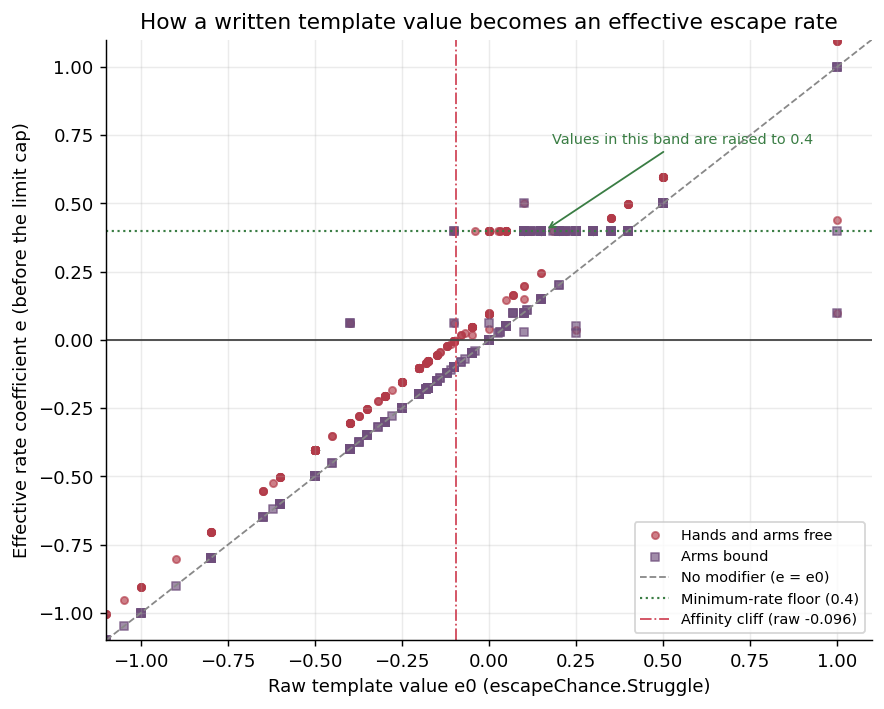

In [3]:
base = pd.DataFrame(DATA["baseline"])
probe = pd.DataFrame(DATA["probes"])
raw = {(r["name"], r["type"]): r["raw"] for r in DATA["baseline"]}
probe["raw"] = [raw.get((n, t), np.nan) for n, t in zip(probe.name, probe.type)]

fig, ax = plt.subplots(figsize=(7.6, 6.0))
for state, color, marker, label in (
    ("free", "#b23a48", "o", "Hands and arms free"),
    ("arms", "#6f4e7c", "s", "Arms bound"),
):
    x = probe[(probe.type == "Struggle") & (probe.state == state)]
    ax.scatter(x["raw"], x["e"], s=16, alpha=0.65, color=color, marker=marker, label=label)
ax.plot([-1.1, 1.1], [-1.1, 1.1], color="#888888", lw=1, ls="--", label="No modifier (e = e0)")
ax.axhline(0.4, color="#3a7d44", lw=1.2, ls=":", label="Minimum-rate floor (0.4)")
ax.axhline(0, color="#444444", lw=1)
ax.axvline(-0.096, color="#d1495b", lw=1, ls="-.", label="Affinity cliff (raw -0.096)")
ax.annotate("Values in this band are raised to 0.4", xy=(0.16, 0.4), xytext=(0.18, 0.72),
            fontsize=8, color="#3a7d44", arrowprops=dict(arrowstyle="->", color="#3a7d44", lw=1))
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
ax.set_xlabel("Raw template value e0 (escapeChance.Struggle)")
ax.set_ylabel("Effective rate coefficient e (before the limit cap)")
ax.set_title("How a written template value becomes an effective escape rate")
ax.legend(fontsize=8, loc="lower right")
plt.show()


## 5. One click is four ticks, not one roll

Figure 2 follows progress over time for three parameter settings. The fast case has e0 = 0.50 and lim = 0.05; the trap case has e0 = 0.20 and lim = 0.50; the no-progress case has e0 = -0.50. The line is the median across forty runs, and the band covers the 10th to 90th percentile. Progress is measured from 0 to 1; the dashed line at 1 is the escape condition.

The fast case reaches the threshold within three ticks, which is less than a single action. The trap case rises to about 0.53 and then stops: lim is larger than e, so the maximum reachable progress is 0.9 e / lim, and no amount of repetition moves it further. The no-progress case stays at zero because e is negative. The figure makes the central point visually: the engine is not producing a long sequence of independent failures; it is producing either a very short race or a hard stop.


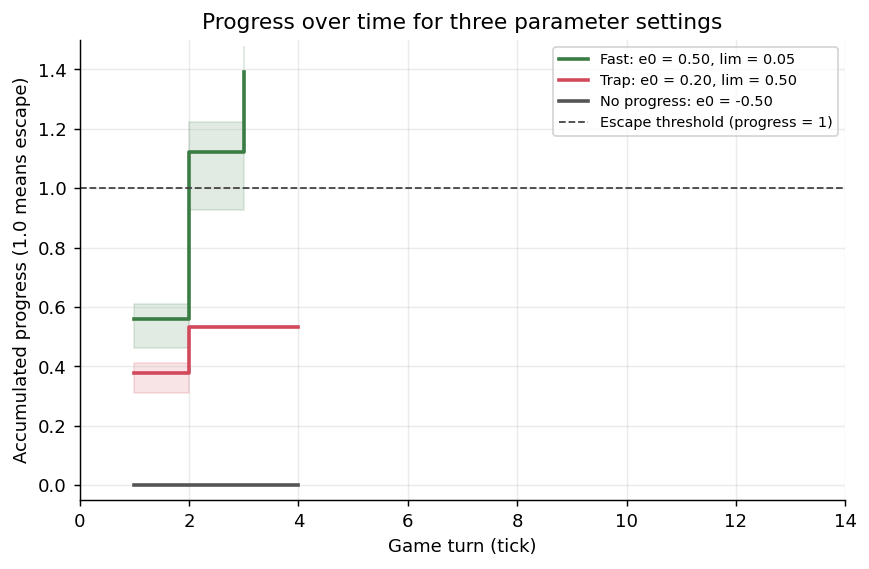

In [4]:
fig, ax = plt.subplots(figsize=(7.6, 4.6))
colors = {"fast": "#3a7d44", "trap": "#d1495b", "zero": "#555555"}
labels = {
    "fast": "Fast: e0 = 0.50, lim = 0.05",
    "trap": "Trap: e0 = 0.20, lim = 0.50",
    "zero": "No progress: e0 = -0.50",
}
for key in ("fast", "trap", "zero"):
    rows = DATA["trajectories"].get(key, [])
    if not rows:
        ax.axhline(0, color=colors[key], lw=2, label=labels[key])
        continue
    ts = [r["t"] for r in rows]
    ax.step(ts, [r["p50"] for r in rows], where="post", color=colors[key], lw=2, label=labels[key])
    ax.fill_between(ts, [r["p10"] for r in rows], [r["p90"] for r in rows], color=colors[key], alpha=0.15, step="post")
ax.axhline(1.0, color="#444444", lw=1, ls="--", label="Escape threshold (progress = 1)")
ax.set_xlim(0, 14); ax.set_ylim(-0.05, 1.5)
ax.set_xlabel("Game turn (tick)")
ax.set_ylabel("Accumulated progress (1.0 means escape)")
ax.set_title("Progress over time for three parameter settings")
ax.legend(fontsize=8)
plt.show()


## 6. The design space is a cliff, not a slope

Figure 3 sweeps e0 against lim. The left panel is the fraction of runs that escaped; the right panel is the median number of turns among all runs. The horizontal axis is e0, the vertical axis is lim, and colour encodes the outcome.

The left panel is almost binary. The dark region in the upper left is the limit trap: lim is larger than e, so the maximum progress is below 1 and no run escapes. Everywhere else the escape fraction is essentially 1. The right panel shows why the system does not feel like a probability: successful runs take one to four turns, and the only large values are the trapped runs that spend their budget before stopping. There is no broad middle region where the escape rate varies smoothly.


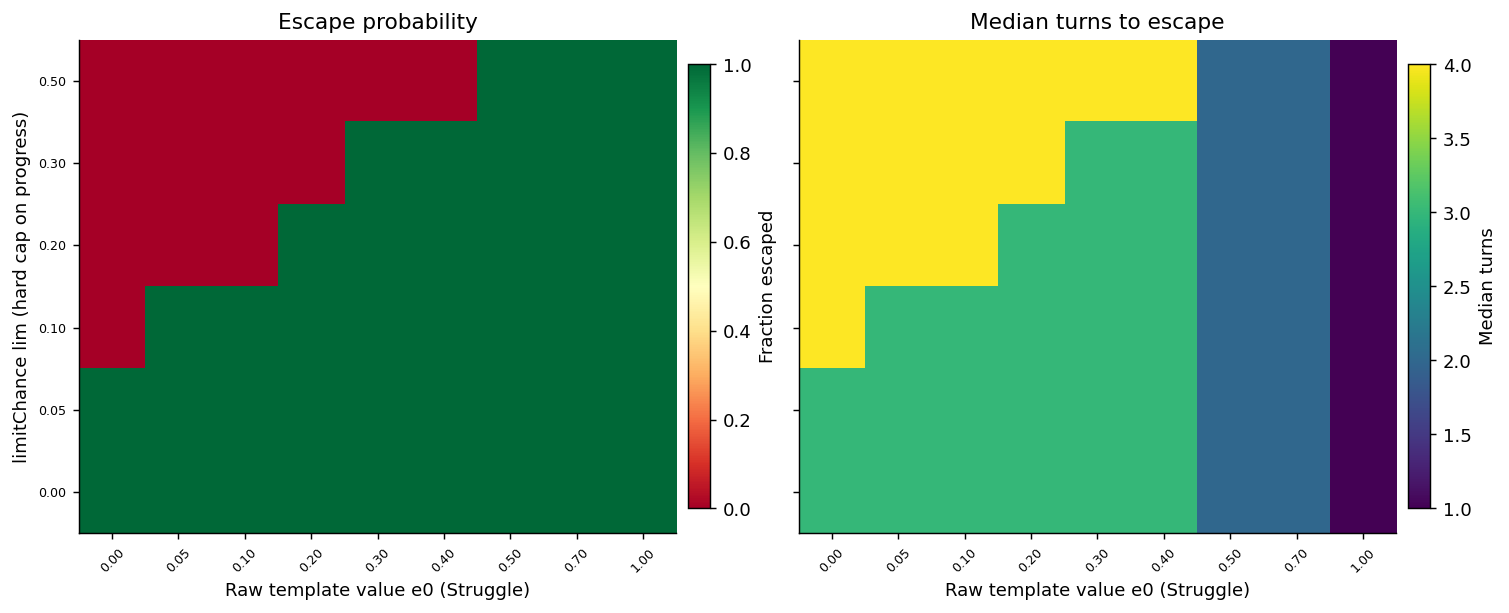

In [5]:
g = pd.DataFrame(DATA["grid"])
rate = g.pivot(index="lim", columns="e0", values="rate")
ticks = g.pivot(index="lim", columns="e0", values="median_ticks")
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharey=True, constrained_layout=True)
for ax, mat, title, cmap, vmin, vmax, cbar_label in (
    (axes[0], rate, "Escape probability", "RdYlGn", 0, 1, "Fraction escaped"),
    (axes[1], ticks, "Median turns to escape", "viridis", 1, 4, "Median turns"),
):
    im = ax.imshow(mat.values, origin="lower", aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(mat.columns))); ax.set_xticklabels([f"{v:.2f}" for v in mat.columns], rotation=45, fontsize=7)
    ax.set_yticks(range(len(mat.index))); ax.set_yticklabels([f"{v:.2f}" for v in mat.index], fontsize=7)
    ax.set_xlabel("Raw template value e0 (Struggle)")
    ax.set_title(title)
    cbar = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02, shrink=0.9)
    cbar.set_label(cbar_label)
    ax.grid(False)
axes[0].set_ylabel("limitChance lim (hard cap on progress)")
axes[1].set_ylabel("")
plt.show()


## 7. Remove is a different route with its own rules

Figure 4 repeats the exercise for Remove. The rows are the four body states, from free limbs to both hands and arms bound. The horizontal axis is the raw Remove value, and colour is the escape probability. Remove differs from Struggle in two ways: the hands and arms are part of the calculation, and distraction enters the same formula. The 0.4 floor still applies, but the bound states lose enough of the calculation that the cliff moves.

The figure is useful when a design wants "harder when restrained" rather than "impossible". Remove offers that gradient; Struggle does not, because Struggle deliberately ignores the arm and hand penalties.


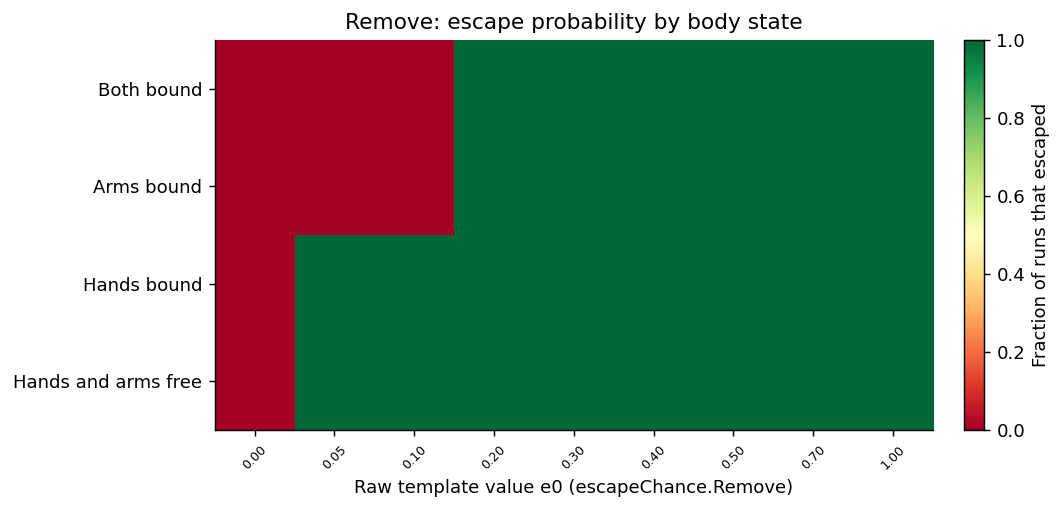

In [6]:
r = pd.DataFrame(DATA["remove"])
state_labels = {"free": "Hands and arms free", "hands": "Hands bound", "arms": "Arms bound", "both": "Both bound"}
piv = r.pivot(index="state", columns="e0", values="rate").reindex(["free", "hands", "arms", "both"])
piv.index = [state_labels[s] for s in piv.index]
fig, ax = plt.subplots(figsize=(7.8, 3.9))
im = ax.imshow(piv.values, origin="lower", aspect="auto", cmap="RdYlGn", vmin=0, vmax=1)
ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels([f"{v:.2f}" for v in piv.columns], rotation=45, fontsize=7)
ax.set_yticks(range(len(piv.index))); ax.set_yticklabels(piv.index)
ax.set_xlabel("Raw template value e0 (escapeChance.Remove)")
ax.set_title("Remove: escape probability by body state")
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Fraction of runs that escaped")
ax.grid(False)
plt.show()


## 8. Which factors change the number of turns

Figure 5 holds the parameters fixed at e0 = 0.50 and lim = 0.05 and changes one factor at a time for Struggle. The bars are median turns to escape. The first four bars are the body states: free, hands bound, arms bound, and both bound. The remaining bars vary tightness, distraction, restriction and will.

Two results matter for design. Hands do not affect Struggle at all, and arms add only one turn: Struggle is explicitly excluded from the arm and hand penalties, so binding the arms mainly removes the affinity bonus. Tightness and restriction each add a turn, and a very low will value adds several. Distraction has no effect, because it only enters the Remove, Cut, Pick and Unlock formulas. In other words, the factors that change feasibility and the factors that change pacing are different sets.


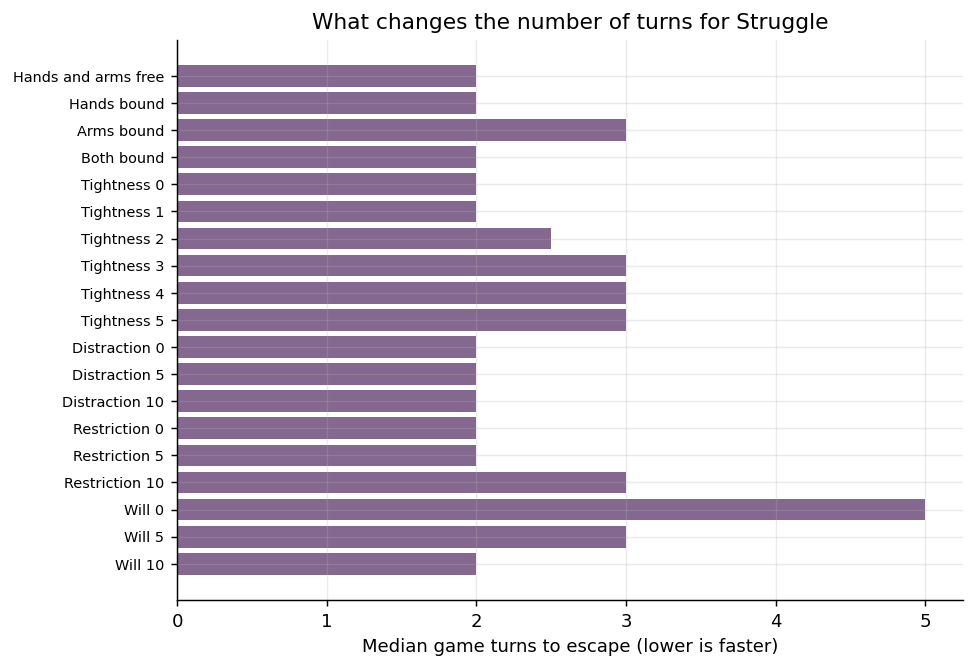

In [7]:
s = pd.DataFrame(DATA["sensitivity"])
label_map = {"free": "Hands and arms free", "hands": "Hands bound", "arms": "Arms bound", "both": "Both bound"}
for k in range(6):
    label_map[f"tightness={k}"] = f"Tightness {k}"
for d in (0, 5, 10):
    label_map[f"distraction={d}"] = f"Distraction {d}"
for r in (0, 5, 10):
    label_map[f"restriction={r}"] = f"Restriction {r}"
for w in (0, 5, 10):
    label_map[f"will={w}"] = f"Will {w}"
s["display"] = [label_map.get(x, x) for x in s["label"]]
fig, ax = plt.subplots(figsize=(7.8, 5.6))
ax.barh(range(len(s)), s["median_ticks"], color="#6f4e7c", alpha=0.85)
ax.set_yticks(range(len(s))); ax.set_yticklabels(s["display"], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Median game turns to escape (lower is faster)")
ax.set_title("What changes the number of turns for Struggle")
plt.show()


## 9. The shipped content is bimodal

Figure 6 shows the distribution of raw template values across all 486 restraints. The left panel is Struggle and the right panel is Remove. The vertical lines mark zero and the 0.4 floor. For Struggle, 318 values are at or below zero, 143 sit between zero and 0.4, and only 25 are at or above 0.4. Remove has a different shape, with a larger positive tail.

The middle band is not a designed difficulty range. Given the floor described in Section 4, most of those 143 values will behave like 0.4 in play. The histogram is therefore a picture of the content's intent and the engine's compression at the same time: the author wrote a spread, and the floor collapsed it.


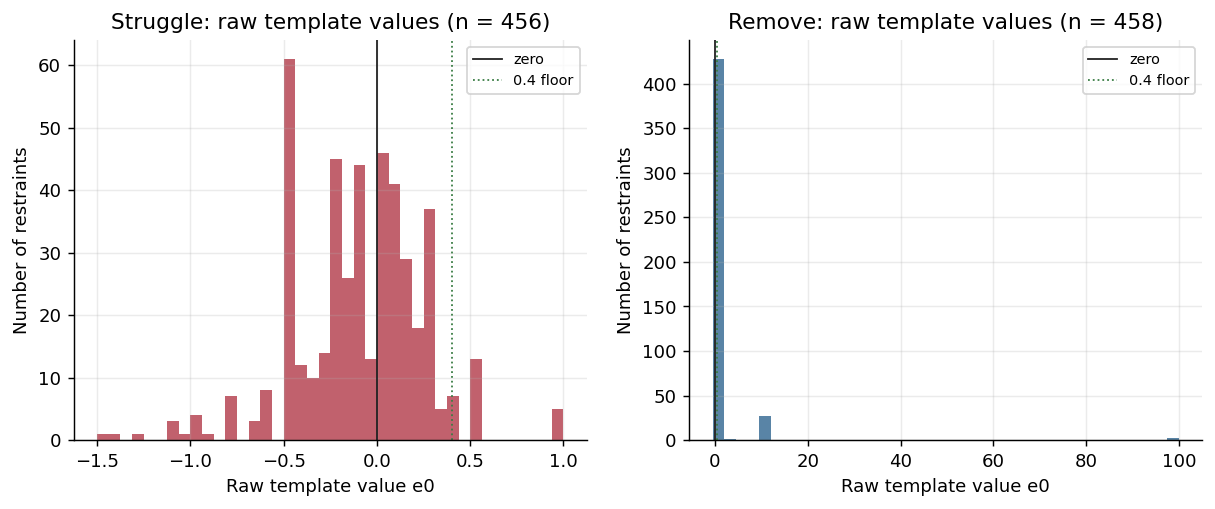

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.0))
for ax, typ, color in ((axes[0], "Struggle", "#b23a48"), (axes[1], "Remove", "#2f6690")):
    vals = [r["raw"] for r in DATA["baseline"] if r["type"] == typ and r["raw"] > -5]
    ax.hist(vals, bins=40, color=color, alpha=0.8)
    ax.axvline(0, color="#222222", lw=1, label="zero")
    ax.axvline(0.4, color="#3a7d44", lw=1, ls=":", label="0.4 floor")
    ax.set_title(f"{typ}: raw template values (n = {len(vals)})")
    ax.set_xlabel("Raw template value e0")
    ax.set_ylabel("Number of restraints")
    ax.legend(fontsize=8)
plt.show()


## 10. The same picture item by item

Figure 7 plots every shipped item as a point: the raw template value on the horizontal axis and the median turns to escape on the vertical axis. Struggle and Remove are shown in different colours. The vertical strip at one turn contains the items that are feasible; the strip at the top contains the items that never finish. Very little sits in between, which is the item-level counterpart of the bimodal histogram.

This is the most direct answer to the original question about why the model feels non-analytic. The engine is full of multiplicative modifiers, but after the floor and the limit trap, the visible result collapses into a small number of regimes. A design tool should therefore target those regimes, not try to tune a smooth probability.


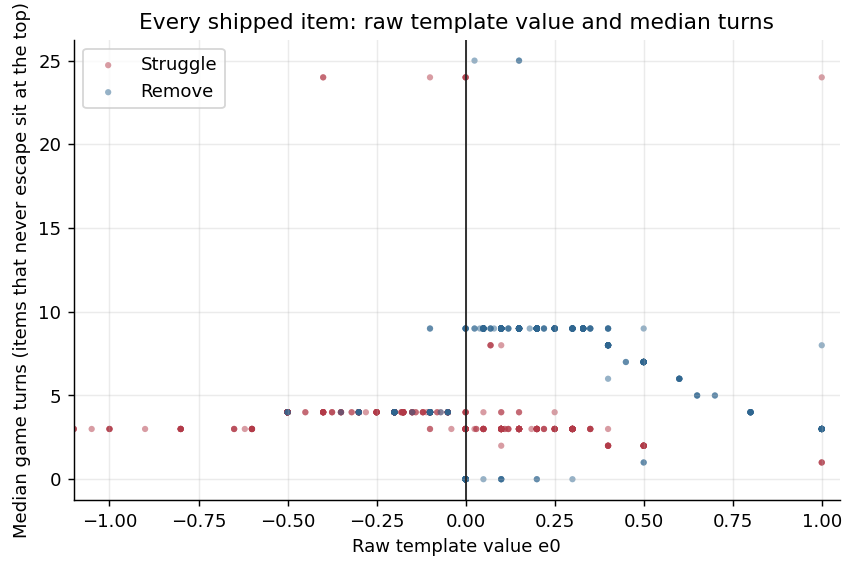

In [9]:
fig, ax = plt.subplots(figsize=(7.6, 4.6))
for typ, color in (("Struggle", "#b23a48"), ("Remove", "#2f6690")):
    x = base[base.type == typ]
    ax.scatter(x["raw"], x["median_ticks"], s=12, alpha=0.5, color=color, label=typ, edgecolors="none")
ax.axvline(0, color="#222222", lw=1)
ax.set_xlim(-1.1, 1.05)
ax.set_xlabel("Raw template value e0")
ax.set_ylabel("Median game turns (items that never escape sit at the top)")
ax.set_title("Every shipped item: raw template value and median turns")
ax.legend()
plt.show()


## 11. Turning the evidence into numbers

The table below states the design move and the reason, using the vocabulary from Section 1. The reasons refer to the mechanisms in Sections 4 to 8, not to intuition.

| Goal | What to change | Why it works |
| --- | --- | --- |
| Escape in one action | e0 at or above 0.4, and lim below e | The floor raises any value above lim to at least 0.4; one action is then enough. |
| Slow but still possible | struggleMinSpeed between 0.05 and 0.2, or speedMult below 1 | These are the only knobs that lower the floor or the speed without turning the attempt into a limit trap. |
| Stop at a visible percentage | lim above e | The maximum progress becomes 0.9 e / lim, so the attempt ends at Barely or Limit rather than succeeding. |
| Make it impossible | e0 at or below -0.096 with free limbs, or at or below 0 with bound limbs | Below the affinity cliff the effective rate stays non-positive, and the attempt cannot progress. |
| Make restraint matter | use Remove, Cut, Pick or Unlock | Struggle is explicitly excluded from the arm and hand penalties. |

The most common mistake is to treat e0 as a probability and write a small positive number to mean "hard". The floor erases that intent. The second most common mistake is to use lim as a probability; it is a hard cap, and a value above e removes the item from the feasible set entirely. A workable design process is to choose the regime first, then use the floor override and tightness for pacing, and finally check the result against the design-space figure.


## 12. Limits of this model

This is a single-item, single-wearer model. It turns off the event system, perks, goddess reputation, help and multi-item interactions. Those systems can change e, and the report in the analysis folder lists which ones were deliberately excluded and which ones remain open questions. The model also does not decay tightness; no implementation of ordinary struggling reducing tightness was found in the engine.

Pick and Unlock require a lock object; without one the engine returns Fail. The Cut weapon gate lives in the UI button layer, so a direct call can still make progress. The random source is a seeded PCG rather than the game's sfc32, which affects the sequence but not the distribution. Treat the figures as a map of the engine's regimes, not as a promise about a specific play session.
